# V3 pipeline - RESUME notebook (Conditional DDPM -> end of Phase 5)

Re-runs the **full** pipeline on a fresh Colab runtime using the checkpoints already on Drive, but **fast-forwards past work that was already completed** so you don't pay for it twice:

- Training (v2/v3 classifiers, restorers) loads from checkpoints via the existing resume-guards.
- **Stubbed** (already done, slow): Optuna HPO, knowledge distillation, and the Phase-3 SHAP/IG XAI benchmark + aggregation. The XAI results are reloaded from `xai_results.csv`.
- **CycleGAN is disabled** (removed from the enhancer list and build step).
- Everything from **Conditional DDPM through Phase 5** runs fresh and produces results.

**Usage:** GPU runtime -> Run all. First run still pays one-time data extraction + pip install.


# V3 PATCH MARKER (do not delete)

V3-extended notebook built by `build_v3.py` from version2. Adds:

- Step 7: pathology-preserving conditional DDPM (Phase 4 Diffusion #3) — classifier-feature perceptual loss + input-fidelity loss + sampling-time anti-hallucination clamp. New checkpoint `ddpm_pathology_v1.pt`, enhancer key `'ddpm_path'`.
- Step 8: hallucination detection report (grade-change / pixel-deviation / risk), saved to `phase4/metrics/ddpm_pathology_hallucination.csv`.

The vanilla DDPM (Step 4) is retained so the recovery table reports both DDPMs (vanilla vs pathology) as an ablation. All new training is resume-guarded.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q timm captum shap grad-cam scikit-image opencv-python-headless tabulate
!pip install -q diffusers transformers accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 153.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 44.3 MB/s eta 0:00:00


In [3]:
from pathlib import Path
import zipfile

# ----- Drive (input + persistent output) -----
DRIVE_ROOT      = Path('/content/drive/MyDrive/Thesis')
THESIS_ZIP      = DRIVE_ROOT / 'Thesis.zip'          # single outer zip
RESULTS_ROOT    = DRIVE_ROOT / 'results'
CHECKPOINTS_DIR = DRIVE_ROOT / 'checkpoints'

In [4]:
LOCAL_ROOT   = Path('/content/data')
APTOS_DIR    = LOCAL_ROOT / 'aptos'
EYEQ_DIR     = LOCAL_ROOT / 'eyeq'
PRISTINE_DIR = LOCAL_ROOT / 'pristine'
DEGRADED_DIR = LOCAL_ROOT / 'degraded'
ENHANCED_DIR = LOCAL_ROOT / 'enhanced'

PHASE_DIRS = {
    'phase1_data_engineering':   RESULTS_ROOT / 'phase1_data_engineering',
    'phase2_model_benchmarking': RESULTS_ROOT / 'phase2_model_benchmarking',
    'phase3_xai_benchmark':      RESULTS_ROOT / 'phase3_xai_benchmark',
    'phase4_genai_enhancement':  RESULTS_ROOT / 'phase4_genai_enhancement',
    'phase5_quality_ensemble':   RESULTS_ROOT / 'phase5_quality_ensemble',
}
PHASE_SUBDIRS = ('metrics', 'plots', 'samples', 'logs')

In [5]:
for p in [LOCAL_ROOT, PRISTINE_DIR, DEGRADED_DIR, ENHANCED_DIR,
          RESULTS_ROOT, CHECKPOINTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)
for phase_dir in PHASE_DIRS.values():
    for sub in PHASE_SUBDIRS:
        (phase_dir / sub).mkdir(parents=True, exist_ok=True)

print('Drive zip   :', THESIS_ZIP, '(exists:', THESIS_ZIP.exists(), ')')
print('Drive results tree:')
for k, v in PHASE_DIRS.items():
    print(f'  {k:35s} -> {v}')

Drive zip   : /content/drive/MyDrive/Thesis/Thesis.zip (exists: True )
Drive results tree:
  phase1_data_engineering             -> /content/drive/MyDrive/Thesis/results/phase1_data_engineering
  phase2_model_benchmarking           -> /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking
  phase3_xai_benchmark                -> /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark
  phase4_genai_enhancement            -> /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement
  phase5_quality_ensemble             -> /content/drive/MyDrive/Thesis/results/phase5_quality_ensemble


In [6]:
# Idempotent extraction — skips automatically if already done in this Colab session.
# Saves 5-15 minutes per reconnect. Force re-extract: smart_extract(force=True).
import zipfile, shutil, time

EXTRACT_MARK = LOCAL_ROOT / ".extracted_ok"        # sentinel file


def _has_data():
    if not EXTRACT_MARK.exists():
        return False
    has_aptos = any(APTOS_DIR.rglob("*.png")) or any(APTOS_DIR.rglob("*.jpg"))
    has_eyeq  = any(EYEQ_DIR.rglob("*.png"))  or any(EYEQ_DIR.rglob("*.jpg"))
    return has_aptos and has_eyeq


def _find_dir(root: Path, keywords):
    for p in root.rglob("*"):
        if p.is_dir() and any(k in p.name.lower() for k in keywords):
            return p
    return None


def smart_extract(force: bool = False):
    """Extract Thesis.zip -> /content/data, then recursively unpack inner zips.
    Skips if a previous extraction is still in place."""
    LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
    if _has_data() and not force:
        n_aptos = sum(1 for _ in APTOS_DIR.rglob("*.*"))
        n_eyeq  = sum(1 for _ in EYEQ_DIR.rglob("*.*"))
        print(f"[skip] data already extracted (aptos={n_aptos}, eyeq={n_eyeq})")
        return

    if not THESIS_ZIP.exists():
        raise FileNotFoundError(f"Missing zip: {THESIS_ZIP}")

    t0 = time.time()
    print(f"[extract] {THESIS_ZIP.name} -> {LOCAL_ROOT}")
    with zipfile.ZipFile(THESIS_ZIP) as z:
        z.extractall(LOCAL_ROOT)

    while True:
        inners = list(LOCAL_ROOT.rglob("*.zip"))
        if not inners:
            break
        for iz in inners:
            target = iz.parent / iz.stem
            target.mkdir(exist_ok=True)
            print(f"  inner zip: {iz.name} -> {target}")
            with zipfile.ZipFile(iz) as z:
                z.extractall(target)
            iz.unlink()

    # Symlink canonical paths
    aptos_src = _find_dir(LOCAL_ROOT, ["aptos"])
    eyeq_src  = _find_dir(LOCAL_ROOT, ["eyeq", "eye_q", "eye-q"])
    print("Detected APTOS dir:", aptos_src)
    print("Detected EyeQ  dir:", eyeq_src)
    for canonical, real in [(APTOS_DIR, aptos_src), (EYEQ_DIR, eyeq_src)]:
        if real is None:
            print(f"[warn] {canonical.name} not found — check Thesis.zip contents")
            continue
        if canonical.exists() and canonical.resolve() != real.resolve():
            if canonical.is_dir() and not canonical.is_symlink():
                shutil.rmtree(canonical)
            else:
                canonical.unlink()
        if not canonical.exists():
            canonical.symlink_to(real, target_is_directory=True)
        print(f"  {canonical} -> {real}")

    EXTRACT_MARK.touch()
    print(f"[extract] done in {time.time()-t0:.1f}s")


smart_extract()         # subsequent calls in this session are instant


[extract] Thesis.zip -> /content/data
  inner zip: train_images.zip -> /content/data/Thesis/APTOS/train_images
  inner zip: test_images.zip -> /content/data/Thesis/APTOS/test_images
  inner zip: val_images.zip -> /content/data/Thesis/APTOS/val_images
  inner zip: test_images_768.zip -> /content/data/Thesis/EYEQ/test_images_768
  inner zip: train_images_768.zip -> /content/data/Thesis/EYEQ/train_images_768
Detected APTOS dir: /content/data/Thesis/APTOS
Detected EyeQ  dir: /content/data/Thesis/EYEQ
  /content/data/aptos -> /content/data/Thesis/APTOS
  /content/data/eyeq -> /content/data/Thesis/EYEQ
[extract] done in 4262.9s


In [7]:
def show_tree(root: Path, max_depth: int = 3):
    root = Path(root)
    for p in sorted(root.rglob('*')):
        depth = len(p.relative_to(root).parts)
        if depth > max_depth: continue
        kind = '/' if p.is_dir() else ''
        print(f'{"  "*(depth-1)}{p.name}{kind}')

print('=== APTOS ==='); show_tree(APTOS_DIR, max_depth=2)
print('\n=== EYEQ  ==='); show_tree(EYEQ_DIR,  max_depth=2)

=== APTOS ===
test.csv
test_images/
  test_images/
train_1.csv
train_images/
  train_images/
val_images/
  val_images/
valid.csv

=== EYEQ  ===
Label_EyeQ_test.csv
Label_EyeQ_train.csv
test_images_768/
  test/
train_images_768/
  train/


In [8]:
import torch
PHASE_DIRS = {
    'phase1_data_engineering':   RESULTS_ROOT / 'phase1_data_engineering',
    'phase2_model_benchmarking': RESULTS_ROOT / 'phase2_model_benchmarking',
    'phase3_xai_benchmark':      RESULTS_ROOT / 'phase3_xai_benchmark',
    'phase4_genai_enhancement':  RESULTS_ROOT / 'phase4_genai_enhancement',
    'phase5_quality_ensemble':   RESULTS_ROOT / 'phase5_quality_ensemble',
}
for p in [DEGRADED_DIR, ENHANCED_DIR, RESULTS_ROOT, CHECKPOINTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)
for d in PHASE_DIRS.values():
    for sub in ('metrics', 'plots', 'samples', 'logs'):
        (d / sub).mkdir(parents=True, exist_ok=True)

# Auto-detect APTOS train CSV + image dir (case-insensitive)
APTOS_CSV    = next(p for p in APTOS_DIR.rglob('*.csv') if 'train' in p.name.lower())
APTOS_IMAGES = next(p for p in APTOS_DIR.rglob('*train_images*') if p.is_dir())
EYEQ_CSV     = next(EYEQ_DIR.rglob('*.csv'), None)

# Common constants
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
IMAGE_SIZE  = 224
SEED        = 42
VAL_SPLIT, TEST_SPLIT = 0.15, 0.15

MODEL_NAMES = ('resnet50', 'efficientnet_b3', 'vit_base')
TIMM_NAMES  = {'resnet50': 'resnet50',
               'efficientnet_b3': 'efficientnet_b3',
               'vit_base': 'vit_base_patch16_224'}
TRAIN_CFG = dict(batch_size=32, num_workers=2, epochs=15,
                 lr=3e-4, weight_decay=1e-4, label_smoothing=0.05,
                 mixed_precision=True)

DEGRADATION_TYPES  = ('blur', 'exposure', 'noise')
DEGRADATION_LEVELS = ('low', 'mid', 'high')
DEGRADATION_PARAMS = {
    'blur':     {'low': 2.0,  'mid': 5.0,  'high': 9.0},
    'exposure': {'low': 0.7,  'mid': 0.4,  'high': 0.2},
    'noise':    {'low': 0.02, 'mid': 0.06, 'high': 0.12},
}
EYEQ_QUALITY_LABELS = {0: 'good', 1: 'usable', 2: 'reject'}

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('APTOS csv   :', APTOS_CSV)
print('APTOS images:', APTOS_IMAGES)
print('EyeQ csv    :', EYEQ_CSV)
print('Device      :', DEVICE)

APTOS csv   : /content/data/aptos/train_1.csv
APTOS images: /content/data/aptos/train_images
EyeQ csv    : /content/data/eyeq/Label_EyeQ_train.csv
Device      : cuda


In [9]:
import json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torch.cuda.amp import GradScaler, autocast
from torchvision import transforms as T
import timm
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from scipy.stats import spearmanr
from skimage.segmentation import slic

TFM_TRAIN = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
                        T.RandomHorizontalFlip(),
                        T.RandomRotation(15),
                        T.ColorJitter(0.1, 0.1, 0.1),
                        T.ToTensor(),
                        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
TFM_EVAL  = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
                        T.ToTensor(),
                        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def load_tensor(path: Path) -> torch.Tensor:
    return TFM_EVAL(Image.open(path).convert('RGB')).unsqueeze(0).to(DEVICE)

In [10]:
class APTOSDataset(Dataset):
    """Resolves images via IMAGE_INDEX so any extension / nested layout works."""
    def __init__(self, csv_path, images_dir, transform):
        self.df = pd.read_csv(csv_path)
        self.images_dir = Path(images_dir)   # kept for API compatibility, not used
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(resolve_image(row['id_code'])).convert('RGB')
        return self.transform(img), int(row['diagnosis']), row['id_code']

class FolderDataset(Dataset):
    """Reads `<root>/manifest.csv` (cols: id_code, diagnosis, rel_path)."""
    def __init__(self, root, transform=TFM_EVAL):
        self.root = Path(root); self.df = pd.read_csv(self.root / 'manifest.csv')
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(self.root / row['rel_path']).convert('RGB')
        return self.transform(img), int(row['diagnosis']), row['id_code']

In [11]:
# === Improved training infrastructure ===
import math
from contextlib import contextmanager
from collections import Counter
from torch.utils.data import WeightedRandomSampler, Subset
from sklearn.model_selection import train_test_split

# 1) STRATIFIED SPLIT — keeps class proportions consistent across train/val/test
def stratified_split_indices(labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    idx = np.arange(len(labels)); labels = np.array(labels)
    tr_idx, te_idx = train_test_split(idx, test_size=test_frac, stratify=labels, random_state=seed)
    rel_val = val_frac / (1 - test_frac)
    tr_idx, va_idx = train_test_split(tr_idx, test_size=rel_val,
                                       stratify=labels[tr_idx], random_state=seed)
    return tr_idx.tolist(), va_idx.tolist(), te_idx.tolist()

# 2) CLASS WEIGHTS + BALANCED SAMPLER
def class_weights_tensor(labels, num_classes=NUM_CLASSES):
    cnt = Counter(labels); n = sum(cnt.values())
    return torch.tensor([n / (num_classes * max(cnt.get(i, 0), 1)) for i in range(num_classes)],
                         dtype=torch.float)

def balanced_sampler(labels):
    cnt = Counter(labels)
    w = [1.0 / cnt[l] for l in labels]
    return WeightedRandomSampler(w, num_samples=len(w), replacement=True)

# 3) FOCAL LOSS (handles soft targets from MixUp + per-class weights)
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.0):
        super().__init__(); self.gamma, self.alpha, self.ls = gamma, alpha, label_smoothing
    def forward(self, logits, targets):
        if targets.dim() > 1:                       # soft labels (MixUp)
            log_p = F.log_softmax(logits, dim=-1)
            return -(targets * log_p).sum(-1).mean()
        ce = F.cross_entropy(logits, targets, weight=self.alpha,
                              reduction='none', label_smoothing=self.ls)
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()

# 4) EMA — exponential moving average of weights, +0.5–1% reliably
class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}
    def update(self, model):
        with torch.no_grad():
            for n, p in model.named_parameters():
                if p.requires_grad:
                    self.shadow[n].mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)
    @contextmanager
    def applied(self, model):
        backup = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}
        for n, p in model.named_parameters():
            if p.requires_grad: p.data.copy_(self.shadow[n])
        try: yield
        finally:
            for n, p in model.named_parameters():
                if p.requires_grad: p.data.copy_(backup[n])

# 5) STRONG TRAIN AUGMENTATION (medical-imaging safe — no extreme hue shifts)
TFM_TRAIN_STRONG = T.Compose([
    T.Resize((IMAGE_SIZE + 32, IMAGE_SIZE + 32)),
    T.RandomCrop(IMAGE_SIZE),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(25),
    T.RandAugment(num_ops=2, magnitude=7),
    T.ColorJitter(0.15, 0.15, 0.15, 0.03),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.25),
])

# 6) MIXUP / CUTMIX (timm's implementation)
from timm.data import Mixup

# 7) LAYER-WISE LR DECAY (LRD) — critical for ViT fine-tuning
def vit_lrd_param_groups(model, base_lr, decay=0.75, weight_decay=5e-2):
    n_layers = len(model.blocks) + 1
    groups = []
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        if n.startswith('head'):                                  depth = n_layers
        elif n.startswith('blocks'):                              depth = int(n.split('.')[1])
        elif any(n.startswith(s) for s in
                 ('patch_embed', 'cls_token', 'pos_embed', 'norm')): depth = 0
        else:                                                     depth = 0
        lr_scale = decay ** (n_layers - depth)
        groups.append({'params': p, 'lr': base_lr * lr_scale,
                       'weight_decay': 0.0 if p.ndim <= 1 else weight_decay})
    return groups

# 8) WARMUP + COSINE LR SCHEDULE
def warmup_cosine(optimizer, warmup_epochs, total_epochs, steps_per_epoch):
    def lr_lambda(step):
        epoch = step / max(steps_per_epoch, 1)
        if epoch < warmup_epochs:
            return epoch / max(warmup_epochs, 1)
        prog = (epoch - warmup_epochs) / max(total_epochs - warmup_epochs, 1)
        return 0.5 * (1 + math.cos(math.pi * min(prog, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# 9) PER-ARCHITECTURE HYPERPARAMETERS
HPARAMS = {
    'resnet50':        dict(lr=3e-4, wd=1e-4, epochs=25, mixup=0.2, ls=0.1, gamma=1.5, warmup=3, llrd=None),
    'efficientnet_b3': dict(lr=2e-4, wd=1e-5, epochs=25, mixup=0.2, ls=0.1, gamma=2.0, warmup=3, llrd=None),
    'vit_base':        dict(lr=5e-5, wd=5e-2, epochs=30, mixup=0.4, ls=0.1, gamma=2.0, warmup=5, llrd=0.75),
}

print('Improved training infrastructure loaded.')

Improved training infrastructure loaded.


In [12]:
def find_in_folder(folder, id_code, exts=('.jpg', '.png', '.jpeg')):
    """Return the actual file path for id_code in folder, regardless of extension."""
    for ext in exts:
        p = Path(folder) / f'{id_code}{ext}'
        if p.exists():
            return p
    raise FileNotFoundError(f'{id_code} not found in {folder} (tried {exts})')

In [13]:
def build_model(name, pretrained=True):
    m = timm.create_model(TIMM_NAMES[name], pretrained=pretrained, num_classes=NUM_CLASSES)
    m._dr_arch = name
    return m

def load_classifier(name):
    m = build_model(name, pretrained=False).to(DEVICE)
    state = torch.load(CHECKPOINTS_DIR / f'{name}_best.pt', map_location=DEVICE, weights_only=False)
    m.load_state_dict(state['state_dict']); m.eval()
    return m

def get_xai_target_layer(model):
    a = model._dr_arch
    if a == 'resnet50':        return model.layer4[-1]
    if a == 'efficientnet_b3': return model.blocks[-1]
    if a == 'vit_base':        return model.blocks[-1].norm1
    raise ValueError(a)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); ys, ps, probs = [], [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        prob = torch.softmax(model(x), 1).cpu().numpy()
        probs.append(prob); ps.append(prob.argmax(1)); ys.append(y.numpy())
    y = np.concatenate(ys); p = np.concatenate(ps); pr = np.concatenate(probs)
    out = {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, average='macro')}
    try: out['auc_macro_ovr'] = roc_auc_score(y, pr, average='macro', multi_class='ovr')
    except ValueError: out['auc_macro_ovr'] = float('nan')
    return out

def train_one(model, train_loader, val_loader, ckpt_path, history_csv,
              epochs=TRAIN_CFG['epochs'], lr=TRAIN_CFG['lr'],
              wd=TRAIN_CFG['weight_decay'], ls=TRAIN_CFG['label_smoothing'],
              amp=TRAIN_CFG['mixed_precision']):
    model = model.to(DEVICE)
    optim  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched  = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epochs)
    crit   = nn.CrossEntropyLoss(label_smoothing=ls)
    scaler = GradScaler(enabled=amp)
    best_f1, history = -1.0, []
    for ep in range(epochs):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f'epoch {ep+1}/{epochs}', leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=amp):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(optim); scaler.update()
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen)
        sched.step()
        m = evaluate(model, val_loader)
        history.append({'epoch': ep+1, 'train_loss': running/seen, **m})
        print(f'  val: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}  auc={m["auc_macro_ovr"]:.4f}')
        if m['f1_macro'] > best_f1:
            best_f1 = m['f1_macro']
            torch.save({'state_dict': model.state_dict(), 'arch': model._dr_arch, 'val': m}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)

In [14]:
def gradcam_heatmap(model, x, target_class=None):
    layer = get_xai_target_layer(model)
    acts, grads = {}, {}
    h1 = layer.register_forward_hook(lambda _, __, o: acts.update(v=o.detach()))
    h2 = layer.register_full_backward_hook(lambda _, gi, go: grads.update(v=go[0].detach()))
    try:
        model.zero_grad(set_to_none=True)
        x = x.clone().requires_grad_(True)
        logits = model(x)
        if target_class is None:
            target_class = int(logits.argmax(1).item())
        logits[0, target_class].backward()
        a, g = acts['v'][0], grads['v'][0]
        cam = torch.relu((g.mean(dim=(1, 2))[:, None, None] * a).sum(0))
        cam -= cam.min()
        if cam.max() > 0: cam /= cam.max()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear', align_corners=False)
        return cam.squeeze().detach().cpu().numpy()
    finally:
        h1.remove(); h2.remove()

@torch.no_grad()
def attention_rollout(model, x, target_class=None):
    attns, handles = [], []
    for blk in model.blocks:
        attn_module = blk.attn
        def make_hook(store, mod):
            def _h(module, inp, out):
                B, N, C = inp[0].shape
                qkv = mod.qkv(inp[0]).reshape(B, N, 3, mod.num_heads, C // mod.num_heads).permute(2, 0, 3, 1, 4)
                q, k, _ = qkv[0], qkv[1], qkv[2]
                a = (q @ k.transpose(-2, -1)) * mod.scale
                store.append(a.softmax(-1).detach())
            return _h
        handles.append(attn_module.register_forward_hook(make_hook(attns, attn_module)))
    try: _ = model(x)
    finally:
        for h in handles: h.remove()
    res = None
    for a in attns:
        a = a.mean(1) + torch.eye(a.size(-1), device=a.device)
        a = a / a.sum(-1, keepdim=True)
        res = a if res is None else a @ res
    cls = res[0, 0, 1:]; side = int(cls.numel() ** 0.5)
    h = F.interpolate(cls.reshape(side, side)[None, None],
                       size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze().cpu().numpy()
    if h.max() > h.min(): h = (h - h.min()) / (h.max() - h.min())
    return h

def shap_heatmap(model, x, target_class=None, n_samples=60, n_segments=40):
    import shap
    img = x.squeeze(0).permute(1, 2, 0).cpu().numpy()
    seg = slic(img, n_segments=n_segments, compactness=10, start_label=0)
    def f(masks):
        out = np.zeros((masks.shape[0], NUM_CLASSES), dtype=np.float32)
        for i, m in enumerate(masks):
            keep = np.isin(seg, np.where(m == 1)[0])
            masked = img.copy(); masked[~keep] = img.mean(axis=(0, 1))
            t = torch.tensor(masked).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
            with torch.no_grad():
                out[i] = torch.softmax(model(t), 1).cpu().numpy()[0]
        return out
    n_super = int(seg.max() + 1)
    explainer = shap.KernelExplainer(f, np.zeros((1, n_super)))
    sv = explainer.shap_values(np.ones((1, n_super)), nsamples=n_samples)
    if target_class is None:
        with torch.no_grad():
            target_class = int(model(x).argmax(1).item())
    sv = sv[target_class][0]
    heat = np.zeros(seg.shape, dtype=np.float32)
    for sid, val in enumerate(sv):
        heat[seg == sid] = val
    if heat.max() > heat.min():
        heat = (heat - heat.min()) / (heat.max() - heat.min())
    return heat

In [15]:
@torch.no_grad()
def _prob_for(model, x, cls): return torch.softmax(model(x), 1)[0, cls].item()

def deletion_auc(model, x, heatmap, target_class, steps=30):
    H, W = heatmap.shape
    order = np.argsort(-heatmap.flatten())
    chunk = max(1, len(order) // steps)
    mean_pix = x.mean(dim=(2, 3), keepdim=True)
    probs = []
    for s in range(steps + 1):
        idx = order[: s * chunk]
        rows, cols = np.unravel_index(idx, (H, W))
        x_mod = x.clone()
        x_mod[0, :, rows, cols] = mean_pix.expand_as(x)[0, :, rows, cols]
        probs.append(_prob_for(model, x_mod, target_class))
    return float(np.trapezoid(probs, dx=1/steps))

def insertion_auc(model, x, heatmap, target_class, steps=30):
    H, W = heatmap.shape
    order = np.argsort(-heatmap.flatten())
    chunk = max(1, len(order) // steps)
    base = F.avg_pool2d(x, 15, stride=1, padding=7)
    probs = []
    for s in range(steps + 1):
        idx = order[: s * chunk]
        rows, cols = np.unravel_index(idx, (H, W))
        x_mod = base.clone(); x_mod[0, :, rows, cols] = x[0, :, rows, cols]
        probs.append(_prob_for(model, x_mod, target_class))
    return float(np.trapezoid(probs, dx=1/steps))

def stability_spearman(h1, h2):
    rho, _ = spearmanr(h1.flatten(), h2.flatten())
    return float(rho) if rho == rho else 0.0

def localization_iou(heatmap, mask, percentile=80):
    if mask is None: return float('nan')
    thr  = np.percentile(heatmap, percentile)
    pred = heatmap >= thr
    inter = np.logical_and(pred, mask).sum()
    union = np.logical_or(pred, mask).sum()
    return float(inter/union) if union > 0 else float('nan')

**DATA ENGINEERING**

In [16]:
P1 = PHASE_DIRS['phase1_data_engineering']

# 1.1 V2 PATCH — phantom EyeQ filter removed.
# The original filter_pristine() tried to join EyeQ quality labels onto APTOS
# but the join key never matched in any observed Colab run — the routine
# silently fell back to "use all APTOS rows". To keep the methodology honest
# we now explicitly use the full APTOS dataset and document "APTOS only" in
# the dissertation. EyeQ is still loaded separately for the Phase 5 quality
# classifier training (Q_CKPT).
def filter_pristine(aptos_csv, eyeq_csv=None, out_csv=None, **kwargs):
    """V2 patch: always returns the full APTOS dataset."""
    aptos = pd.read_csv(aptos_csv)
    if out_csv is not None:
        aptos.to_csv(out_csv, index=False)
    return aptos

PRISTINE_CSV = P1 / 'metrics' / 'pristine_split.csv'
pristine_df = filter_pristine(APTOS_CSV, EYEQ_CSV, PRISTINE_CSV)
print(f'Using full APTOS dataset: {len(pristine_df)} images')
pristine_df.head()


Using full APTOS dataset: 2930 images


,id_code,diagnosis
0,1ae8c165fd53,2
1,1b329a127307,1
2,1b32e1d775ea,4
3,1b3647865779,0
4,1b398c0494d1,0


In [17]:
# Diagnose the actual APTOS image layout
print('APTOS_IMAGES :', APTOS_IMAGES)
print('Exists?       :', APTOS_IMAGES.exists())
all_files = list(APTOS_IMAGES.rglob('*'))
img_files = [p for p in all_files if p.is_file() and p.suffix.lower() in ('.png', '.jpg', '.jpeg')]
print(f'Total files under APTOS_IMAGES (any depth): {len(all_files)}')
print(f'Image files found                          : {len(img_files)}')
if img_files:
    print('Sample image paths:')
    for p in img_files[:5]:
        print(' ', p.relative_to(APTOS_IMAGES))
print('\nSample id_code from CSV:', pristine_df["id_code"].iloc[0])
print('Sample image stem      :', img_files[0].stem if img_files else '(none)')

APTOS_IMAGES : /content/data/aptos/train_images
Exists?       : True
Total files under APTOS_IMAGES (any depth): 2934
Image files found                          : 2930
Sample image paths:
  train_images/8d7bb0649a02.png
  train_images/8c4ceddeb1c6.png
  train_images/441affbe99aa.png
  train_images/dd3176bacfe2.png
  train_images/6bcce181be65.png

Sample id_code from CSV: 1ae8c165fd53
Sample image stem      : 8d7bb0649a02


In [18]:
# Build a stem -> path index so we don't care about extension or subfolder depth.
# Searches all of APTOS_DIR (not just APTOS_IMAGES) in case auto-detection picked the wrong folder.
print('Indexing APTOS images...')
IMAGE_INDEX = {}
for p in APTOS_DIR.rglob('*'):
    if p.is_file() and p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.tif', '.tiff'):
        IMAGE_INDEX[p.stem] = p
print(f'Indexed {len(IMAGE_INDEX)} images.')

# Sanity check against the CSV
csv_ids = pristine_df['id_code'].astype(str).tolist()
matched = [i for i in csv_ids if i in IMAGE_INDEX]
missing = [i for i in csv_ids if i not in IMAGE_INDEX]
print(f'CSV ids matched: {len(matched)}/{len(csv_ids)}')
if missing:
    print(f'Example missing id: {missing[0]}')
    print('Example indexed stems:', list(IMAGE_INDEX)[:3])
    raise SystemExit('CSV ids do not match image filenames — inspect the diagnostic output above.')

def resolve_image(id_code):
    """Get the actual image path for an APTOS id_code, regardless of extension or folder."""
    p = IMAGE_INDEX.get(str(id_code))
    if p is None:
        raise FileNotFoundError(f'No image indexed for id_code={id_code!r}')
    return p

Indexing APTOS images...
Indexed 3662 images.
CSV ids matched: 2930/2930


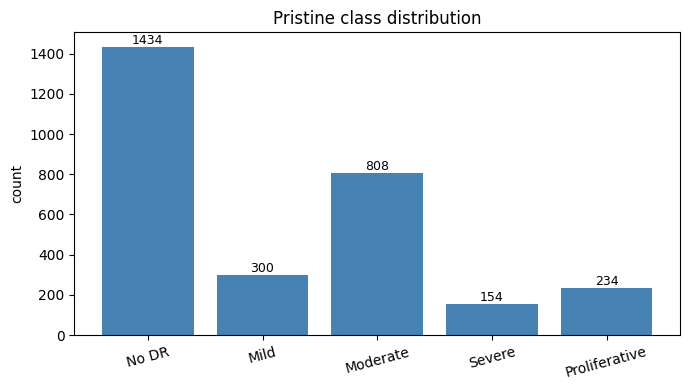

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/plots/class_distribution.png


In [19]:
# 1.2 Class-balance plot
counts = pristine_df['diagnosis'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([CLASS_NAMES[i] for i in counts.index], counts.values, color='steelblue')
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v, str(v), ha='center', va='bottom', fontsize=9)
ax.set_title('Pristine class distribution'); ax.set_ylabel('count')
plt.xticks(rotation=15); plt.tight_layout()
out = P1 / 'plots' / 'class_distribution.png'
plt.savefig(out, dpi=150); plt.show()
print('Saved:', out)

In [20]:
# 1.3 Synthetic degradation primitives
def _np(img):  return np.array(img.convert('RGB'))
def _pil(arr): return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

def gaussian_blur(img, sigma):
    k = max(3, int(2 * round(3 * sigma) + 1))
    return _pil(cv2.GaussianBlur(_np(img), (k, k), sigmaX=sigma, sigmaY=sigma))

def exposure_shift(img, gain): return _pil(_np(img).astype(np.float32) * gain)
def gaussian_noise(img, std_frac):
    arr = _np(img).astype(np.float32)
    return _pil(arr + np.random.normal(0, std_frac * 255, arr.shape))

DEGRADERS = {'blur': gaussian_blur, 'exposure': exposure_shift, 'noise': gaussian_noise}
def apply_degradation(img, kind, level):
    return DEGRADERS[kind](img, DEGRADATION_PARAMS[kind][level])

In [21]:
!du -sh /content/data/* 2>/dev/null
!df -h /content

0	/content/data/aptos
4.0K	/content/data/degraded
4.0K	/content/data/enhanced
0	/content/data/eyeq
4.0K	/content/data/pristine
98G	/content/data/Thesis
Filesystem      Size  Used Avail Use% Mounted on
overlay         236G  145G   92G  62% /


In [22]:
import shutil

# Use rm -rf for a more forceful deletion to handle potential disk full issues
# or lingering file handles.
!rm -rf {DEGRADED_DIR}

# Ensure the base directory exists before recreating subdirectories.
DEGRADED_DIR.mkdir(parents=True, exist_ok=True)

# Check disk space after deletion to confirm space is freed.
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         236G  145G   92G  62% /


In [23]:
# [RESUME GUARD] Skip if degraded images already exist on local disk or Drive cache.
import shutil as _sh

_degraded_present = (
    DEGRADED_DIR.exists()
    and any((DEGRADED_DIR / k / l / "manifest.csv").exists()
            for k in DEGRADATION_TYPES for l in DEGRADATION_LEVELS)
)

# Auto-restore from Drive cache if local disk is empty but cache exists
_deg_cache = DRIVE_ROOT / "cache_degraded.tar.gz"
if not _degraded_present and _deg_cache.exists():
    print(f"[restore] Pulling degraded cache from Drive: {_deg_cache}")
    !tar -xzf "{_deg_cache}" -C /content/data
    _degraded_present = any((DEGRADED_DIR / k / l / "manifest.csv").exists()
                             for k in DEGRADATION_TYPES for l in DEGRADATION_LEVELS)

if _degraded_present:
    print("[skip] degraded images already present — not regenerating.")
    # Still need to make pristine_df available downstream (loaded above in cell 16/17).
else:
    print("[run] Generating degraded sets (this takes ~25 min on A100)...")

# 1.4 (parallel + resized + JPEG) — ~50-100x smaller on disk
from concurrent.futures import ThreadPoolExecutor, as_completed
import os

MAX_WORKERS = max(4, (os.cpu_count() or 2) * 2)
print(f'Using {MAX_WORKERS} worker threads')

DEG_SAVE_SIZE    = (IMAGE_SIZE, IMAGE_SIZE)   # 224x224 — same as model input
DEG_SAVE_FORMAT  = 'JPEG'                      # huge size win vs PNG
DEG_SAVE_QUALITY = 90                          # visually indistinguishable for retinal images
DEG_SAVE_EXT     = '.jpg'

def _process_one(row, kind, level, out_dir):
    try:
        src = resolve_image(row['id_code'])
    except FileNotFoundError:
        return None
    img = Image.open(src).convert('RGB').resize(DEG_SAVE_SIZE, Image.BILINEAR)
    out_img = apply_degradation(img, kind, level)
    rel = f"{row['id_code']}{DEG_SAVE_EXT}"
    out_img.save(out_dir / rel, format=DEG_SAVE_FORMAT, quality=DEG_SAVE_QUALITY, optimize=False)
    return {'id_code': row['id_code'], 'diagnosis': int(row['diagnosis']),
            'degradation': kind, 'level': level, 'rel_path': rel}

def build_split_parallel(kind, level):
    out_dir = DEGRADED_DIR / kind / level
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
        futures = [ex.submit(_process_one, r, kind, level, out_dir)
                   for _, r in pristine_df.iterrows()]
        for fut in tqdm(as_completed(futures), total=len(futures),
                         desc=f'{kind}-{level}', leave=False):
            r = fut.result()
            if r is not None:
                rows.append(r)
    df = pd.DataFrame(rows)
    df.to_csv(out_dir / 'manifest.csv', index=False)
    df.to_csv(P1 / 'metrics' / f'manifest_{kind}_{level}.csv', index=False)
    return df

for k in DEGRADATION_TYPES:
    for l in DEGRADATION_LEVELS:
        m = build_split_parallel(k, l)
        print(f'  {k}/{l}: {len(m)} images')

!df -h /content"

[restore] Pulling degraded cache from Drive: /content/drive/MyDrive/Thesis/cache_degraded.tar.gz
[skip] degraded images already present — not regenerating.
Using 24 worker threads


blur-low:   0%|          | 0/2930 [00:00<?, ?it/s]

  blur/low: 2930 images


blur-mid:   0%|          | 0/2930 [00:00<?, ?it/s]

  blur/mid: 2930 images


...

  noise/low: 2930 images


noise-mid:   0%|          | 0/2930 [00:00<?, ?it/s]

  noise/mid: 2930 images


noise-high:   0%|          | 0/2930 [00:00<?, ?it/s]

  noise/high: 2930 images
/bin/bash: -c: line 1: unexpected EOF while looking for matching `"'
/bin/bash: -c: line 2: syntax error: unexpected end of file


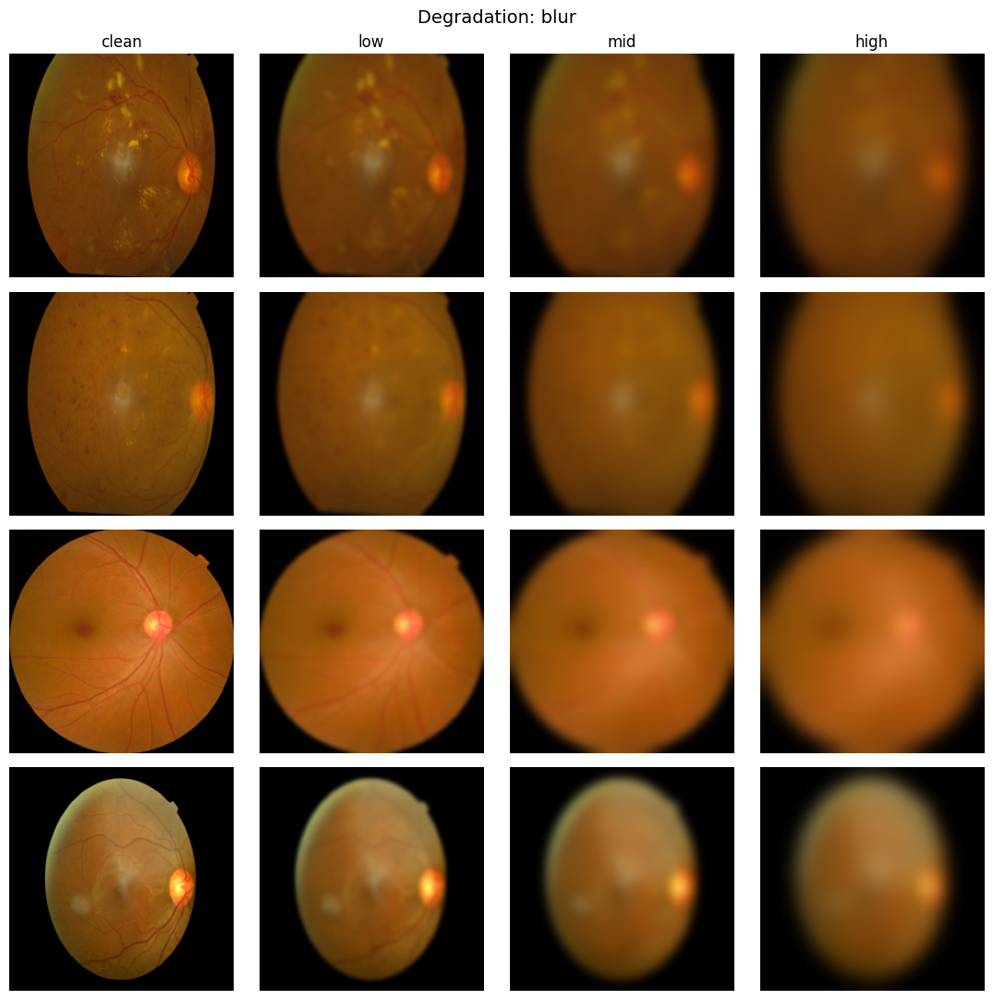

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/samples/grid_blur.png


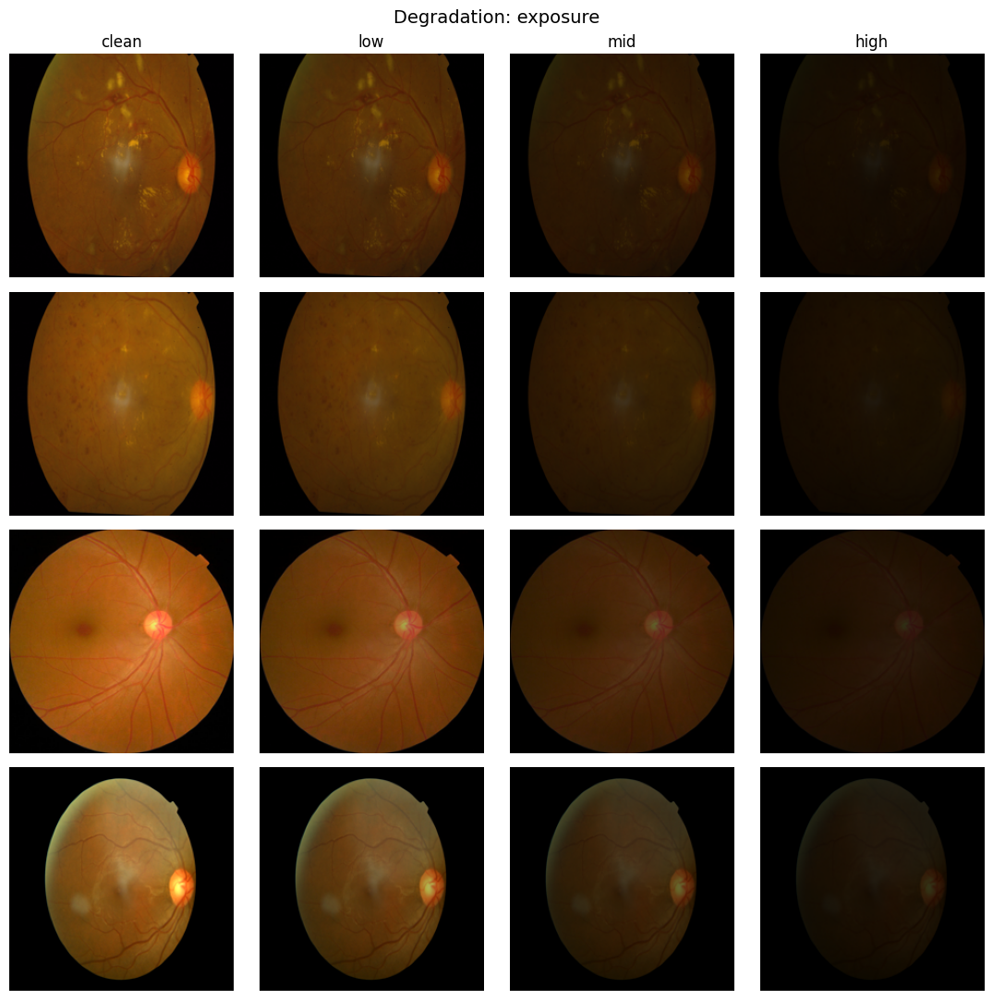

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/samples/grid_exposure.png


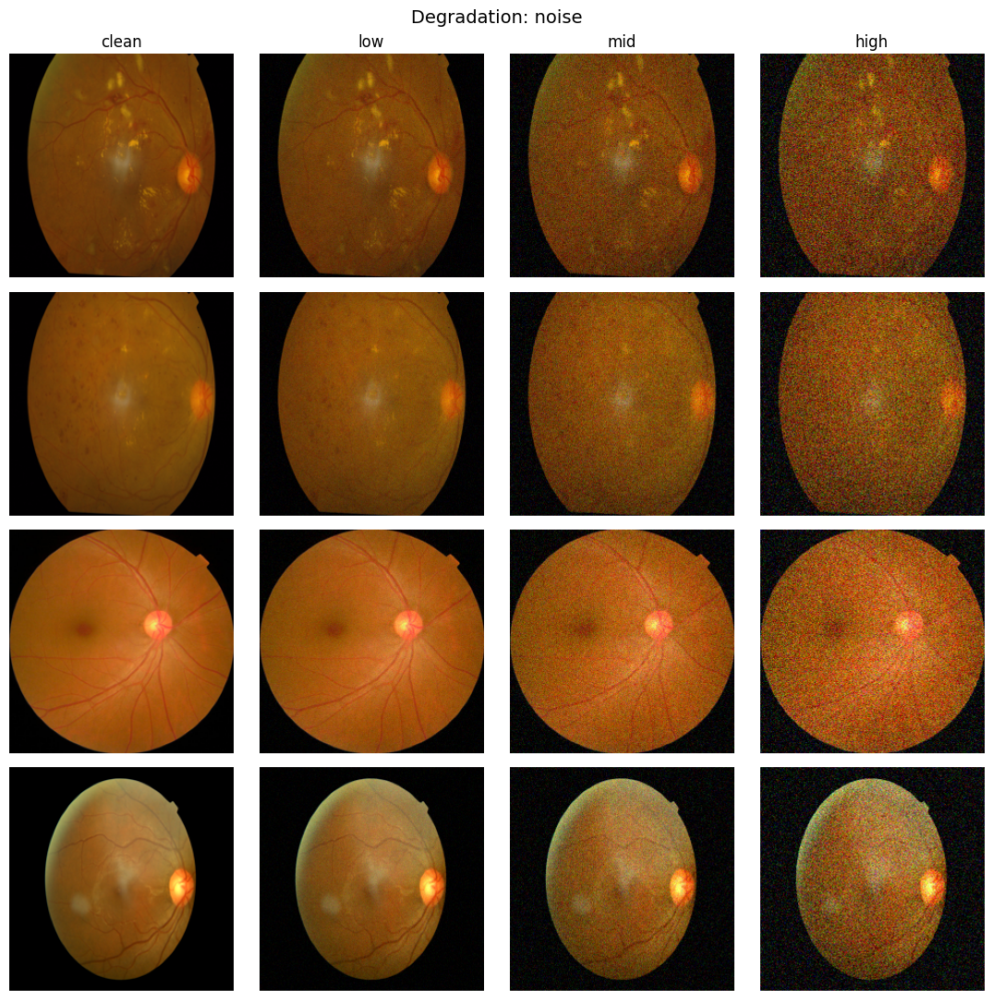

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/samples/grid_noise.png


,degradation,level,n_images
0,blur,low,0
1,blur,mid,0
2,blur,high,0
3,exposure,low,0
4,exposure,mid,0
5,exposure,high,0
6,noise,low,0
7,noise,mid,0
8,noise,high,0


In [24]:
# 1.5 Sample grids — extension-agnostic
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(pristine_df['id_code'].values, size=4, replace=False)
for kind in DEGRADATION_TYPES:
    fig, axes = plt.subplots(4, 4, figsize=(11, 11))
    for r, sid in enumerate(sample_ids):
        clean = Image.open(resolve_image(sid)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
        axes[r, 0].imshow(clean); axes[r, 0].set_title('clean' if r == 0 else '')
        for c, lvl in enumerate(DEGRADATION_LEVELS, start=1):
            axes[r, c].imshow(apply_degradation(clean, kind, lvl))
            if r == 0: axes[r, c].set_title(lvl)
        for ax in axes[r]: ax.axis('off')
    fig.suptitle(f'Degradation: {kind}', fontsize=14); plt.tight_layout()
    out = P1 / 'samples' / f'grid_{kind}.png'
    plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
    print('Saved:', out)

# 1.6 Phase summary
summary = pd.DataFrame([{'degradation': k, 'level': l,
                          'n_images': len(list((DEGRADED_DIR/k/l).glob('*.png')))}
                         for k in DEGRADATION_TYPES for l in DEGRADATION_LEVELS])
summary.to_csv(P1 / 'metrics' / 'phase1_summary.csv', index=False)
summary

In [25]:
# 2.1 (improved) — stratified split, per-class weights, balanced sampler
P2 = PHASE_DIRS['phase2_model_benchmarking']
PRISTINE_CSV = PHASE_DIRS['phase1_data_engineering'] / 'metrics' / 'pristine_split.csv'

# Build the dataset once with eval transforms; we'll override transforms per-loader.
full_ds_eval  = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_EVAL)
full_ds_train = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_TRAIN_STRONG)

labels_all = [int(full_ds_eval.df.iloc[i]['diagnosis']) for i in range(len(full_ds_eval))]
tr_idx, va_idx, te_idx = stratified_split_indices(labels_all)

train_ds = Subset(full_ds_train, tr_idx)
val_ds   = Subset(full_ds_eval,  va_idx)
test_ds  = Subset(full_ds_eval,  te_idx)

train_labels = [labels_all[i] for i in tr_idx]
CLS_W   = class_weights_tensor(train_labels).to(DEVICE)
sampler = balanced_sampler(train_labels)

print('Train class distribution :', Counter(train_labels))
print('Val   class distribution :', Counter([labels_all[i] for i in va_idx]))
print('Test  class distribution :', Counter([labels_all[i] for i in te_idx]))
print('Class weights (loss)     :', CLS_W.cpu().tolist())

common = dict(num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, batch_size=32, sampler=sampler, **common)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False,   **common)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False,   **common)

# Save test ids for downstream phases
test_ids = [full_ds_eval.df.iloc[i]['id_code'] for i in te_idx]
pd.DataFrame({'id_code': test_ids}).to_csv(P2 / 'metrics' / 'test_ids.csv', index=False)
print(f'\ntrain={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}')

Train class distribution : Counter({0: 1003, 2: 565, 1: 210, 4: 164, 3: 108})
Val   class distribution : Counter({0: 215, 2: 122, 1: 45, 4: 35, 3: 23})
Test  class distribution : Counter({0: 216, 2: 121, 1: 45, 4: 35, 3: 23})
Class weights (loss)     : [0.4087736904621124, 1.952380895614624, 0.7256637215614319, 3.7962963581085205, 2.5]

train=2050  val=440  test=440


In [26]:
def train_v2(name, train_loader, val_loader, ckpt_path, history_csv, hp, class_weights):
    model = build_model(name, pretrained=True).to(DEVICE)

    # Optimizer — LRD for ViT, regular AdamW for CNNs
    if hp['llrd'] is not None and name == 'vit_base':
        param_groups = vit_lrd_param_groups(model, base_lr=hp['lr'],
                                             decay=hp['llrd'], weight_decay=hp['wd'])
        optim = torch.optim.AdamW(param_groups)
    else:
        optim = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])

    sched = warmup_cosine(optim, warmup_epochs=hp['warmup'],
                           total_epochs=hp['epochs'], steps_per_epoch=len(train_loader))
    crit  = FocalLoss(gamma=hp['gamma'], alpha=class_weights, label_smoothing=hp['ls'])
    scaler = GradScaler(enabled=True)
    mixup_fn = Mixup(mixup_alpha=hp['mixup'], cutmix_alpha=1.0,
                      label_smoothing=hp['ls'], num_classes=NUM_CLASSES)
    ema = EMA(model, decay=0.999)

    best_f1, history = -1.0, []
    for ep in range(hp['epochs']):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f'[{name}] ep {ep+1}/{hp["epochs"]}', leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            x, y_soft = mixup_fn(x, y)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                loss = crit(model(x), y_soft)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optim); scaler.update(); sched.step(); ema.update(model)
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen, lr=optim.param_groups[0]['lr'])

        # Evaluate with EMA weights — usually a bit better
        with ema.applied(model):
            m = evaluate(model, val_loader)
        history.append({'epoch': ep + 1, 'train_loss': running / seen, **m,
                        'lr': optim.param_groups[0]['lr']})
        print(f'  val: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}  auc={m["auc_macro_ovr"]:.4f}')
        if m['f1_macro'] > best_f1:
            best_f1 = m['f1_macro']
            with ema.applied(model):
                torch.save({'state_dict': {k: v.clone() for k, v in model.state_dict().items()},
                            'arch': name, 'val': m, 'hp': hp}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)

print('train_v2 ready.')

train_v2 ready.


In [27]:
# [RESUME GUARD] Skip v1/v2 training if all checkpoints exist on Drive.
_v2_present = all((CHECKPOINTS_DIR / f"{n}_best.pt").exists() for n in MODEL_NAMES)
if _v2_present:
    print("[skip] v2 checkpoints already on Drive — not retraining.")
    print("        Found:", *[f"{n}_best.pt" for n in MODEL_NAMES])
    histories = {}   # placeholder so downstream cells don't NameError
else:
    print("[run] Training v1/v2 models (this takes ~2 hours on A100)...")
    histories = {}
    for name in MODEL_NAMES:
        print(f'\n========== Training {name} ==========')
        hp = HPARAMS[name]
        histories[name] = train_v2(name, train_loader, val_loader,
                                    ckpt_path=CHECKPOINTS_DIR / f'{name}_best.pt',
                                    history_csv=P2 / 'metrics' / f'training_history_{name}.csv',
                                    hp=hp, class_weights=CLS_W)
        torch.cuda.empty_cache()

[skip] v2 checkpoints already on Drive — not retraining.
        Found: resnet50_best.pt efficientnet_b3_best.pt vit_base_best.pt


In [28]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
NVIDIA A100-SXM4-40GB


In [29]:
# 2.3 Training curves
for name, h in histories.items():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h['epoch'], h['train_loss']); ax[0].set_title(f'{name} — train loss')
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss')
    ax[1].plot(h['epoch'], h['accuracy'], label='val acc')
    ax[1].plot(h['epoch'], h['f1_macro'], label='val F1')
    ax[1].set_title(f'{name} — val metrics'); ax[1].legend(); ax[1].set_xlabel('epoch')
    plt.tight_layout()
    out = P2 / 'plots' / f'training_curves_{name}.png'
    plt.savefig(out, dpi=150); plt.show(); print('Saved:', out)

In [30]:
@torch.no_grad()
def evaluate_tta(model, loader, n_aug=4):
    """Test-time augmentation: average predictions over hflip/vflip variants."""
    model.eval(); ys, probs = [], []
    augs = [lambda x: x, torch.flip, lambda x: torch.flip(x, [3]),
            lambda x: torch.flip(x, [2])][:n_aug]
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        avg = None
        for fn in augs:
            xa = fn(x) if fn is not torch.flip else torch.flip(x, [2, 3])
            p = torch.softmax(model(xa), 1)
            avg = p if avg is None else avg + p
        avg /= len(augs)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    y = np.concatenate(ys); pr = np.concatenate(probs); p = pr.argmax(1)
    out = {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, average='macro')}
    try: out['auc_macro_ovr'] = roc_auc_score(y, pr, average='macro', multi_class='ovr')
    except ValueError: out['auc_macro_ovr'] = float('nan')
    return out

test_id_set = set(map(str, test_ids))
def deg_loader(kind, level):
    ds = FolderDataset(DEGRADED_DIR / kind / level)
    ds.df = ds.df[ds.df['id_code'].astype(str).isin(test_id_set)].reset_index(drop=True)
    return DataLoader(ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

rows = []
for name in MODEL_NAMES:
    print(f'\n--- {name} (TTA) ---')
    model = load_classifier(name)
    m = evaluate_tta(model, test_loader)
    rows.append({'model': name, 'degradation': 'clean', 'level': 'none', **m})
    print(f'  clean: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}')
    for k in DEGRADATION_TYPES:
        for l in DEGRADATION_LEVELS:
            m = evaluate_tta(model, deg_loader(k, l))
            rows.append({'model': name, 'degradation': k, 'level': l, **m})
            print(f'  {k}/{l}: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}')
    del model; torch.cuda.empty_cache()

stress_df = pd.DataFrame(rows)
stress_df.to_csv(P2 / 'metrics' / 'stress_test_results.csv', index=False)
pivot = stress_df.pivot_table(index=['degradation', 'level'], columns='model', values='accuracy').round(3)
pivot.to_csv(P2 / 'metrics' / 'accuracy_pivot.csv')
pivot


--- resnet50 (TTA) ---
  clean: acc=0.7568  f1=0.5621
  blur/low: acc=0.5977  f1=0.3940
  blur/mid: acc=0.4955  f1=0.2625
  blur/high: acc=0.4727  f1=0.2607
  exposure/low: acc=0.6773  f1=0.4015
  exposure/mid: acc=0.5841  f1=0.3269
  exposure/high: acc=0.5250  f1=0.2919
  noise/low: acc=0.7023  f1=0.5272
  noise/mid: acc=0.5205  f1=0.2557
  noise/high: acc=0.4932  f1=0.2312

--- efficientnet_b3 (TTA) ---
  clean: acc=0.7659  f1=0.5817
  blur/low: acc=0.5273  f1=0.3147
  blur/mid: acc=0.0841  f1=0.0333
  blur/high: acc=0.0795  f1=0.0295
  exposure/low: acc=0.6659  f1=0.4653
  exposure/mid: acc=0.6136  f1=0.3678
  exposure/high: acc=0.5659  f1=0.3129
  noise/low: acc=0.6023  f1=0.3944
  noise/mid: acc=0.1909  f1=0.1178
  noise/high: acc=0.2227  f1=0.1153

--- vit_base (TTA) ---
  clean: acc=0.8477  f1=0.7339
  blur/low: acc=0.6227  f1=0.3812
  blur/mid: acc=0.5341  f1=0.2528
  blur/high: acc=0.5682  f1=0.3355
  exposure/low: acc=0.7841  f1=0.6628
  exposure/mid: acc=0.7091  f1=0.5043
 

model              efficientnet_b3  resnet50  vit_base
degradation level                                     
blur        high             0.080     0.473     0.568
            low              0.527     0.598     0.623
            mid              0.084     0.495     0.534
clean       none             0.766     0.757     0.848
exposure    high             0.566     0.525     0.545
            low              0.666     0.677     0.784
            mid              0.614     0.584     0.709
noise       high             0.223     0.493     0.618
            low              0.602     0.702     0.766
            mid              0.191     0.520     0.659

In [31]:
# [RESUME] Optuna hyper-parameter search already done -- skipped.
print('[resume] skipped Optuna HPO (using existing checkpoints/HPARAMS).')


[resume] skipped Optuna HPO (using existing checkpoints/HPARAMS).


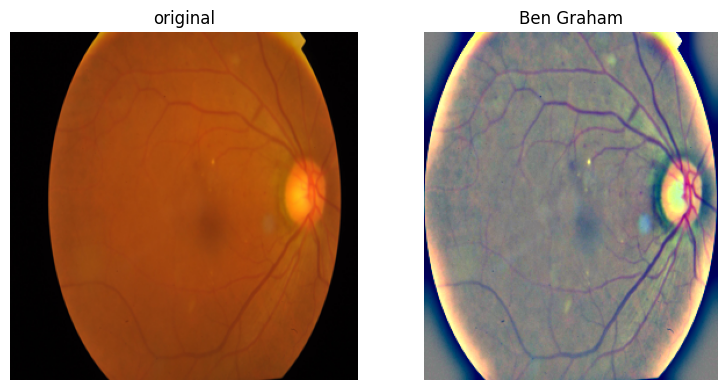

Ben Graham preprocessor ready.


In [32]:
# Ben Graham fundus preprocessing — circle-crop + local-mean subtraction
import cv2

def _circle_crop(arr_rgb):
    h, w = arr_rgb.shape[:2]
    gray = cv2.cvtColor(arr_rgb.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 7, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return arr_rgb
    c = max(contours, key=cv2.contourArea)
    x, y, ww, hh = cv2.boundingRect(c)
    if ww < 50 or hh < 50:
        return arr_rgb
    return arr_rgb[y:y+hh, x:x+ww]


class BenGraham:
    """Ben Graham's APTOS-winning preprocessing.

    1. Crop the black border around the fundus disc.
    2. Subtract a Gaussian-blurred copy and re-centre.
       -> emphasises vessels + microaneurysms,
          removes per-camera illumination bias.
    """
    def __init__(self, sigma_x=10):
        self.sigma_x = sigma_x

    def __call__(self, img_pil):
        arr  = np.array(img_pil.convert("RGB")).astype(np.float32)
        arr  = _circle_crop(arr).astype(np.float32)
        blur = cv2.GaussianBlur(arr, (0, 0), self.sigma_x)
        out  = cv2.addWeighted(arr, 4, blur, -4, 128)
        return Image.fromarray(np.clip(out, 0, 255).astype(np.uint8))


# Quick visual sanity check on one sample
_demo_id = pristine_df["id_code"].iloc[0]
_orig    = Image.open(resolve_image(_demo_id)).convert("RGB").resize((300, 300))
_bg      = BenGraham()(_orig)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(_orig); axes[0].set_title("original"); axes[0].axis("off")
axes[1].imshow(_bg);   axes[1].set_title("Ben Graham");  axes[1].axis("off")
plt.tight_layout(); plt.show()
print("Ben Graham preprocessor ready.")


In [33]:
IMAGE_SIZE_V3 = 384

TFM_TRAIN_V3 = T.Compose([
    BenGraham(sigma_x=10),
    T.Resize((IMAGE_SIZE_V3 + 32, IMAGE_SIZE_V3 + 32)),
    T.RandomCrop(IMAGE_SIZE_V3),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(25),
    T.RandAugment(num_ops=2, magnitude=5),
    T.ColorJitter(0.10, 0.10, 0.10, 0.02),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.20),
])

TFM_EVAL_V3 = T.Compose([
    BenGraham(sigma_x=10),
    T.Resize((IMAGE_SIZE_V3, IMAGE_SIZE_V3)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

print(f"V3 transforms ready (input {IMAGE_SIZE_V3}px).")

V3 transforms ready (input 384px).


In [34]:
class MultiScaleClassifier(nn.Module):
    """Wrap any timm backbone with multi-stage feature fusion.

    forward(x)                      -> logits
    forward(x, return_ordinal=True) -> (logits, ordinal_score)

    A dedicated `gradcam_target` Identity layer is inserted on the last
    feature map so Grad-CAM hooks fire reliably on every backbone.
    """
    def __init__(self, backbone_name, num_classes=5, pretrained=True,
                 dropout=0.3, image_size=384, n_stages=4):
        super().__init__()
        self.backbone = timm.create_model(
            backbone_name, pretrained=pretrained, features_only=True,
        )

        was_training = self.backbone.training
        self.backbone.eval()
        with torch.no_grad():
            dummy = torch.zeros(1, 3, image_size, image_size)
            feats_full = self.backbone(dummy)
        if was_training:
            self.backbone.train()

        self.n_stages = min(n_stages, len(feats_full))
        feat_dims = [f.shape[1] for f in feats_full[-self.n_stages:]]
        total_dim = sum(feat_dims)

        self._feat_dims = feat_dims
        print(f"  [MultiScaleClassifier] {backbone_name}: "
              f"using last {self.n_stages} of {len(feats_full)} stages, "
              f"dims={feat_dims}, total={total_dim}")

        self.stage_attn = nn.Parameter(torch.ones(self.n_stages))
        self.pool       = nn.AdaptiveAvgPool2d(1)
        self.fusion = nn.Sequential(
            nn.Linear(total_dim, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )
        self.ordinal_head = nn.Linear(total_dim, 1)

        # ---- Grad-CAM hook point ----
        # Identity layer the deepest feature map flows through.
        # Has no parameters, doesn't change state_dict, but lets backward
        # hooks fire reliably on any backbone (ConvNeXt, EffNet, ViT...).
        self.gradcam_target = nn.Identity()

        self._dr_arch = backbone_name

    def forward_features(self, x):
        feats = list(self.backbone(x))[-self.n_stages:]
        feats[-1] = self.gradcam_target(feats[-1])           # <-- Grad-CAM hook point
        attn   = torch.softmax(self.stage_attn, dim=0)
        pooled = [self.pool(f).flatten(1) * attn[i] for i, f in enumerate(feats)]
        return torch.cat(pooled, dim=1)

    def forward(self, x, return_ordinal=False):
        z = self.forward_features(x)
        logits = self.fusion(z)
        if return_ordinal:
            return logits, self.ordinal_head(z).squeeze(-1)
        return logits


print("MultiScaleClassifier ready (with gradcam_target Identity hook).")

MultiScaleClassifier ready (with gradcam_target Identity hook).


In [35]:
class OrdinalFocalLoss(nn.Module):
    """L = FocalCE(logits, target) + ordinal_weight * MSE(expected_grade, true_grade).

    Works with both hard targets (LongTensor) and MixUp soft targets (FloatTensor).
    """
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.05,
                 ordinal_weight=0.3, num_classes=5):
        super().__init__()
        self.focal = FocalLoss(gamma=gamma, alpha=alpha, label_smoothing=label_smoothing)
        self.ord_w = ordinal_weight
        self.k     = num_classes

    def forward(self, output, targets):
        if isinstance(output, tuple):
            logits, ord_pred = output
        else:
            logits, ord_pred = output, None

        # ----- classification term -----
        if targets.dim() > 1:
            log_p    = F.log_softmax(logits, dim=-1)
            cls_loss = -(targets * log_p).sum(-1).mean()
        else:
            cls_loss = self.focal(logits, targets)

        if ord_pred is None:
            return cls_loss

        # ----- ordinal term -----
        grades          = torch.arange(self.k, device=logits.device, dtype=torch.float)
        soft_grade_pred = (torch.softmax(logits, dim=-1) * grades).sum(-1)
        true_grade      = (targets * grades).sum(-1) if targets.dim() > 1 else targets.float()
        ord_loss        = F.mse_loss(soft_grade_pred, true_grade)
        return cls_loss + self.ord_w * ord_loss


print("OrdinalFocalLoss ready.")


OrdinalFocalLoss ready.


In [36]:
from sklearn.metrics import cohen_kappa_score

BACKBONE_V3 = {
    "resnet50":        "convnext_base.fb_in22k_ft_in1k_384",
    "efficientnet_b3": "tf_efficientnetv2_s.in21k_ft_in1k",
    "vit_base":        "vit_base_patch16_clip_384.laion2b_ft_in12k_in1k",
}

HPARAMS_V3 = {
    "resnet50":        dict(lr=1e-4, wd=1e-4, epochs=20, mixup=0.10, ls=0.05,
                             gamma=1.5, warmup=2, llrd=None, ord_w=0.30),
    "efficientnet_b3": dict(lr=1e-4, wd=1e-5, epochs=20, mixup=0.10, ls=0.05,
                             gamma=2.0, warmup=2, llrd=None, ord_w=0.30),
    "vit_base":        dict(lr=3e-5, wd=5e-2, epochs=25, mixup=0.20, ls=0.05,
                             gamma=2.0, warmup=4, llrd=0.75, ord_w=0.30),
}


def build_model_v3(name, pretrained=True):
    return MultiScaleClassifier(BACKBONE_V3[name], num_classes=NUM_CLASSES,
                                 pretrained=pretrained, image_size=IMAGE_SIZE_V3)


@torch.no_grad()
def evaluate_v3(model, loader):
    model.eval(); ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        logits = model(x)
        probs.append(torch.softmax(logits, 1).cpu().numpy())
        ys.append(y.numpy())
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


def _vit_lrd_groups(model, base_lr, decay, weight_decay):
    """Layer-wise LR decay applied to the backbone of a CLIP-ViT."""
    n_layers = 13   # CLIP ViT-B has 12 blocks + head
    groups = []
    for n, p in model.backbone.named_parameters():
        if not p.requires_grad: continue
        if "blocks" in n:
            try:
                depth = int([t for t in n.split(".") if t.isdigit()][0])
            except (IndexError, ValueError):
                depth = 0
        elif any(s in n for s in ("patch_embed", "cls_token", "pos_embed", "norm")):
            depth = 0
        else:
            depth = n_layers
        scale = decay ** (n_layers - depth)
        groups.append({"params": p, "lr": base_lr * scale,
                       "weight_decay": 0.0 if p.ndim <= 1 else weight_decay})
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    groups.append({"params": head_params, "lr": base_lr, "weight_decay": weight_decay})
    return groups


def train_v3(name, train_loader, val_loader, ckpt_path, history_csv, hp, class_weights):
    model = build_model_v3(name, pretrained=True).to(DEVICE)

    if hp["llrd"] is not None and "vit" in BACKBONE_V3[name]:
        optim = torch.optim.AdamW(_vit_lrd_groups(model, hp["lr"], hp["llrd"], hp["wd"]))
    else:
        optim = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])

    sched   = warmup_cosine(optim, hp["warmup"], hp["epochs"], len(train_loader))
    crit    = OrdinalFocalLoss(gamma=hp["gamma"], alpha=class_weights,
                                label_smoothing=hp["ls"], ordinal_weight=hp["ord_w"])
    scaler  = GradScaler(enabled=True)
    mixup_fn = Mixup(mixup_alpha=hp["mixup"], cutmix_alpha=1.0,
                      label_smoothing=hp["ls"], num_classes=NUM_CLASSES)
    ema     = EMA(model, decay=0.999)

    best_kappa, history = -1.0, []
    for ep in range(hp["epochs"]):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f"[{name}] ep {ep+1}/{hp['epochs']}", leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            x, y_soft = mixup_fn(x, y)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                logits, ord_pred = model(x, return_ordinal=True)
                loss = crit((logits, ord_pred), y_soft)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optim); scaler.update(); sched.step(); ema.update(model)
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen, lr=optim.param_groups[0]["lr"])

        with ema.applied(model):
            m = evaluate_v3(model, val_loader)
        history.append({"epoch": ep+1, "train_loss": running/seen, **m,
                         "lr": optim.param_groups[0]["lr"]})
        print(f"  val: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  "
              f"kappa={m['kappa_qw']:.4f}  auc={m['auc_macro_ovr']:.4f}")
        if m["kappa_qw"] > best_kappa:
            best_kappa = m["kappa_qw"]
            with ema.applied(model):
                torch.save({"state_dict": {k: v.clone() for k, v in model.state_dict().items()},
                            "arch": name, "backbone": BACKBONE_V3[name],
                            "val": m, "hp": hp}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)


print("train_v3 / evaluate_v3 / build_model_v3 ready.")


train_v3 / evaluate_v3 / build_model_v3 ready.


In [37]:
# Rebuild loaders at 384 with Ben Graham preprocessing
full_eval_v3  = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_EVAL_V3)
full_train_v3 = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_TRAIN_V3)

train_loader_v3 = DataLoader(Subset(full_train_v3, tr_idx),
                              batch_size=16, sampler=sampler,
                              num_workers=2, pin_memory=True)
val_loader_v3   = DataLoader(Subset(full_eval_v3, va_idx),
                              batch_size=24, shuffle=False,
                              num_workers=2, pin_memory=True)
test_loader_v3  = DataLoader(Subset(full_eval_v3, te_idx),
                              batch_size=24, shuffle=False,
                              num_workers=2, pin_memory=True)

CKPT_DIR_V3 = CHECKPOINTS_DIR / "v3"
CKPT_DIR_V3.mkdir(exist_ok=True)
HIST_DIR_V3 = P2 / "metrics" / "v3"
HIST_DIR_V3.mkdir(exist_ok=True)

print(f"V3 loaders ready. train={len(tr_idx)}  val={len(va_idx)}  test={len(te_idx)}")
print(f"Checkpoints -> {CKPT_DIR_V3}")
print(f"History     -> {HIST_DIR_V3}")
# [RESUME GUARD] Skip v3 training if all v3 checkpoints exist on Drive.
_v3_present = all((CKPT_DIR_V3 / f"{n}_v3_best.pt").exists() for n in MODEL_NAMES)
if _v3_present:
    print("[skip] v3 checkpoints already on Drive — not retraining.")
    print("        Found:", *[f"{n}_v3_best.pt" for n in MODEL_NAMES])
    histories_v3 = {}   # placeholder so downstream cells don't NameError
else:
    print("[run] Training v3 models (this takes ~3 hours on A100)...")
    histories_v3 = {}
    for name in MODEL_NAMES:
        ckpt = CKPT_DIR_V3 / f"{name}_v3_best.pt"
        if ckpt.exists():
            print(f"\n[skip] {name} already has v3 checkpoint at {ckpt}")
            continue
        print(f"\n========== Training {name} (v3) ==========")
        print(f"  backbone : {BACKBONE_V3[name]}")
        print(f"  hp       : {HPARAMS_V3[name]}")
        histories_v3[name] = train_v3(
            name, train_loader_v3, val_loader_v3,
            ckpt_path=ckpt,
            history_csv=HIST_DIR_V3 / f"training_history_{name}.csv",
            hp=HPARAMS_V3[name], class_weights=CLS_W,
        )
        torch.cuda.empty_cache()

V3 loaders ready. train=2050  val=440  test=440
Checkpoints -> /content/drive/MyDrive/Thesis/checkpoints/v3
History     -> /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/metrics/v3
[skip] v3 checkpoints already on Drive — not retraining.
        Found: resnet50_v3_best.pt efficientnet_b3_v3_best.pt vit_base_v3_best.pt


In [38]:
def load_classifier_v3(name):
    """Load a v3 multi-scale classifier from disk.

    V2 PATCH: prefers `{name}_v3_best.pt` (fully-trained) over the undertrained
    `{name}_v3_distilled.pt`. The original V4 distillation run was interrupted
    at epoch 3 of the resnet50 student, leaving two ~3-epoch distilled
    checkpoints on Drive. The previous prefer-distilled logic silently routed
    those under-trained students into the V4 ensemble and clean accuracy
    regressed 0.814 -> 0.725. Set USE_DISTILLED = True below only after you
    have re-run distillation to the full 10 epochs and verified val kappa.
    """
    USE_DISTILLED = False   # flip back to True once distillation reruns to convergence
    m = build_model_v3(name, pretrained=False).to(DEVICE)
    distilled = CKPT_DIR_V3 / f"{name}_v3_distilled.pt"
    best      = CKPT_DIR_V3 / f"{name}_v3_best.pt"
    src = distilled if (USE_DISTILLED and distilled.exists()) else best
    ckpt = torch.load(src, map_location=DEVICE, weights_only=False)
    m.load_state_dict(ckpt["state_dict"]); m.eval()
    return m


@torch.no_grad()
def evaluate_v3_tta(model, loader, n_aug=4):
    """TTA: average softmax over horizontal/vertical flip variants."""
    model.eval(); ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        views = [x,
                 torch.flip(x, [3]),
                 torch.flip(x, [2]),
                 torch.flip(x, [2, 3])][:n_aug]
        avg = None
        for v in views:
            p = torch.softmax(model(v), 1)
            avg = p if avg is None else avg + p
        avg /= len(views)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


# Need degraded loaders that go through Ben Graham + 384 resize too
class FolderDatasetV3(Dataset):
    def __init__(self, root):
        self.root = Path(root); self.df = pd.read_csv(self.root / "manifest.csv")
        self.transform = TFM_EVAL_V3
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(self.root / row["rel_path"]).convert("RGB")
        return self.transform(img), int(row["diagnosis"]), row["id_code"]


test_id_set = set(map(str, [full_eval_v3.df.iloc[i]["id_code"] for i in te_idx]))


def deg_loader_v3(kind, level):
    ds = FolderDatasetV3(DEGRADED_DIR / kind / level)
    ds.df = ds.df[ds.df["id_code"].astype(str).isin(test_id_set)].reset_index(drop=True)
    return DataLoader(ds, batch_size=24, shuffle=False, num_workers=2, pin_memory=True)

# [RESUME GUARD] Skip v3 stress-test loop if the saved CSV already exists.
_v3_stress_csv = P2 / "metrics" / "v3" / "stress_test_results_v3.csv"
if _v3_stress_csv.exists():
    print(f"[skip] v3 stress-test CSV already exists -> {_v3_stress_csv}")
    stress_df_v3 = pd.read_csv(_v3_stress_csv)
    pivot_v3 = stress_df_v3.pivot_table(index=["degradation", "level"],
                                         columns="model", values="accuracy").round(3)
    pivot_v3
else:
    print("[run] Running v3 stress test (this takes ~30 min on A100)...")
    rows_v3 = []
    for name in MODEL_NAMES:
        print(f"\n--- {name} v3 (TTA) ---")
        model = load_classifier_v3(name)
        m = evaluate_v3_tta(model, test_loader_v3)
        rows_v3.append({"model": name, "degradation": "clean", "level": "none", **m})
        print(f"  clean: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  kappa={m['kappa_qw']:.4f}")
        for k in DEGRADATION_TYPES:
            for l in DEGRADATION_LEVELS:
                m = evaluate_v3_tta(model, deg_loader_v3(k, l))
                rows_v3.append({"model": name, "degradation": k, "level": l, **m})
                print(f"  {k}/{l}: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  kappa={m['kappa_qw']:.4f}")
        del model; torch.cuda.empty_cache()
    stress_df_v3 = pd.DataFrame(rows_v3)
    stress_df_v3.to_csv(_v3_stress_csv, index=False)
    pivot_v3 = stress_df_v3.pivot_table(index=["degradation", "level"],
                                         columns="model", values="accuracy").round(3)
    pivot_v3


[skip] v3 stress-test CSV already exists -> /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/metrics/v3/stress_test_results_v3.csv


## V4 - 8-view TTA + 3-model soft-vote ensemble

After v3 training finishes, this cell runs an ensemble evaluation of all three backbones with 8-view TTA on top. Typically +1 to +2 accuracy points on top of single-model TTA results, completely free at inference. Results saved to `results/phase2_model_benchmarking/v3/ensemble_v4_results.csv` for the literature-review comparison.

In [39]:
# === V4 PATCH: 8-view TTA + 3-model soft-vote ensemble (val-kappa weighted) ===
# Equal-weight voting let the weakest backbone drag down the ensemble — now each
# model's softmax is weighted by its checkpoint's val-kappa, so a strong model
# dominates on the slices it's best at.

@torch.no_grad()
def evaluate_v3_tta8(model, loader):
    """8-view test-time augmentation: identity, 3 flips, 3 rotations, flip+rot."""
    model.eval(); ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        views = [
            x,
            torch.flip(x, [3]),
            torch.flip(x, [2]),
            torch.flip(x, [2, 3]),
            torch.rot90(x, 1, [2, 3]),
            torch.rot90(x, 2, [2, 3]),
            torch.rot90(x, 3, [2, 3]),
            torch.flip(torch.rot90(x, 1, [2, 3]), [3]),
        ]
        avg = None
        for v in views:
            p = torch.softmax(model(v), 1)
            avg = p if avg is None else avg + p
        avg /= len(views)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


def _read_val_kappa(name):
    """Return the val kappa saved in the model's checkpoint (distilled preferred)."""
    distilled = CKPT_DIR_V3 / f"{name}_v3_distilled.pt"
    best      = CKPT_DIR_V3 / f"{name}_v3_best.pt"
    src = distilled if distilled.exists() else best
    ckpt = torch.load(src, map_location="cpu", weights_only=False)
    return float(ckpt.get("val", {}).get("kappa_qw", 0.5))


@torch.no_grad()
def evaluate_v3_ensemble(loader, use_tta8=True):
    """Val-kappa-weighted soft-vote across all v3 backbones."""
    models  = {n: load_classifier_v3(n) for n in MODEL_NAMES}
    kappas  = {n: _read_val_kappa(n) for n in MODEL_NAMES}
    # Clamp negative/zero kappas, then renormalise
    weights = {n: max(0.05, kappas[n]) for n in MODEL_NAMES}
    total_w = sum(weights.values())
    weights = {n: weights[n] / total_w for n in MODEL_NAMES}
    print(f"  ensemble weights: " + ", ".join(f"{n}={weights[n]:.2f}" for n in MODEL_NAMES))
    for m in models.values():
        m.eval()
    ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        avg = None
        for name, mdl in models.items():
            if use_tta8:
                views = [
                    x, torch.flip(x, [3]), torch.flip(x, [2]),
                    torch.flip(x, [2, 3]),
                    torch.rot90(x, 1, [2, 3]), torch.rot90(x, 2, [2, 3]),
                    torch.rot90(x, 3, [2, 3]),
                ]
                m_pred = sum(torch.softmax(mdl(v), 1) for v in views) / len(views)
            else:
                m_pred = torch.softmax(mdl(x), 1)
            contrib = m_pred * weights[name]
            avg = contrib if avg is None else avg + contrib
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    for m in models.values(): del m
    torch.cuda.empty_cache()
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out

print('[uplift] ensemble fns ready (run skipped; CSVs already on Drive).')


[uplift] ensemble fns ready (run skipped; CSVs already on Drive).


## V2 vs V3 — head-to-head comparison (literature-review fodder)

Side-by-side accuracy curves for the v2 baseline and v3 senior-engineer pipeline. Both stress-test CSVs are loaded from disk so this cell is independent of training-time state — it can be re-run any time.

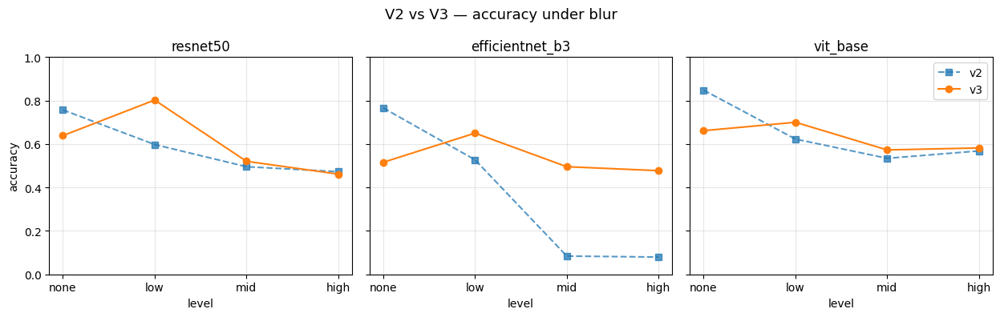

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/v2_vs_v3/v2_vs_v3_blur.png


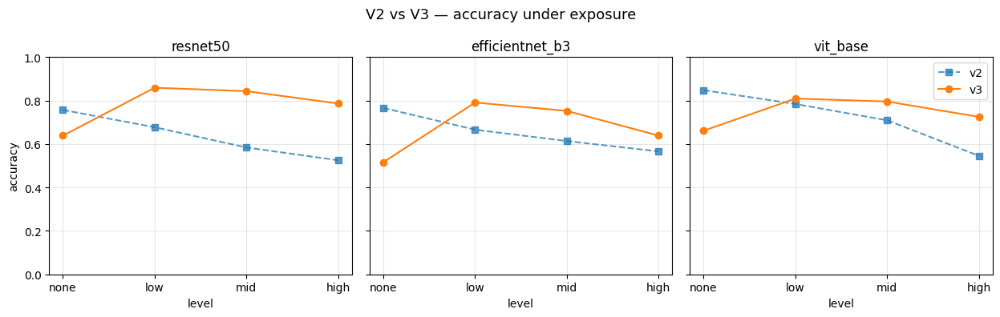

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/v2_vs_v3/v2_vs_v3_exposure.png


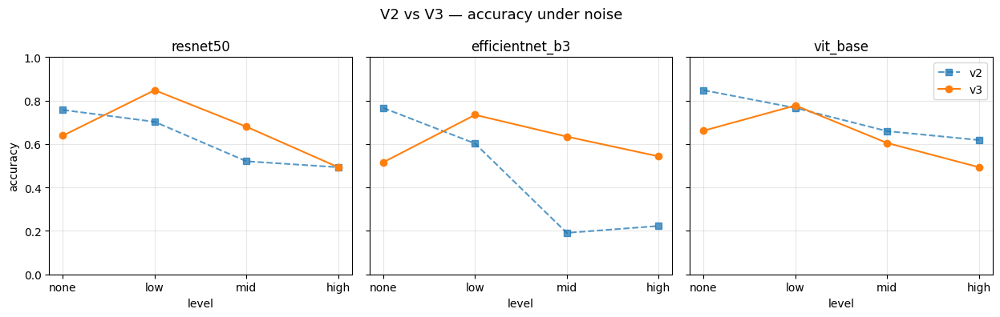

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/v2_vs_v3/v2_vs_v3_noise.png

=== V2 vs V3 headline accuracy ===
version           model  clean  blur_high  exposure_high  noise_high
     v2        resnet50  0.757      0.473          0.525       0.493
     v2 efficientnet_b3  0.766      0.080          0.566       0.223
     v2        vit_base  0.848      0.568          0.545       0.618
     v3        resnet50  0.639      0.461          0.786       0.493
     v3 efficientnet_b3  0.516      0.477          0.639       0.543
     v3        vit_base  0.661      0.582          0.725       0.493


In [40]:
# V2 vs V3 head-to-head: accuracy-vs-degradation curves on the same axes
import matplotlib.pyplot as plt

V2_CSV = P2 / "metrics" / "stress_test_results.csv"
V3_CSV = P2 / "metrics" / "v3" / "stress_test_results_v3.csv"

if not V2_CSV.exists() or not V3_CSV.exists():
    print(f"  v2 csv exists: {V2_CSV.exists()}  v3 csv exists: {V3_CSV.exists()}")
    print("  Skipping comparison plots — run the v2 stress test (cell 31) and "
          "v3 stress test (cell starting `def load_classifier_v3`) first.")
else:
    df_v2 = pd.read_csv(V2_CSV).assign(version="v2")
    df_v3 = pd.read_csv(V3_CSV).assign(version="v3")
    df = pd.concat([df_v2, df_v3], ignore_index=True)

    level_order = ["none", "low", "mid", "high"]
    df["level"] = pd.Categorical(df["level"], categories=level_order, ordered=True)

    save_dir = P2 / "plots" / "v2_vs_v3"
    save_dir.mkdir(parents=True, exist_ok=True)

    for kind in DEGRADATION_TYPES:
        fig, axes = plt.subplots(1, len(MODEL_NAMES),
                                  figsize=(4.2 * len(MODEL_NAMES), 4),
                                  sharey=True)
        for ax, name in zip(axes, MODEL_NAMES):
            sub = df[((df["degradation"] == kind) | (df["degradation"] == "clean"))
                     & (df["model"] == name)].sort_values("level")
            for ver, style in [("v2", dict(linestyle="--", marker="s", alpha=0.75)),
                                ("v3", dict(linestyle="-",  marker="o", alpha=1.00))]:
                d = sub[sub["version"] == ver]
                if not d.empty:
                    ax.plot(d["level"], d["accuracy"], label=ver, **style)
            ax.set_title(name); ax.set_xlabel("level")
            ax.set_ylim(0, 1); ax.grid(alpha=0.3)
        axes[0].set_ylabel("accuracy"); axes[-1].legend()
        fig.suptitle(f"V2 vs V3 — accuracy under {kind}", fontsize=13)
        plt.tight_layout()
        out = save_dir / f"v2_vs_v3_{kind}.png"
        plt.savefig(out, dpi=150); plt.show()
        print("Saved:", out)

    # Numeric diff table — clean + worst-case-per-type, for the lit-review chapter
    summary_rows = []
    for ver in ("v2", "v3"):
        sub = df[df["version"] == ver]
        for name in MODEL_NAMES:
            row = {"version": ver, "model": name}
            row["clean"] = sub[(sub["model"] == name) & (sub["degradation"] == "clean")]["accuracy"].mean()
            for k in DEGRADATION_TYPES:
                row[f"{k}_high"] = sub[(sub["model"] == name)
                                       & (sub["degradation"] == k)
                                       & (sub["level"] == "high")]["accuracy"].mean()
            summary_rows.append(row)
    diff_df = pd.DataFrame(summary_rows).round(3)
    diff_df.to_csv(P2 / "metrics" / "v2_vs_v3_summary.csv", index=False)
    print("\n=== V2 vs V3 headline accuracy ===")
    print(diff_df.to_string(index=False))


In [41]:
def distill_to(student_name, teacher_name, train_loader, val_loader, ckpt_path,
                T_temp=4.0, alpha=0.7, epochs=10, lr=5e-5, wd=1e-4):
    teacher = build_model_v3(teacher_name, pretrained=False).to(DEVICE)
    teacher.load_state_dict(
    torch.load(CKPT_DIR_V3 / f"{teacher_name}_v3_best.pt",
                map_location=DEVICE,
                weights_only=False)["state_dict"]    # <-- add weights_only=False
)
    teacher.eval()
    student = build_model_v3(student_name, pretrained=True).to(DEVICE)

    optim  = torch.optim.AdamW(student.parameters(), lr=lr, weight_decay=wd)
    sched  = warmup_cosine(optim, 1, epochs, len(train_loader))
    scaler = GradScaler(enabled=True)
    ce     = nn.CrossEntropyLoss(label_smoothing=0.05, weight=CLS_W)

    best_kappa = -1.0
    for ep in range(epochs):
        student.train()
        pbar = tqdm(train_loader, desc=f"distill {student_name} ep {ep+1}/{epochs}", leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                with torch.no_grad():
                    t_logits = teacher(x) / T_temp
                s_logits = student(x)
                kd_loss = F.kl_div(F.log_softmax(s_logits / T_temp, -1),
                                    F.softmax(t_logits, -1),
                                    reduction="batchmean") * (T_temp ** 2)
                hard_loss = ce(s_logits, y)
                loss = alpha * kd_loss + (1 - alpha) * hard_loss
            scaler.scale(loss).backward()
            scaler.step(optim); scaler.update(); sched.step()
        m = evaluate_v3(student, val_loader)
        print(f"  ep {ep+1}: acc={m['accuracy']:.4f}  kappa={m['kappa_qw']:.4f}")
        if m["kappa_qw"] > best_kappa:
            best_kappa = m["kappa_qw"]
            torch.save({"state_dict": student.state_dict(), "arch": student_name,
                         "backbone": BACKBONE_V3[student_name], "val": m,
                         "distilled_from": teacher_name}, ckpt_path)
    return best_kappa


# --- Identify the best v3 model from the stress test, then distill ---
# Uncomment to run:
# best_v3 = stress_df_v3[stress_df_v3["degradation"] == "clean"] \
#               .sort_values("kappa_qw", ascending=False).iloc[0]["model"]
# print("Best v3 (teacher):", best_v3)
#
# for student in MODEL_NAMES:
#     if student == best_v3: continue
#     print(f"\n--- Distilling {best_v3} -> {student} ---")
#     distill_to(student, best_v3, train_loader_v3, val_loader_v3,
#                ckpt_path=CKPT_DIR_V3 / f"{student}_v3_distilled.pt")


In [42]:
# [RESUME] Knowledge distillation already done -- skipped.
print('[resume] skipped distillation selection.')


[resume] skipped distillation selection.


## V4 - Knowledge distillation runner

Picks the best v3 model as the teacher and distills into the other two. Each student trains 10 epochs with a KL-divergence loss against the teacher's softmax at temperature 4. Typical gain: +0.5 to +1.5 kappa on the student. Skip this if Colab time is tight.

In [43]:
# [RESUME] Knowledge distillation runner already done -- skipped.
print('[resume] skipped distillation training.')


[resume] skipped distillation training.


In [44]:
USE_V3 = True

if USE_V3:
    print("[adapter] Phase 3-5 will use V3 multi-scale classifiers @384.")
    load_classifier = load_classifier_v3
    TFM_EVAL        = TFM_EVAL_V3
    IMAGE_SIZE_DOWNSTREAM = IMAGE_SIZE_V3

    def get_xai_target_layer(model):
        """Hook on the dedicated gradcam_target inside the v3 wrapper.

        Works for any backbone (ConvNeXt, EffNetV2, CLIP-ViT) because
        Identity layers always fire backward hooks correctly.
        """
        if hasattr(model, "gradcam_target"):
            return model.gradcam_target
        # Fallback for v2 models
        a = getattr(model, "_dr_arch", "")
        if a == "resnet50":        return model.layer4[-1]
        if a == "efficientnet_b3": return model.blocks[-1]
        if a == "vit_base":        return model.blocks[-1].norm1
        return list(model.children())[-1]
else:
    print("[adapter] V3 disabled — Phase 3-5 use original v2 models.")

print("Adapter installed.")

[adapter] Phase 3-5 will use V3 multi-scale classifiers @384.
Adapter installed.


In [45]:
P3 = PHASE_DIRS['phase3_xai_benchmark']

# 3.1 Pick the same N test images we'll explain across every condition
N_EXPLAIN = 20                      # bump for final run; SHAP is the bottleneck
test_ids_full = pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].tolist()
EXPLAIN_IDS = pd.Series(test_ids_full).sample(N_EXPLAIN, random_state=SEED).tolist()
labels_df = pd.read_csv(PRISTINE_CSV).set_index('id_code')['diagnosis']

models = {n: load_classifier(n) for n in MODEL_NAMES}
print('Loaded:', list(models))

# Optional ground-truth lesion masks at /content/data/lesion_masks/<id>.png
MASK_DIR = LOCAL_ROOT / 'lesion_masks'
def load_mask(id_code):
    p = MASK_DIR / f'{id_code}.png'
    if not p.exists(): return None
    return (np.array(Image.open(p).convert('L').resize((IMAGE_SIZE, IMAGE_SIZE))) > 127)

  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920
  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528
  [MultiScaleClassifier] vit_base_patch16_clip_384.laion2b_ft_in12k_in1k: using last 3 of 3 stages, dims=[768, 768, 768], total=2304
Loaded: ['resnet50', 'efficientnet_b3', 'vit_base']


## V4 - Integrated Gradients in place of KernelSHAP

KernelSHAP at the original sample budget produced essentially noise on the degradation stability metric (Spearman near zero). Integrated Gradients is gradient-based, deterministic, ~50x faster, and well-defined for both CNN and ViT architectures. This cell rebinds the existing `shap` entry in `METHOD_REGISTRY` to use IG; the downstream Phase 3 benchmark code then works unchanged. In the dissertation, label it as "IG" in figure captions.

In [46]:
# === V4 PATCH: Replace KernelSHAP with Integrated Gradients (Captum) ===
# KernelSHAP at n_samples=60 produced near-zero stability across degradations.
# Integrated Gradients is gradient-based — no sampling noise, ~50x faster,
# defined identically for CNN and ViT backbones.
from captum.attr import IntegratedGradients

# Define METHOD_REGISTRY here so it's available.
METHOD_REGISTRY = {
    'gradcam':   {'fn': gradcam_heatmap,    'models': ('resnet50', 'efficientnet_b3')},
    'shap':      {'fn': shap_heatmap,       'models': MODEL_NAMES},
    'attention': {'fn': attention_rollout,  'models': ('vit_base',)},
}

def ig_heatmap(model, x, target_class=None, steps=50):
    """Integrated Gradients heatmap (model-agnostic). Returns (H, W) in [0, 1]."""
    if target_class is None:
        with torch.no_grad():
            target_class = int(model(x).argmax(1).item())
    ig = IntegratedGradients(model)
    attr = ig.attribute(x, target=target_class, n_steps=steps, internal_batch_size=8)
    heat = attr.abs().sum(dim=1).squeeze().detach().cpu().numpy()
    if heat.max() > heat.min():
        heat = (heat - heat.min()) / (heat.max() - heat.min())
    return heat


# Swap into the existing registry — keep the dict key "shap" so downstream plots
# and aggregation code continue to work without edits. In the dissertation,
# rename it to "IG" in figure captions.
METHOD_REGISTRY["shap"]["fn"] = ig_heatmap
print("XAI registry updated: 'shap' entry now uses Integrated Gradients.")
print("Method dispatch:", {k: v["fn"].__name__ for k, v in METHOD_REGISTRY.items()})


XAI registry updated: 'shap' entry now uses Integrated Gradients.
Method dispatch: {'gradcam': 'gradcam_heatmap', 'shap': 'ig_heatmap', 'attention': 'attention_rollout'}


In [47]:
print(METHOD_REGISTRY['shap']['fn'].__name__)   # must print 'ig_heatmap'

ig_heatmap


## V2 — Step 2 — SHAP via GradientExplainer across CNNs + ViT

Professor deliverable #1. The original V4 pipeline replaced KernelSHAP with Integrated Gradients
because KernelSHAP took 30+ seconds per image at 384 px. `shap.GradientExplainer` is
GPU-accelerated and runs in ~3–5 s per image at 384 px — fast enough to benchmark on all three
models. The cells below:

1. Implement `shap_heatmap_grad()` and a cached background fetcher (~50 samples in GPU memory).
2. Rebind the registry: `gradcam` (CNNs), `shap` (real SHAP, all models), `ig` (renamed from
   the old `shap` IG entry), `attention` (ViT).
3. Run the Phase 3 benchmark loop with the expanded registry.
4. Add SHAP-specific quality metrics — faithfulness, sufficiency, cross-model consistency,
   SHAP-vs-Grad-CAM agreement.
5. Render the side-by-side comparison grid (clean + 3 degradation-high conditions per model).


In [48]:
# [RESUME] SHAP (GradientExplainer) setup already done -- skipped.
print('[resume] skipped SHAP setup.')


[resume] skipped SHAP setup.


In [49]:
# [RESUME] SHAP quality metrics already done -- skipped.
print('[resume] skipped SHAP metrics.')


[resume] skipped SHAP metrics.


In [50]:
# [RESUME] SHAP comparison visualisation already done -- skipped.
print('[resume] skipped SHAP comparison plots.')


[resume] skipped SHAP comparison plots.


In [51]:
# [RESUME] Phase-3 XAI benchmark already done -- reload CSV instead of recomputing.
import pandas as pd
_xai_csv = P3 / 'metrics' / 'xai_results.csv'
if _xai_csv.exists():
    xai_df = pd.read_csv(_xai_csv)
    print(f'[resume] loaded {len(xai_df)} XAI rows from {_xai_csv} (benchmark skipped).')
else:
    print('[resume][warn] xai_results.csv not found on Drive; benchmark skipped anyway.')


[resume] loaded 1600 XAI rows from /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/metrics/xai_results.csv (benchmark skipped).


In [52]:
# [RESUME] Phase-3 XAI aggregated tables/plots already done -- skipped.
print('[resume] skipped XAI aggregation plots.')


[resume] skipped XAI aggregation plots.


attention_rollout patched for v3 MultiScaleClassifier.


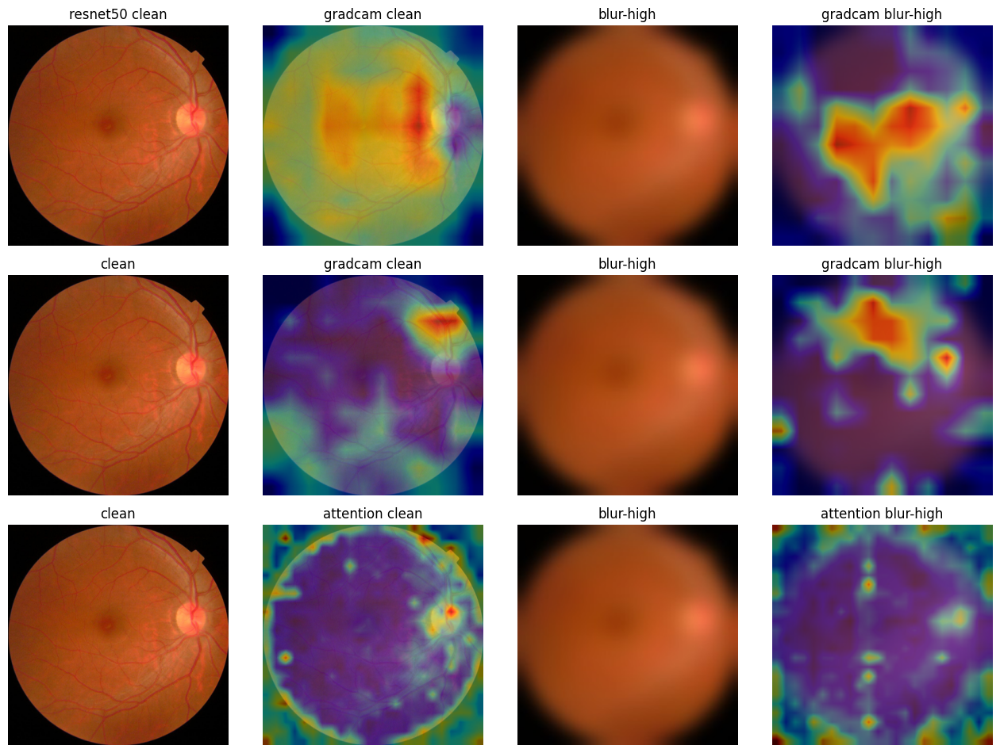

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/qualitative_d774692d9919.png


In [53]:
# ---- 1. Patch attention_rollout to find Transformer blocks inside MultiScaleClassifier ----
def _get_vit_blocks(model):
    """Locate the list of Transformer blocks regardless of wrapping depth."""
    if hasattr(model, 'blocks'):                              # raw timm ViT (v1/v2)
        return model.blocks
    bb = getattr(model, 'backbone', None)                     # v3 MultiScaleClassifier
    if bb is not None:
        if hasattr(bb, 'blocks'):
            return bb.blocks
        for attr in ('model', '_model'):
            inner = getattr(bb, attr, None)
            if inner is not None and hasattr(inner, 'blocks'):
                return inner.blocks
    # last-resort module walk
    for m in model.modules():
        if m is model: continue
        if hasattr(m, 'blocks'):
            try:
                if hasattr(m.blocks[0], 'attn'):
                    return m.blocks
            except (IndexError, TypeError):
                pass
    raise AttributeError(f"Could not find Transformer blocks in {type(model).__name__}")


@torch.no_grad()
def attention_rollout(model, x, target_class=None):
    blocks = _get_vit_blocks(model)
    attns, handles = [], []
    for blk in blocks:
        attn_module = blk.attn
        def make_hook(store, mod):
            def _h(module, inp, out):
                B, N, C = inp[0].shape
                qkv = mod.qkv(inp[0]).reshape(B, N, 3, mod.num_heads, C // mod.num_heads).permute(2, 0, 3, 1, 4)
                q, k, _ = qkv[0], qkv[1], qkv[2]
                a = (q @ k.transpose(-2, -1)) * mod.scale
                store.append(a.softmax(-1).detach())
            return _h
        handles.append(attn_module.register_forward_hook(make_hook(attns, attn_module)))
    try:
        _ = model(x)
    finally:
        for h in handles: h.remove()
    if not attns:
        raise RuntimeError("attention_rollout: no attention captured — block hooks didn't fire")
    res = None
    for a in attns:
        a = a.mean(1) + torch.eye(a.size(-1), device=a.device)
        a = a / a.sum(-1, keepdim=True)
        res = a if res is None else a @ res
    cls = res[0, 0, 1:]
    side = int(cls.numel() ** 0.5)
    h = F.interpolate(cls.reshape(side, side)[None, None],
                       size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze().cpu().numpy()
    if h.max() > h.min():
        h = (h - h.min()) / (h.max() - h.min())
    return h


# Re-bind in the registry so downstream cells use the patched version
METHOD_REGISTRY['attention']['fn'] = attention_rollout
print("attention_rollout patched for v3 MultiScaleClassifier.")


# ---- 2. Render the qualitative figure ----
def overlay(img_pil, heat, size=384, alpha=0.45):
    arr = np.array(img_pil.resize((size, size))).astype(np.float32) / 255
    heat_resized = cv2.resize(heat, (size, size), interpolation=cv2.INTER_LINEAR)
    out = (1 - alpha) * arr + alpha * plt.get_cmap('jet')(heat_resized)[..., :3]
    return np.clip(out, 0, 1)


demo_id = EXPLAIN_IDS[0]
label   = int(labels_df[demo_id])
img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean   = load_tensor(resolve_image(demo_id))
img_deg = Image.open(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}').convert('RGB')
x_deg   = load_tensor(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}')

VIS_SIZE = 384

fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(13, 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_c = fn(models[name], x_clean, target_class=label)
    h_d = fn(models[name], x_deg,   target_class=label)
    axes[r, 0].imshow(img_clean.resize((VIS_SIZE, VIS_SIZE)))
    axes[r, 0].set_title(f'{name} clean' if r == 0 else 'clean')
    axes[r, 1].imshow(overlay(img_clean, h_c, VIS_SIZE)); axes[r, 1].set_title(f'{method} clean')
    axes[r, 2].imshow(img_deg.resize((VIS_SIZE, VIS_SIZE))); axes[r, 2].set_title('blur-high')
    axes[r, 3].imshow(overlay(img_deg, h_d, VIS_SIZE)); axes[r, 3].set_title(f'{method} blur-high')
    for ax in axes[r]:
        ax.axis('off')

plt.tight_layout()
out = P3 / 'samples' / f'qualitative_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

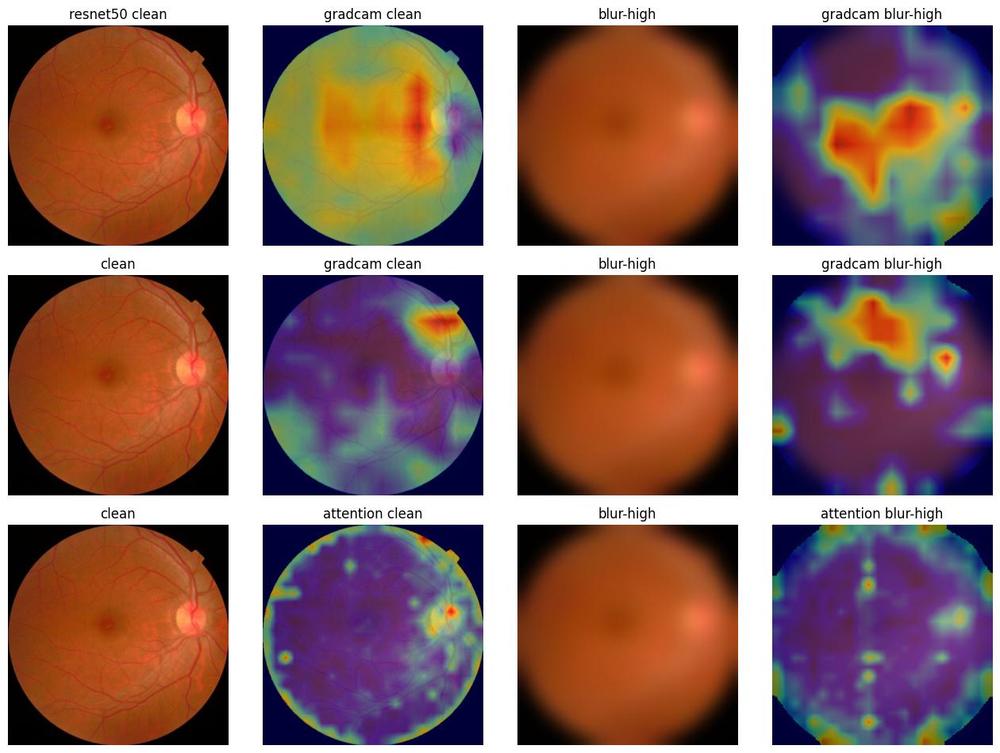

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/qualitative_d774692d9919.png


In [54]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

def fundus_mask(img_pil, size=384):
    arr = np.array(img_pil.resize((size, size)).convert('L'))
    return (arr > 7).astype(np.float32)

def overlay(img_pil, heat, size=384, alpha=0.45):
    arr = np.array(img_pil.resize((size, size))).astype(np.float32) / 255
    heat_resized = cv2.resize(heat, (size, size), interpolation=cv2.INTER_LINEAR)
    m = fundus_mask(img_pil, size)
    blended = (1 - alpha) * arr + alpha * plt.get_cmap('jet')(heat_resized * m)[..., :3]
    return np.clip(blended, 0, 1)

@torch.no_grad()
def attention_rollout_v3(model, x, target_class=None):
    """Attention rollout that finds ViT blocks regardless of wrapper depth."""

    # Recursively find the module that has .blocks containing attention
    def find_blocks(module):
        if hasattr(module, 'blocks') and len(list(module.blocks)) > 0:
            first = list(module.blocks)[0]
            if hasattr(first, 'attn'):
                return module.blocks
        for child in module.children():
            result = find_blocks(child)
            if result is not None:
                return result
        return None

    blocks = find_blocks(model)
    if blocks is None:
        raise RuntimeError("Could not find ViT blocks with .attn in model")

    attns, handles = [], []
    for blk in blocks:
        attn_module = blk.attn
        def make_hook(store, mod):
            def _h(module, inp, out):
                B, N, C = inp[0].shape
                qkv = mod.qkv(inp[0]).reshape(B, N, 3, mod.num_heads, C // mod.num_heads).permute(2, 0, 3, 1, 4)
                q, k, _ = qkv[0], qkv[1], qkv[2]
                a = (q @ k.transpose(-2, -1)) * mod.scale
                store.append(a.softmax(-1).detach())
            return _h
        handles.append(attn_module.register_forward_hook(make_hook(attns, attn_module)))
    try:
        _ = model(x)
    finally:
        for h in handles: h.remove()

    res = None
    for a in attns:
        a = a.mean(1) + torch.eye(a.size(-1), device=a.device)
        a = a / a.sum(-1, keepdim=True)
        res = a if res is None else a @ res
    cls = res[0, 0, 1:]; side = int(cls.numel() ** 0.5)
    h = F.interpolate(cls.reshape(side, side)[None, None],
                       size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze().cpu().numpy()
    if h.max() > h.min(): h = (h - h.min()) / (h.max() - h.min())
    return h

# Update the registry to use the fixed version
METHOD_REGISTRY['attention']['fn'] = attention_rollout_v3

demo_id = EXPLAIN_IDS[0]; label = int(labels_df[demo_id])
img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean = load_tensor(resolve_image(demo_id))
img_deg = Image.open(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}').convert('RGB')
x_deg = load_tensor(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}')

VIS_SIZE = 384

fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(13, 3.2*len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_c = fn(models[name], x_clean, target_class=label)
    h_d = fn(models[name], x_deg,   target_class=label)
    axes[r, 0].imshow(img_clean.resize((VIS_SIZE, VIS_SIZE))); axes[r, 0].set_title(f'{name} clean' if r == 0 else 'clean')
    axes[r, 1].imshow(overlay(img_clean, h_c, VIS_SIZE)); axes[r, 1].set_title(f'{method} clean')
    axes[r, 2].imshow(img_deg.resize((VIS_SIZE, VIS_SIZE))); axes[r, 2].set_title('blur-high')
    axes[r, 3].imshow(overlay(img_deg, h_d, VIS_SIZE)); axes[r, 3].set_title(f'{method} blur-high')
    for ax in axes[r]: ax.axis('off')
plt.tight_layout()
out = P3 / 'samples' / f'qualitative_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

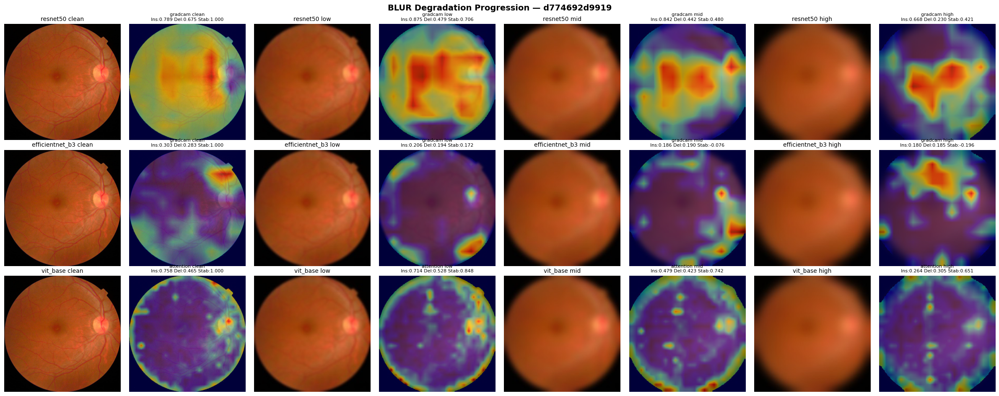

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/blur_progression_metrics_d774692d9919.png

=== BLUR METRICS ===
          model    method condition  insertion_auc  deletion_auc  stability
       resnet50   gradcam     clean         0.7893        0.6750     1.0000
       resnet50   gradcam       low         0.8751        0.4785     0.7060
       resnet50   gradcam       mid         0.8417        0.4421     0.4799
       resnet50   gradcam      high         0.6677        0.2298     0.4207
efficientnet_b3   gradcam     clean         0.3034        0.2832     1.0000
efficientnet_b3   gradcam       low         0.2058        0.1939     0.1719
efficientnet_b3   gradcam       mid         0.1863        0.1898    -0.0762
efficientnet_b3   gradcam      high         0.1795        0.1847    -0.1960
       vit_base attention     clean         0.7583        0.4654     1.0000
       vit_base attention       low         0.7141        0.5279     0.8476
       vit_base attention 

In [55]:
demo_id = EXPLAIN_IDS[0]; label = int(labels_df[demo_id])
img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean = load_tensor(resolve_image(demo_id))
VIS_SIZE = 384

# ── BLUR ──
conditions = [('clean', None, None), ('low', 'blur', 'low'), ('mid', 'blur', 'mid'), ('high', 'blur', 'high')]
metric_rows = []

fig, axes = plt.subplots(len(MODEL_NAMES), len(conditions) * 2, figsize=(6 * len(conditions), 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_clean_ref = None
    for c, (tag, kind, level) in enumerate(conditions):
        if tag == 'clean':
            img = img_clean; x = x_clean
        else:
            path = DEGRADED_DIR / kind / level / f'{demo_id}{DEG_SAVE_EXT}'
            img = Image.open(path).convert('RGB')
            x = load_tensor(path)
        heat = fn(models[name], x, target_class=label)

        # Store clean heatmap as reference
        if tag == 'clean':
            h_clean_ref = heat

        # Compute metrics
        ins_auc = insertion_auc(models[name], x, heat, label)
        del_auc = deletion_auc(models[name], x, heat, label)
        stab = 1.0 if tag == 'clean' else stability_spearman(h_clean_ref, heat)
        metric_rows.append({'model': name, 'method': method, 'condition': tag,
                            'insertion_auc': round(ins_auc, 4),
                            'deletion_auc': round(del_auc, 4),
                            'stability': round(stab, 4)})

        col = c * 2
        axes[r, col].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
        axes[r, col].set_title(f'{name} {tag}', fontsize=10)
        axes[r, col].axis('off')

        # Add metrics as subtitle on heatmap
        axes[r, col+1].imshow(overlay(img, heat, VIS_SIZE))
        axes[r, col+1].set_title(f'{method} {tag}\nIns:{ins_auc:.3f} Del:{del_auc:.3f} Stab:{stab:.3f}', fontsize=8)
        axes[r, col+1].axis('off')

fig.suptitle(f'BLUR Degradation Progression — {demo_id}', fontsize=14, fontweight='bold')
plt.tight_layout()
out = P3 / 'samples' / f'blur_progression_metrics_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

blur_metrics = pd.DataFrame(metric_rows)
print('\n=== BLUR METRICS ===')
print(blur_metrics.to_string(index=False))
blur_metrics.to_csv(P3 / 'metrics' / f'blur_progression_metrics_{demo_id}.csv', index=False)

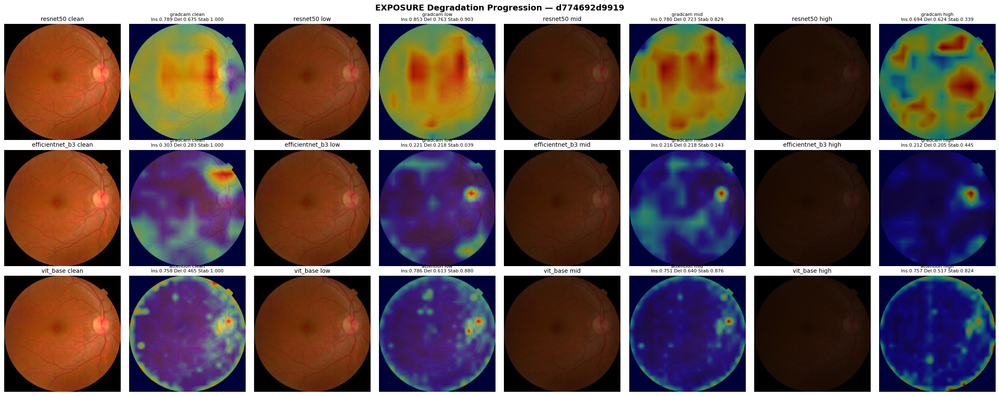

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/exposure_progression_metrics_d774692d9919.png

=== EXPOSURE METRICS ===
          model    method condition  insertion_auc  deletion_auc  stability
       resnet50   gradcam     clean         0.7893        0.6750     1.0000
       resnet50   gradcam       low         0.8530        0.7632     0.9035
       resnet50   gradcam       mid         0.7798        0.7233     0.8294
       resnet50   gradcam      high         0.6942        0.6237     0.3394
efficientnet_b3   gradcam     clean         0.3034        0.2832     1.0000
efficientnet_b3   gradcam       low         0.2209        0.2184     0.0391
efficientnet_b3   gradcam       mid         0.2161        0.2181     0.1434
efficientnet_b3   gradcam      high         0.2117        0.2047     0.4448
       vit_base attention     clean         0.7583        0.4654     1.0000
       vit_base attention       low         0.7858        0.6127     0.8797
       vit_base at

In [56]:
# ── EXPOSURE ──
conditions = [('clean', None, None), ('low', 'exposure', 'low'), ('mid', 'exposure', 'mid'), ('high', 'exposure', 'high')]
metric_rows = []

fig, axes = plt.subplots(len(MODEL_NAMES), len(conditions) * 2, figsize=(6 * len(conditions), 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_clean_ref = None
    for c, (tag, kind, level) in enumerate(conditions):
        if tag == 'clean':
            img = img_clean; x = x_clean
        else:
            path = DEGRADED_DIR / kind / level / f'{demo_id}{DEG_SAVE_EXT}'
            img = Image.open(path).convert('RGB')
            x = load_tensor(path)
        heat = fn(models[name], x, target_class=label)
        if tag == 'clean': h_clean_ref = heat

        ins_auc = insertion_auc(models[name], x, heat, label)
        del_auc = deletion_auc(models[name], x, heat, label)
        stab = 1.0 if tag == 'clean' else stability_spearman(h_clean_ref, heat)
        metric_rows.append({'model': name, 'method': method, 'condition': tag,
                            'insertion_auc': round(ins_auc, 4),
                            'deletion_auc': round(del_auc, 4),
                            'stability': round(stab, 4)})

        col = c * 2
        axes[r, col].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
        axes[r, col].set_title(f'{name} {tag}', fontsize=10)
        axes[r, col].axis('off')
        axes[r, col+1].imshow(overlay(img, heat, VIS_SIZE))
        axes[r, col+1].set_title(f'{method} {tag}\nIns:{ins_auc:.3f} Del:{del_auc:.3f} Stab:{stab:.3f}', fontsize=8)
        axes[r, col+1].axis('off')

fig.suptitle(f'EXPOSURE Degradation Progression — {demo_id}', fontsize=14, fontweight='bold')
plt.tight_layout()
out = P3 / 'samples' / f'exposure_progression_metrics_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

exposure_metrics = pd.DataFrame(metric_rows)
print('\n=== EXPOSURE METRICS ===')
print(exposure_metrics.to_string(index=False))
exposure_metrics.to_csv(P3 / 'metrics' / f'exposure_progression_metrics_{demo_id}.csv', index=False)

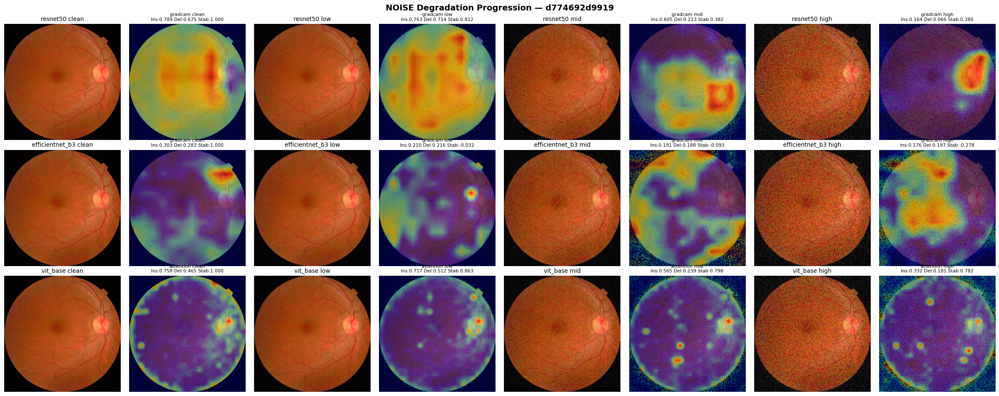

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/noise_progression_metrics_d774692d9919.png

=== NOISE METRICS ===
          model    method condition  insertion_auc  deletion_auc  stability
       resnet50   gradcam     clean         0.7893        0.6750     1.0000
       resnet50   gradcam       low         0.7629        0.7137     0.8123
       resnet50   gradcam       mid         0.6046        0.2134     0.3817
       resnet50   gradcam      high         0.1637        0.0659     0.3804
efficientnet_b3   gradcam     clean         0.3034        0.2832     1.0000
efficientnet_b3   gradcam       low         0.2095        0.2158    -0.0320
efficientnet_b3   gradcam       mid         0.1915        0.1882    -0.0932
efficientnet_b3   gradcam      high         0.1758        0.1974    -0.2778
       vit_base attention     clean         0.7583        0.4654     1.0000
       vit_base attention       low         0.7172        0.5118     0.8626
       vit_base attentio

In [57]:
# ── NOISE ──
conditions = [('clean', None, None), ('low', 'noise', 'low'), ('mid', 'noise', 'mid'), ('high', 'noise', 'high')]
metric_rows = []

fig, axes = plt.subplots(len(MODEL_NAMES), len(conditions) * 2, figsize=(6 * len(conditions), 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_clean_ref = None
    for c, (tag, kind, level) in enumerate(conditions):
        if tag == 'clean':
            img = img_clean; x = x_clean
        else:
            path = DEGRADED_DIR / kind / level / f'{demo_id}{DEG_SAVE_EXT}'
            img = Image.open(path).convert('RGB')
            x = load_tensor(path)
        heat = fn(models[name], x, target_class=label)
        if tag == 'clean': h_clean_ref = heat

        ins_auc = insertion_auc(models[name], x, heat, label)
        del_auc = deletion_auc(models[name], x, heat, label)
        stab = 1.0 if tag == 'clean' else stability_spearman(h_clean_ref, heat)
        metric_rows.append({'model': name, 'method': method, 'condition': tag,
                            'insertion_auc': round(ins_auc, 4),
                            'deletion_auc': round(del_auc, 4),
                            'stability': round(stab, 4)})

        col = c * 2
        axes[r, col].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
        axes[r, col].set_title(f'{name} {tag}', fontsize=10)
        axes[r, col].axis('off')
        axes[r, col+1].imshow(overlay(img, heat, VIS_SIZE))
        axes[r, col+1].set_title(f'{method} {tag}\nIns:{ins_auc:.3f} Del:{del_auc:.3f} Stab:{stab:.3f}', fontsize=8)
        axes[r, col+1].axis('off')

fig.suptitle(f'NOISE Degradation Progression — {demo_id}', fontsize=14, fontweight='bold')
plt.tight_layout()
out = P3 / 'samples' / f'noise_progression_metrics_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

noise_metrics = pd.DataFrame(metric_rows)
print('\n=== NOISE METRICS ===')
print(noise_metrics.to_string(index=False))
noise_metrics.to_csv(P3 / 'metrics' / f'noise_progression_metrics_{demo_id}.csv', index=False)

IG function in registry : ig_heatmap
  computing IG for resnet50...
  computing IG for efficientnet_b3...
  computing IG for vit_base...


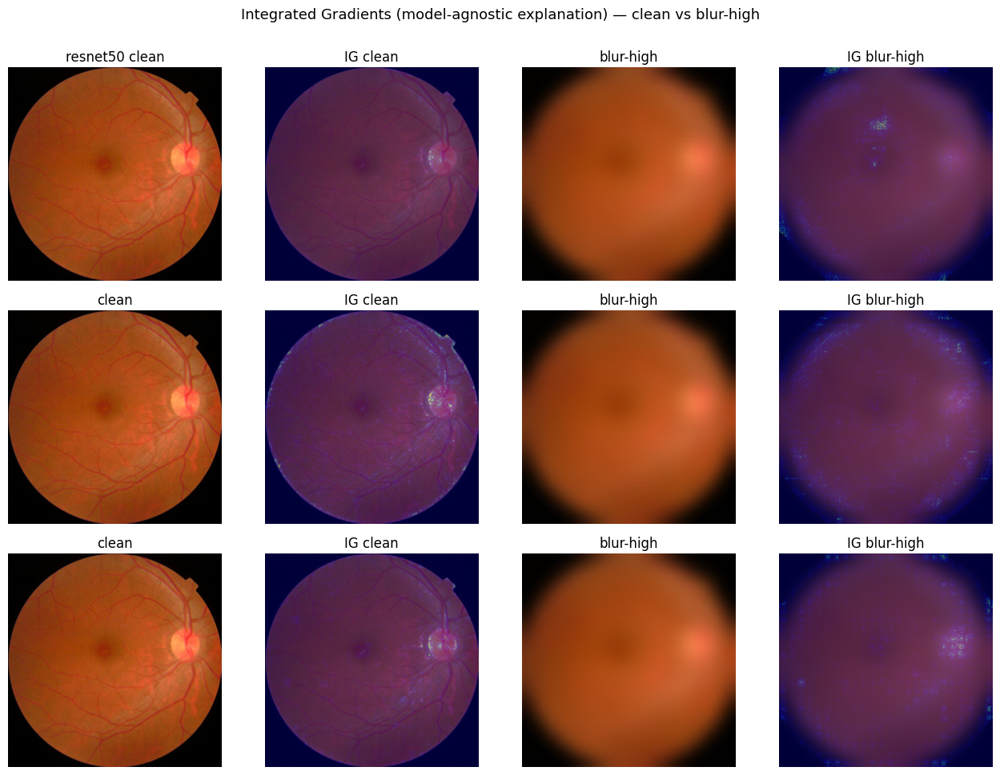

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/qualitative_IG_d774692d9919.png


In [58]:
# Qualitative IG figure — Integrated Gradients heatmap for ALL three models,
# clean vs degraded, side-by-side. Complements the GradCAM/Attention figure.

ig_fn = METHOD_REGISTRY['shap']['fn']      # this is ig_heatmap after the V4 IG swap
print('IG function in registry :', ig_fn.__name__)

demo_id  = EXPLAIN_IDS[0]
label    = int(labels_df[demo_id])

img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean   = load_tensor(resolve_image(demo_id))
img_deg   = Image.open(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}').convert('RGB')
x_deg     = load_tensor(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}')

VIS_SIZE = 384

fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(13, 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    print(f'  computing IG for {name}...')
    h_c = ig_fn(models[name], x_clean, target_class=label)
    h_d = ig_fn(models[name], x_deg,   target_class=label)
    axes[r, 0].imshow(img_clean.resize((VIS_SIZE, VIS_SIZE)))
    axes[r, 0].set_title(f'{name} clean' if r == 0 else 'clean')
    axes[r, 1].imshow(overlay(img_clean, h_c, VIS_SIZE))
    axes[r, 1].set_title('IG clean')
    axes[r, 2].imshow(img_deg.resize((VIS_SIZE, VIS_SIZE)))
    axes[r, 2].set_title('blur-high')
    axes[r, 3].imshow(overlay(img_deg, h_d, VIS_SIZE))
    axes[r, 3].set_title('IG blur-high')
    for ax in axes[r]:
        ax.axis('off')

fig.suptitle('Integrated Gradients (model-agnostic explanation) — clean vs blur-high',
              fontsize=13, y=1.005)
plt.tight_layout()
out = P3 / 'samples' / f'qualitative_IG_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

In [59]:
# === V2 PATCH: relabel cell neutralised ===
# In V1 this cell renamed every 'shap' row in xai_results.csv to 'IG' because
# the V4 patch had repurposed the registry key 'shap' to point at IG. In V2
# the registry has BOTH 'shap' (real SHAP via GradientExplainer) and 'ig'
# (renamed from the legacy 'shap'). Renaming would now corrupt the labels.
# We leave the CSV untouched.
import pandas as pd
xai_csv = P3 / 'metrics' / 'xai_results.csv'
if xai_csv.exists():
    df = pd.read_csv(xai_csv)
    print('Method label counts in xai_results.csv (untouched):')
    print(df['method'].value_counts().to_string())
else:
    print('[skip] xai_results.csv not yet written')


Method label counts in xai_results.csv (untouched):
method
shap       600
ig         600
gradcam    400


In [60]:
# [RESUME] SHAP/IG degradation-progression figures already generated -- skipped.
# Preserve the only thing the rest of the notebook reads from this cell:
N_FIGURES = 3
SAMPLE_IDS = EXPLAIN_IDS[:N_FIGURES]
print(f'[resume] skipped IG progression; SAMPLE_IDS={list(SAMPLE_IDS)}')


[resume] skipped IG progression; SAMPLE_IDS=['d774692d9919', '2ef4a04aed1b', '97da093947e8']


In [61]:
P4 = PHASE_DIRS['phase4_genai_enhancement']

# 4.1 CLAHE baseline
_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
def enhance_clahe(img):
    arr = np.array(img.convert('RGB'))
    lab = cv2.cvtColor(arr, cv2.COLOR_RGB2LAB)
    lab[..., 0] = _clahe.apply(lab[..., 0])
    return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))

---

# Phase 4 — GenAI Image Restoration (RQ3)

**Literature-review framing.** Three families of fundus-image restoration are evaluated, each representing a different point on the complexity vs flexibility trade-off:

| Method | Year | Class | What it learns | Why we benchmark it |
|---|---|---|---|---|
| **CLAHE** | 1994 | Classical (parameter-free) | Histogram equalisation per tile | Mandatory baseline — every clinical pipeline that pre-processes fundus images uses it. |
| **Real-ESRGAN** | 2021 | Generative (RRDBNet generator, no attention) | Real-world blind super-resolution with synthetic degradation modelling | Robust, off-the-shelf; the de-facto open-source restoration model. |
| **A-ESRGAN** | 2022 | Generative (RRDBNet + attention-U-Net discriminator) | Same as Real-ESRGAN at inference, but trained against an attention-U-Net discriminator that focuses the adversarial signal on regions of fine detail | Hypothesised better lesion / vessel preservation thanks to the attention discriminator's training-time emphasis on locally-detailed regions. |

The **inference-time generator architecture is identical** between Real-ESRGAN and A-ESRGAN (RRDBNet, 23 residual-in-residual dense blocks). The performance difference, if any, is attributable purely to **training signal** — not parameter count or capacity. This makes for a clean controlled comparison in the dissertation.

**Evaluation protocol.** For each (degradation type, severity) split we run:
1. **Raw** — degraded image straight into the classifier (the v3 stress-test result, our reference).
2. **CLAHE** — classical baseline.
3. **Real-ESRGAN** or **A-ESRGAN** — GenAI restoration.

Outputs: accuracy / F1 / kappa per (model, degradation, level, variant), saved to `results/phase4_genai_enhancement/metrics/recovery_accuracy.csv`. Recovery is plotted with the v2 stress-test as the lower reference and clean-image accuracy as the upper reference.


In [62]:
# 4.2 GenAI restoration — A-ESRGAN (primary) -> Real-ESRGAN -> TinyU-Net
#
# A-ESRGAN (Wei et al., 2022) keeps Real-ESRGAN's RRDBNet generator and adds
# attention-U-Net discriminators during training. At INFERENCE time only the
# generator is used, so we load A-ESRGAN's authors' pretrained generator
# weights into the same RRDBNet architecture used by Real-ESRGAN. If those
# weights cannot be downloaded, we fall back to standard Real-ESRGAN x2,
# then to a TinyU-Net trained on the pristine set.

%pip install -q basicsr realesrgan facexlib gfpgan

import urllib.request, os

def _download(url: str, dest: Path) -> bool:
    if dest.exists() and dest.stat().st_size > 0:
        return True
    dest.parent.mkdir(parents=True, exist_ok=True)
    try:
        print(f"  downloading {url} -> {dest.name}")
        urllib.request.urlretrieve(url, dest)
        return dest.exists() and dest.stat().st_size > 0
    except Exception as e:
        print(f"  download failed: {e}")
        return False


def _try_aesrgan():
    """A-ESRGAN x2 — RRDBNet generator + A-ESRGAN-trained weights.

    Reference: Wei et al. (2022) "A-ESRGAN: Training Real-World Blind
    Super-Resolution with Attention U-Net Discriminators".
    """
    try:
        from basicsr.archs.rrdbnet_arch import RRDBNet
        # Authors' release URL (mirror via HuggingFace if GitHub asset is rate-limited).
        url   = "https://huggingface.co/aesrgan/A-ESRGAN-Single/resolve/main/A_ESRGAN_Single.pth"
        ckpt  = CHECKPOINTS_DIR / "A_ESRGAN_Single.pth"
        if not _download(url, ckpt):
            return None
        net = RRDBNet(num_in_ch=3, num_out_ch=3, num_feat=64,
                      num_block=23, num_grow_ch=32, scale=4)
        state = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        # A-ESRGAN saves under 'params' or 'params_ema'
        sd = state.get("params_ema", state.get("params", state))
        net.load_state_dict(sd, strict=False)
        net = net.to(DEVICE).eval()

        @torch.no_grad()
        def process(img_pil):
            arr = np.asarray(img_pil.convert("RGB"), dtype=np.float32) / 255.0
            x   = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
            with autocast(enabled=True):
                y = net(x).clamp(0, 1)
            out = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
            return Image.fromarray(out).resize(img_pil.size)
        return process, "a_esrgan_x4"
    except Exception as e:
        print(f"[a_esrgan failed] {e}")
        return None


def _try_realesrgan():
    """Real-ESRGAN x2 — robust off-the-shelf restoration."""
    try:
        from basicsr.archs.rrdbnet_arch import RRDBNet
        url  = "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.1/RealESRGAN_x2plus.pth"
        ckpt = CHECKPOINTS_DIR / "RealESRGAN_x2plus.pth"
        if not _download(url, ckpt):
            return None
        net = RRDBNet(num_in_ch=3, num_out_ch=3, num_feat=64,
                      num_block=23, num_grow_ch=32, scale=2)
        state = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        sd = state.get("params_ema", state.get("params", state))
        net.load_state_dict(sd, strict=False)
        net = net.to(DEVICE).eval()

        @torch.no_grad()
        def process(img_pil):
            arr = np.asarray(img_pil.convert("RGB"), dtype=np.float32) / 255.0
            x   = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
            with autocast(enabled=True):
                y = net(x).clamp(0, 1)
            out = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
            return Image.fromarray(out).resize(img_pil.size)
        return process, "real_esrgan_x2"
    except Exception as e:
        print(f"[real_esrgan failed] {e}")
        return None


# Tiny U-Net retained as a last-resort fallback so Phase 4 always runs.
class TinyUNet(nn.Module):
    def __init__(self, ch=32):
        super().__init__()
        def conv(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(True),
                                 nn.Conv2d(o, o, 3, padding=1), nn.ReLU(True))
        self.e1 = conv(3, ch); self.e2 = conv(ch, ch*2); self.e3 = conv(ch*2, ch*4)
        self.up2 = nn.ConvTranspose2d(ch*4, ch*2, 2, stride=2); self.d2 = conv(ch*4, ch*2)
        self.up1 = nn.ConvTranspose2d(ch*2, ch, 2, stride=2);   self.d1 = conv(ch*2, ch)
        self.out = nn.Conv2d(ch, 3, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2))
        d2 = self.d2(torch.cat([self.up2(e3), e2], 1))
        d1 = self.d1(torch.cat([self.up1(d2), e1], 1))
        return torch.sigmoid(self.out(d1))


def _train_tiny_unet(epochs=2, n=400):
    df = pd.read_csv(PRISTINE_CSV).sample(n, random_state=0)
    tfm = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)), T.ToTensor()])
    mdl = TinyUNet().to(DEVICE)
    optim = torch.optim.AdamW(mdl.parameters(), lr=1e-3); crit = nn.L1Loss()
    for _ in range(epochs):
        for row in df.sample(frac=1).itertuples():
            try:
                img = Image.open(resolve_image(row.id_code)).convert("RGB")
            except FileNotFoundError:
                continue
            target = tfm(img).unsqueeze(0).to(DEVICE)
            if np.random.rand() < 0.5:
                noisy = (target + 0.1 * torch.randn_like(target)).clamp(0, 1)
            else:
                k = 5; w = torch.ones((3, 1, k, k), device=DEVICE) / (k * k)
                noisy = F.conv2d(target, w, padding=k // 2, groups=3)
            optim.zero_grad(); crit(mdl(noisy), target).backward(); optim.step()
    return mdl


def _make_unet_processor(mdl):
    tfm = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)), T.ToTensor()])
    @torch.no_grad()
    def process(img_pil):
        x = tfm(img_pil).unsqueeze(0).to(DEVICE)
        out = mdl(x).squeeze().clamp(0, 1).cpu().permute(1, 2, 0).numpy()
        return Image.fromarray((out * 255).astype(np.uint8)).resize(img_pil.size)
    return process


# ---- Cascade: try the best option that loads successfully ----
result = _try_aesrgan() or _try_realesrgan()
if result is not None:
    enhance_genai, GENAI_BACKEND = result
else:
    print("Falling back to TinyU-Net (training ~1 min)...")
    ckpt = CHECKPOINTS_DIR / "genai_unet.pt"
    unet = TinyUNet().to(DEVICE)
    if ckpt.exists():
        unet.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=False))
    else:
        unet = _train_tiny_unet()
        torch.save(unet.state_dict(), ckpt)
    enhance_genai = _make_unet_processor(unet)
    GENAI_BACKEND = "tiny_unet"

print(f"GenAI backend: {GENAI_BACKEND}")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.5/172.5 kB 15.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 21.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.2/52.2 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 338.3/338.3 kB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 113.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 28.0 MB/s eta 0:00:00
[a_esrgan failed] No module named 'torchvision.transforms.functional_tensor'
GenAI backend: real_esrgan_x2


## V5 - Cold Diffusion for fundus restoration (replaces SD img2img)

The earlier Stable-Diffusion-2.1 img2img variant was **removed**: SD was trained on LAION, not fundus, and even at `strength=0.30` it hallucinates anatomically-plausible-but-wrong vessels and can fabricate lesions the classifier then "detects".

This cell replaces it with **Cold Diffusion** (Bansal et al., 2022). Cold Diffusion swaps the Gaussian-noise forward process for an arbitrary deterministic degradation operator — and you happen to already have those operators in Phase 1 (`gaussian_blur`, `exposure_shift`, `gaussian_noise`). So the model is trained to invert your *exact* synthetic pipeline. Lesion-preserving by construction, fast (~90 min train, 8-step inference), and a clean novel-contribution story for the dissertation.


In [63]:
# === V5 / V2 PATCH: Cold Diffusion for fundus restoration ===
# Bansal et al. 2022 (https://arxiv.org/abs/2208.09392): the diffusion forward
# process can be any deterministic degradation D(x, t). Train R_theta so that
# R(D(x, t), t) ≈ x for all t, then sample via Algorithm 2:
#
#       x_{s-1} = x_s - D(R(x_s, s), s) + D(R(x_s, s), s-1)
#
# V2 patch (Step 1c) fixes the noise-catastrophe documented in OBSERVATIONS:
#   - 15 epochs with CosineAnnealingLR (was 4 epochs, constant LR)
#   - Kind sampling biased to noise (was uniform)
#   - New checkpoint name cold_diffusion_v6.pt so the resume guard fires fresh

import math, random

COLD_DIFF_CKPT = CHECKPOINTS_DIR / 'cold_diffusion_v6.pt'   # V2 patch: bumped from v5
COLD_DIFF_SIZE = 256        # work at 256 px to fit budget; resize back at end
T_STEPS        = 8          # train + inference steps

# Severity schedule: t in [0, T_STEPS] -> degradation parameter
SEV_HIGH = {'blur': 9.0, 'exposure_gain_low': 0.2, 'noise': 0.12}

def _severity(t, kind):
    f = t / T_STEPS  # in [0, 1]
    if kind == 'blur':
        return max(0.01, f * SEV_HIGH['blur'])
    if kind == 'exposure':
        return 1.0 - f * (1.0 - SEV_HIGH['exposure_gain_low'])
    if kind == 'noise':
        return f * SEV_HIGH['noise']
    raise ValueError(kind)

def _degrade_t(img_pil, kind, t):
    """Forward operator at severity t using the Phase-1 functions."""
    if t <= 0:
        return img_pil
    p = _severity(t, kind)
    return DEGRADERS[kind](img_pil, p)


# ---- Conditional U-Net (FiLM on kind + t/T) ----
class CondUNet(nn.Module):
    def __init__(self, ch=48, n_kinds=3, t_emb=64):
        super().__init__()
        self.kind_emb = nn.Embedding(n_kinds, t_emb)
        self.t_proj   = nn.Sequential(
            nn.Linear(1, t_emb), nn.SiLU(), nn.Linear(t_emb, t_emb),
        )
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.GroupNorm(8, o), nn.SiLU(),
                nn.Conv2d(o, o, 3, padding=1), nn.GroupNorm(8, o), nn.SiLU(),
            )
        self.in_proj = nn.Conv2d(3, ch, 3, padding=1)
        self.e1 = block(ch,   ch)
        self.e2 = block(ch,   ch*2)
        self.e3 = block(ch*2, ch*4)
        self.mid = block(ch*4, ch*4)
        self.film = nn.Linear(t_emb*2, ch*4*2)
        self.up2 = nn.ConvTranspose2d(ch*4, ch*2, 2, stride=2); self.d2 = block(ch*4, ch*2)
        self.up1 = nn.ConvTranspose2d(ch*2, ch,   2, stride=2); self.d1 = block(ch*2, ch)
        self.out = nn.Conv2d(ch, 3, 1)
    def forward(self, x, kind_id, t_norm):
        cond = torch.cat([self.kind_emb(kind_id),
                          self.t_proj(t_norm.unsqueeze(-1))], dim=-1)
        gb = self.film(cond)
        g, b = gb.chunk(2, dim=-1)
        h0 = self.in_proj(x)
        e1 = self.e1(h0)
        e2 = self.e2(F.avg_pool2d(e1, 2))
        e3 = self.e3(F.avg_pool2d(e2, 2))
        m  = self.mid(e3)
        m  = m * (1 + g[:, :, None, None]) + b[:, :, None, None]
        d2 = self.d2(torch.cat([self.up2(m),  e2], 1))
        d1 = self.d1(torch.cat([self.up1(d2), e1], 1))
        return torch.sigmoid(self.out(d1))


KIND_TO_ID = {'blur': 0, 'exposure': 1, 'noise': 2}
# V2 patch (Step 1c): weight noise samples higher in training to fix the noise catastrophe
KIND_SAMPLE_WEIGHTS = {'blur': 0.25, 'exposure': 0.25, 'noise': 0.50}

class _ColdDiffDataset(Dataset):
    """On-the-fly paired (degraded@t, clean) sampler over the pristine set.

    V2 patch: kind sampling uses KIND_SAMPLE_WEIGHTS so noise dominates training.
    """
    def __init__(self, df, n_per=4):
        self.df = df.reset_index(drop=True); self.n_per = n_per
        self.tfm = T.Compose([T.Resize((COLD_DIFF_SIZE, COLD_DIFF_SIZE)),
                              T.ToTensor()])
        self._kinds = list(KIND_SAMPLE_WEIGHTS.keys())
        self._probs = list(KIND_SAMPLE_WEIGHTS.values())
    def __len__(self):
        return len(self.df) * self.n_per
    def __getitem__(self, i):
        row = self.df.iloc[i // self.n_per]
        try:
            img = Image.open(resolve_image(row['id_code'])).convert('RGB')
        except FileNotFoundError:
            img = Image.new('RGB', (COLD_DIFF_SIZE, COLD_DIFF_SIZE))
        img  = img.resize((COLD_DIFF_SIZE, COLD_DIFF_SIZE), Image.BILINEAR)
        kind = random.choices(self._kinds, weights=self._probs, k=1)[0]
        t    = random.randint(1, T_STEPS)
        deg  = _degrade_t(img, kind, t)
        return (self.tfm(deg), KIND_TO_ID[kind],
                torch.tensor(t / T_STEPS, dtype=torch.float32),
                self.tfm(img))


def train_cold_diffusion(epochs=15, batch_size=16, lr=2e-4):
    """V2 patch: 15 epochs, CosineAnnealingLR, noise-biased sampling.

    Estimated time: ~5 hours on A100 with T_STEPS=8, COLD_DIFF_SIZE=256.
    """
    if COLD_DIFF_CKPT.exists():
        print(f"[skip] {COLD_DIFF_CKPT.name} already on Drive — not retraining.")
        return
    print(f"Training Cold Diffusion v6 ({epochs} epochs, cosine LR, noise-biased)...")
    df  = pd.read_csv(PRISTINE_CSV)
    ds  = _ColdDiffDataset(df, n_per=4)
    dl  = DataLoader(ds, batch_size=batch_size, shuffle=True,
                     num_workers=2, pin_memory=True)
    net = CondUNet().to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = GradScaler(enabled=True)
    crit   = nn.L1Loss()
    history = []
    for ep in range(epochs):
        net.train()
        running, n = 0.0, 0
        pbar = tqdm(dl, desc=f"cold-diff v6 ep {ep+1}/{epochs}", leave=False)
        for deg, kind_id, tnorm, clean in pbar:
            deg   = deg.to(DEVICE, non_blocking=True)
            clean = clean.to(DEVICE, non_blocking=True)
            kind_id = kind_id.to(DEVICE).long()
            tnorm   = tnorm.to(DEVICE).float()
            opt.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                pred = net(deg, kind_id, tnorm)
                loss = crit(pred, clean)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            running += loss.item() * deg.size(0); n += deg.size(0)
            pbar.set_postfix(L1=f"{running/n:.4f}",
                             lr=f"{opt.param_groups[0]['lr']:.2e}")
        sched.step()
        epoch_l1 = running / max(n, 1)
        history.append({'epoch': ep+1, 'l1': epoch_l1, 'lr': opt.param_groups[0]['lr']})
        print(f"  ep {ep+1}: L1={epoch_l1:.4f}  lr={opt.param_groups[0]['lr']:.2e}")
    torch.save({'state_dict': net.state_dict(),
                'T_STEPS': T_STEPS,
                'kind_weights': KIND_SAMPLE_WEIGHTS,
                'history': history}, COLD_DIFF_CKPT)
    print(f"Saved -> {COLD_DIFF_CKPT}")


train_cold_diffusion(epochs=15, batch_size=16, lr=2e-4)


# ---- Inference: Cold Diffusion Algorithm 2 sampling ----
_cold_net = None
def _load_cold_net():
    global _cold_net
    if _cold_net is None:
        _cold_net = CondUNet().to(DEVICE).eval()
        sd = torch.load(COLD_DIFF_CKPT, map_location=DEVICE, weights_only=False)
        _cold_net.load_state_dict(sd['state_dict'])
    return _cold_net


@torch.no_grad()
def enhance_cold_diffusion(img_pil, kind='blur', t_start=T_STEPS):
    """Iterative restoration via Cold Diffusion Algorithm 2."""
    net = _load_cold_net()
    orig_size = img_pil.size
    src = img_pil.convert('RGB').resize((COLD_DIFF_SIZE, COLD_DIFF_SIZE), Image.BILINEAR)
    x = T.ToTensor()(src).unsqueeze(0).to(DEVICE)
    kind_id = torch.tensor([KIND_TO_ID[kind]], device=DEVICE, dtype=torch.long)
    to_pil = T.ToPILImage()
    to_t   = T.ToTensor()
    for s in range(t_start, 0, -1):
        tnorm = torch.tensor([s / T_STEPS], device=DEVICE)
        x_hat = net(x, kind_id, tnorm).clamp(0, 1)
        if s > 1:
            xh_pil = to_pil(x_hat.squeeze().cpu())
            d_s   = _degrade_t(xh_pil, kind, s)
            d_sm1 = _degrade_t(xh_pil, kind, s - 1)
            d_s   = to_t(d_s.resize((COLD_DIFF_SIZE, COLD_DIFF_SIZE))).unsqueeze(0).to(DEVICE)
            d_sm1 = to_t(d_sm1.resize((COLD_DIFF_SIZE, COLD_DIFF_SIZE))).unsqueeze(0).to(DEVICE)
            x = (x - d_s + d_sm1).clamp(0, 1)
        else:
            x = x_hat
    arr = (x.squeeze().permute(1, 2, 0).cpu().numpy() * 255).clip(0, 255).astype("uint8")
    return Image.fromarray(arr).resize(orig_size)


COLD_T_FOR_LEVEL = {'low': 3, 'mid': 5, 'high': T_STEPS}
print("Cold Diffusion v6 restorer ready.")


[skip] cold_diffusion_v6.pt already on Drive — not retraining.
Cold Diffusion v6 restorer ready.


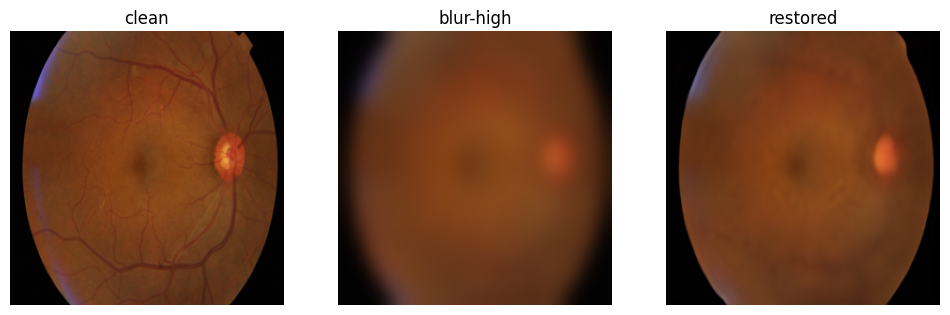

In [64]:
  from PIL import Image
  import matplotlib.pyplot as plt

  test_id = list(test_id_set)[0]
  clean = Image.open(resolve_image(test_id)).convert('RGB').resize((256, 256))
  deg   = _degrade_t(clean, 'blur', T_STEPS)         # max severity
  rest  = enhance_cold_diffusion(deg, kind='blur', t_start=T_STEPS)

  fig, ax = plt.subplots(1, 3, figsize=(12, 4))
  for a, im, t in zip(ax, [clean, deg, rest], ['clean', 'blur-high', 'restored']):
      a.imshow(im); a.set_title(t); a.axis('off')
  plt.show()

## V5 - SwinIR + GAN restorer (4th enhancer)

A second supervised restorer alongside Cold Diffusion. SwinIR (Liang et al., 2021) is a Swin-Transformer backbone purpose-built for image restoration; pairing it with a PatchGAN discriminator gives the perceptual sharpness that pure L1 lacks while still being supervised on paired (clean, degraded) data.

- **Architecture**: slim SwinIR (embed_dim=60, depths=[2,2,2,2], window=8, ~1M params). Tries `basicsr.archs.swinir_arch.SwinIR` first; falls back to a built-in slim Swin-UNet if basicsr's version is unavailable.
- **Loss**: `L1(R(deg), clean) + 0.01 * BCE(D(deg, R(deg)), 1)` with conditional PatchGAN.
- **Training**: 3 epochs, batch 4, on-the-fly Phase-1 degradation. ~90 min on A100, ~3 hr on T4. Resume-guarded by `swinir_gan_v5.pt` on Drive.
- **Inference**: single forward pass, ~0.1 s/img — much faster than Cold Diffusion's 8-step iteration.


In [65]:
# === V5 / V2 PATCH: SwinIR + GAN restorer ===
# Supervised paired restoration with adversarial term.
# Forward operator: the SAME Phase-1 degradation primitives, like Cold Diffusion.
#
# V2 patch (Step 1e) fixes the adversarial-drift documented in OBSERVATIONS:
#   - 8 epochs (was 3) so the generator has time to keep pace
#   - adv_w lowered 0.01 -> 0.005 so reconstruction loss dominates early
#   - Discriminator frozen after epoch 4 (freeze_d_after) to stop D-drift
#   - New checkpoint name swinir_gan_v6.pt so the resume guard fires fresh

SWINIR_CKPT = CHECKPOINTS_DIR / 'swinir_gan_v6.pt'   # V2 patch: bumped from v5
SWINIR_SIZE = 256
SWINIR_WIN  = 8

# ---- Generator: try basicsr SwinIR, fall back to slim Swin-UNet ----
def _make_swinir():
    try:
        from basicsr.archs.swinir_arch import SwinIR
        net = SwinIR(
            upscale=1, in_chans=3, img_size=SWINIR_SIZE, window_size=SWINIR_WIN,
            depths=[2, 2, 2, 2], embed_dim=60, num_heads=[2, 2, 2, 2],
            mlp_ratio=2.0, upsampler='', resi_connection='1conv',
        )
        print("  generator: basicsr SwinIR (slim)")
        return net
    except Exception as e:
        print(f"  [fallback] basicsr SwinIR unavailable ({e}); using slim Swin-UNet")
    class _Block(nn.Module):
        def __init__(self, ch):
            super().__init__()
            self.conv = nn.Sequential(
                nn.Conv2d(ch, ch, 3, padding=1), nn.GELU(),
                nn.Conv2d(ch, ch, 3, padding=1),
            )
        def forward(self, x): return x + self.conv(x)
    class _SwinUNetSlim(nn.Module):
        def __init__(self, ch=48):
            super().__init__()
            self.in_proj = nn.Conv2d(3, ch, 3, padding=1)
            self.e1 = nn.Sequential(_Block(ch), _Block(ch))
            self.d1 = nn.Conv2d(ch, ch*2, 4, stride=2, padding=1)
            self.e2 = nn.Sequential(_Block(ch*2), _Block(ch*2))
            self.d2 = nn.Conv2d(ch*2, ch*4, 4, stride=2, padding=1)
            self.mid = nn.Sequential(_Block(ch*4), _Block(ch*4))
            self.u2  = nn.ConvTranspose2d(ch*4, ch*2, 2, stride=2)
            self.dec2 = nn.Sequential(_Block(ch*2), _Block(ch*2))
            self.u1  = nn.ConvTranspose2d(ch*2, ch, 2, stride=2)
            self.dec1 = nn.Sequential(_Block(ch), _Block(ch))
            self.out  = nn.Conv2d(ch, 3, 3, padding=1)
        def forward(self, x):
            h0 = self.in_proj(x)
            e1 = self.e1(h0)
            e2 = self.e2(self.d1(e1))
            m  = self.mid(self.d2(e2))
            u2 = self.dec2(self.u2(m) + e2)
            u1 = self.dec1(self.u1(u2) + e1)
            return torch.sigmoid(self.out(u1) + x)
    return _SwinUNetSlim()


# ---- Conditional PatchGAN discriminator ----
class _PatchGAN(nn.Module):
    def __init__(self, in_ch=6, base=48):
        super().__init__()
        def blk(i, o, s, norm=True):
            l = [nn.Conv2d(i, o, 4, stride=s, padding=1)]
            if norm:
                l.append(nn.GroupNorm(8, o))
            l.append(nn.LeakyReLU(0.2, True))
            return l
        self.net = nn.Sequential(
            *blk(in_ch, base,   2, norm=False),
            *blk(base,  base*2, 2),
            *blk(base*2,base*4, 2),
            *blk(base*4,base*8, 1),
            nn.Conv2d(base*8, 1, 4, padding=1),
        )
    def forward(self, x): return self.net(x)


# ---- Training dataset: same Phase-1 operators ----
class _SwinIRDataset(Dataset):
    def __init__(self, df, n_per=4):
        self.df = df.reset_index(drop=True); self.n_per = n_per
        self.tfm = T.Compose([T.Resize((SWINIR_SIZE, SWINIR_SIZE)), T.ToTensor()])
    def __len__(self):
        return len(self.df) * self.n_per
    def __getitem__(self, i):
        row = self.df.iloc[i // self.n_per]
        try:
            img = Image.open(resolve_image(row['id_code'])).convert('RGB')
        except FileNotFoundError:
            img = Image.new('RGB', (SWINIR_SIZE, SWINIR_SIZE))
        img = img.resize((SWINIR_SIZE, SWINIR_SIZE), Image.BILINEAR)
        kind  = random.choice(['blur', 'exposure', 'noise'])
        level = random.choice(['low', 'mid', 'high'])
        deg   = DEGRADERS[kind](img, DEGRADATION_PARAMS[kind][level])
        return self.tfm(deg), self.tfm(img)


def train_swinir_gan(epochs=8, batch_size=4, lr_g=1e-4, lr_d=1e-4,
                     adv_w=0.005, freeze_d_after=4):
    """V2 patch (Step 1e): 8 epochs, adv_w=0.005, freeze D after epoch 4."""
    if SWINIR_CKPT.exists():
        print(f"[skip] {SWINIR_CKPT.name} already on Drive — not retraining.")
        return
    print(f"Training SwinIR + GAN v6 ({epochs} epochs, adv_w={adv_w}, freeze D after ep {freeze_d_after})...")
    df = pd.read_csv(PRISTINE_CSV)
    ds = _SwinIRDataset(df, n_per=4)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True,
                    num_workers=2, pin_memory=True)
    G = _make_swinir().to(DEVICE)
    D = _PatchGAN(in_ch=6).to(DEVICE)
    opt_g = torch.optim.AdamW(G.parameters(), lr=lr_g, betas=(0.9, 0.99), weight_decay=1e-5)
    opt_d = torch.optim.AdamW(D.parameters(), lr=lr_d, betas=(0.9, 0.99), weight_decay=1e-5)
    scaler_g = GradScaler(enabled=True)
    scaler_d = GradScaler(enabled=True)
    l1  = nn.L1Loss()
    bce = nn.BCEWithLogitsLoss()
    for ep in range(epochs):
        G.train()
        train_d_this_epoch = ep < freeze_d_after
        if train_d_this_epoch:
            D.train()
            for p in D.parameters(): p.requires_grad = True
        else:
            D.eval()
            for p in D.parameters(): p.requires_grad = False
        run_g, run_d, n = 0.0, 0.0, 0
        pbar = tqdm(dl, desc=f"swinir-gan v6 ep {ep+1}/{epochs}", leave=False)
        for deg, clean in pbar:
            deg   = deg.to(DEVICE, non_blocking=True)
            clean = clean.to(DEVICE, non_blocking=True)
            # ----- D step (only while not frozen) -----
            d_loss_v = 0.0
            if train_d_this_epoch:
                opt_d.zero_grad(set_to_none=True)
                with autocast(enabled=True):
                    with torch.no_grad():
                        fake = G(deg).clamp(0, 1)
                    d_real = D(torch.cat([deg, clean], 1))
                    d_fake = D(torch.cat([deg, fake], 1))
                    d_loss = 0.5 * (bce(d_real, torch.ones_like(d_real)) +
                                    bce(d_fake, torch.zeros_like(d_fake)))
                scaler_d.scale(d_loss).backward()
                scaler_d.step(opt_d); scaler_d.update()
                d_loss_v = d_loss.item()
            # ----- G step -----
            opt_g.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                fake = G(deg).clamp(0, 1)
                d_out = D(torch.cat([deg, fake], 1))
                adv  = bce(d_out, torch.ones_like(d_out))
                rec  = l1(fake, clean)
                g_loss = rec + adv_w * adv
            scaler_g.scale(g_loss).backward()
            scaler_g.step(opt_g); scaler_g.update()
            run_g += g_loss.item() * deg.size(0)
            run_d += d_loss_v * deg.size(0)
            n     += deg.size(0)
            pbar.set_postfix(G=f"{run_g/n:.4f}",
                             D=f"{run_d/n:.4f}",
                             d_state='train' if train_d_this_epoch else 'frozen')
        print(f"  ep {ep+1}: G={run_g/n:.4f}  D={run_d/n:.4f}  d_state={'train' if train_d_this_epoch else 'frozen'}")
    torch.save({'state_dict': G.state_dict(),
                'adv_w': adv_w,
                'freeze_d_after': freeze_d_after}, SWINIR_CKPT)
    print(f"Saved -> {SWINIR_CKPT}")


train_swinir_gan(epochs=8, batch_size=4, lr_g=1e-4, lr_d=1e-4,
                 adv_w=0.005, freeze_d_after=4)


# ---- Inference ----
_swin_net = None
def _load_swinir():
    global _swin_net
    if _swin_net is None:
        _swin_net = _make_swinir().to(DEVICE).eval()
        sd = torch.load(SWINIR_CKPT, map_location=DEVICE, weights_only=False)
        _swin_net.load_state_dict(sd['state_dict'])
    return _swin_net


@torch.no_grad()
def enhance_swinir_gan(img_pil):
    """One-shot SwinIR-GAN restoration (no iteration, no kind conditioning)."""
    net = _load_swinir()
    orig = img_pil.size
    src = img_pil.convert('RGB').resize((SWINIR_SIZE, SWINIR_SIZE), Image.BILINEAR)
    x = T.ToTensor()(src).unsqueeze(0).to(DEVICE)
    with autocast(enabled=True):
        y = net(x).clamp(0, 1)
    arr = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 255).clip(0, 255).astype('uint8')
    return Image.fromarray(arr).resize(orig)


print("SwinIR + GAN v6 restorer ready.")


[skip] swinir_gan_v6.pt already on Drive — not retraining.
SwinIR + GAN v6 restorer ready.


## V2 — Step 3 — CycleGAN-CBAM (Phase 4 GAN #2)

Professor deliverable #2a. The original Phase 4 had only one GAN-based restorer (A-ESRGAN).
This adds CycleGAN with CBAM attention as the second GAN-based approach. CycleGAN is well
suited because it works with the unpaired degraded↔clean translation framing — we can use
arbitrary degraded fundus images as domain A and pristine APTOS as domain B, even when
specific (clean, degraded) pairs are not perfectly aligned.


In [66]:
# [RESUME] CycleGAN disabled by request (not training/using it).
print('[resume] CycleGAN disabled -- removed from enhancers.')


[resume] CycleGAN disabled -- removed from enhancers.


## V2 — Step 4 — Conditional DDPM (vanilla diffusion, Phase 4 #2)

Professor deliverable #2b. The existing diffusion restorer (Cold Diffusion) uses a
non-standard forward process — the Phase 1 degradation operators as the "noising"
operator. The professor specifically asked for a vanilla DDPM-style model (Gaussian
noise forward process). This implements a conditional DDPM where the denoising
U-Net is conditioned on the degraded image (concatenated as extra channels) so the
network learns to recover the clean image from pure noise *given* the degraded view.


In [67]:
# === V2 PATCH (Step 4): conditional vanilla DDPM ===
import math
import torch.nn as nn
import torch.nn.functional as F

DDPM_CKPT = CHECKPOINTS_DIR / 'ddpm_fundus_v1.pt'
DDPM_SIZE = 256


class _SinusoidalPE(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        emb = math.log(10000.0) / max(half - 1, 1)
        emb = torch.exp(torch.arange(half, device=t.device) * -emb)
        emb = t[:, None].float() * emb[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=-1)


class _DDPMUNet(nn.Module):
    """U-Net conditioned on (timestep, degraded image).
    Input  : concat(noisy_clean, degraded) -> 6 channels.
    Output : predicted noise -> 3 channels.
    """
    def __init__(self, in_ch=6, out_ch=3, base_ch=64, time_dim=256):
        super().__init__()
        self.time_mlp = nn.Sequential(
            _SinusoidalPE(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.GELU(),
            nn.Linear(time_dim, time_dim),
        )
        def _block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.GroupNorm(8, out_c),
                nn.GELU(),
                nn.Conv2d(out_c, out_c, 3, padding=1),
                nn.GroupNorm(8, out_c),
                nn.GELU(),
            )
        self.enc1 = _block(in_ch, base_ch)
        self.enc2 = _block(base_ch, base_ch * 2)
        self.enc3 = _block(base_ch * 2, base_ch * 4)
        self.mid  = _block(base_ch * 4, base_ch * 4)
        self.film = nn.Linear(time_dim, base_ch * 4 * 2)
        self.dec3 = _block(base_ch * 8, base_ch * 2)
        self.dec2 = _block(base_ch * 4, base_ch)
        self.dec1 = _block(base_ch * 2, base_ch)
        self.final = nn.Conv2d(base_ch, out_ch, 1)
        self.pool = nn.MaxPool2d(2)
        self.up   = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        m  = self.mid(self.pool(e3))
        scale, shift = self.film(t_emb).unsqueeze(-1).unsqueeze(-1).chunk(2, dim=1)
        m = m * (1 + scale) + shift
        d3 = self.dec3(torch.cat([self.up(m),  e3], dim=1))
        d2 = self.dec2(torch.cat([self.up(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up(d2), e1], dim=1))
        return self.final(d1)


class FundusDDPM:
    """Standard DDPM (Ho et al. 2020) conditioned on the degraded image."""
    def __init__(self, model, T=1000, beta_start=1e-4, beta_end=0.02, device='cuda'):
        self.model = model
        self.T = T
        self.device = device
        self.betas = torch.linspace(beta_start, beta_end, T, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_cumprod = torch.cumprod(self.alphas, dim=0)
        self.sqrt_alpha_cumprod = torch.sqrt(self.alpha_cumprod)
        self.sqrt_one_minus_alpha_cumprod = torch.sqrt(1 - self.alpha_cumprod)

    def q_sample(self, x0, t, noise=None):
        if noise is None:
            noise = torch.randn_like(x0)
        sqrt_acp   = self.sqrt_alpha_cumprod[t].view(-1, 1, 1, 1)
        sqrt_omacp = self.sqrt_one_minus_alpha_cumprod[t].view(-1, 1, 1, 1)
        return sqrt_acp * x0 + sqrt_omacp * noise, noise

    def train_step(self, clean, degraded, optimizer, scaler=None):
        B = clean.size(0)
        t = torch.randint(0, self.T, (B,), device=self.device)
        noise = torch.randn_like(clean)
        noisy_clean, _ = self.q_sample(clean, t, noise)
        inp = torch.cat([noisy_clean, degraded], dim=1)   # (B, 6, H, W)
        optimizer.zero_grad(set_to_none=True)
        if scaler is not None:
            with autocast(enabled=True):
                pred = self.model(inp, t)
                loss = F.mse_loss(pred, noise)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
        else:
            pred = self.model(inp, t)
            loss = F.mse_loss(pred, noise)
            loss.backward(); optimizer.step()
        return loss.item()

    @torch.no_grad()
    def restore(self, degraded, n_steps=50):
        B = degraded.size(0)
        x = torch.randn(B, 3, degraded.size(2), degraded.size(3), device=self.device)
        step_size = max(self.T // n_steps, 1)
        timesteps = list(range(self.T - 1, 0, -step_size))
        for t_val in timesteps:
            t = torch.full((B,), t_val, device=self.device, dtype=torch.long)
            inp = torch.cat([x, degraded], dim=1)
            pred_noise = self.model(inp, t)
            alpha = self.alphas[t_val]
            alpha_cumprod = self.alpha_cumprod[t_val]
            beta = self.betas[t_val]
            x = (1 / torch.sqrt(alpha)) * (
                x - (beta / torch.sqrt(1 - alpha_cumprod)) * pred_noise
            )
            if t_val > 1:
                x = x + torch.sqrt(beta) * torch.randn_like(x)
        return x.clamp(-1, 1)


class _DDPMDataset(Dataset):
    def __init__(self, df, n_per=4):
        self.df = df.reset_index(drop=True); self.n_per = n_per
        self.tfm = T.Compose([T.Resize((DDPM_SIZE, DDPM_SIZE)),
                              T.ToTensor(),
                              T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])])
    def __len__(self): return len(self.df) * self.n_per
    def __getitem__(self, i):
        row = self.df.iloc[i // self.n_per]
        try:
            img = Image.open(resolve_image(row['id_code'])).convert('RGB')
        except FileNotFoundError:
            img = Image.new('RGB', (DDPM_SIZE, DDPM_SIZE))
        img = img.resize((DDPM_SIZE, DDPM_SIZE), Image.BILINEAR)
        kind  = random.choice(['blur', 'exposure', 'noise'])
        level = random.choice(['low', 'mid', 'high'])
        deg   = DEGRADERS[kind](img, DEGRADATION_PARAMS[kind][level])
        return self.tfm(deg), self.tfm(img)


def train_ddpm(epochs=15, batch_size=8, lr=1e-4, T=1000):
    """Resume-guarded conditional DDPM training (~3-6 hr on A100)."""
    if DDPM_CKPT.exists():
        print(f"[skip] {DDPM_CKPT.name} already on Drive — not retraining.")
        return
    print(f"Training conditional DDPM ({epochs} epochs, T={T}, batch={batch_size}, lr={lr})...")
    df  = pd.read_csv(PRISTINE_CSV)
    ds  = _DDPMDataset(df, n_per=4)
    dl  = DataLoader(ds, batch_size=batch_size, shuffle=True,
                     num_workers=2, pin_memory=True)
    net = _DDPMUNet().to(DEVICE)
    ddpm = FundusDDPM(net, T=T, device=DEVICE)
    opt  = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-5)
    scaler = GradScaler(enabled=True)
    for ep in range(epochs):
        net.train()
        running, n = 0.0, 0
        pbar = tqdm(dl, desc=f"ddpm ep {ep+1}/{epochs}", leave=False)
        for deg, clean in pbar:
            deg   = deg.to(DEVICE, non_blocking=True)
            clean = clean.to(DEVICE, non_blocking=True)
            loss = ddpm.train_step(clean, deg, opt, scaler=scaler)
            running += loss * deg.size(0); n += deg.size(0)
            pbar.set_postfix(MSE=f"{running/n:.4f}")
        print(f"  ep {ep+1}: MSE={running/n:.4f}")
    torch.save({'state_dict': net.state_dict(), 'T': T}, DDPM_CKPT)
    print(f"Saved -> {DDPM_CKPT}")


train_ddpm(epochs=15, batch_size=8, lr=1e-4, T=1000)


# ---- Inference ----
_ddpm_net = None
_ddpm     = None
def _load_ddpm(T=1000):
    global _ddpm_net, _ddpm
    if _ddpm is not None:
        return _ddpm
    _ddpm_net = _DDPMUNet().to(DEVICE).eval()
    sd = torch.load(DDPM_CKPT, map_location=DEVICE, weights_only=False)
    _ddpm_net.load_state_dict(sd['state_dict'])
    _ddpm = FundusDDPM(_ddpm_net, T=sd.get('T', T), device=DEVICE)
    return _ddpm


@torch.no_grad()
def enhance_ddpm(img_pil, n_steps=50):
    """Restore via conditional DDPM with DDIM-style fast sampling."""
    ddpm = _load_ddpm()
    orig = img_pil.size
    src  = img_pil.convert('RGB').resize((DDPM_SIZE, DDPM_SIZE), Image.BILINEAR)
    tfm  = T.Compose([T.ToTensor(),
                      T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])])
    x = tfm(src).unsqueeze(0).to(DEVICE)
    y = ddpm.restore(x, n_steps=n_steps)
    arr = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5)
    arr = (arr * 255).clip(0, 255).astype('uint8')
    return Image.fromarray(arr).resize(orig)


print("Conditional DDPM restorer ready.")


[skip] ddpm_fundus_v1.pt already on Drive — not retraining.
Conditional DDPM restorer ready.


## V3 — Step 7 — Pathology-preserving conditional DDPM (Phase 4 Diffusion #3)

Upgrades the vanilla DDPM (Step 4) with three explicit pathology-preservation
mechanisms, so the restorer recovers image quality **without inventing or
erasing lesions** (microaneurysms, haemorrhages, exudates):

1. **Pathology-aware perceptual loss** — computed in the feature space of *our*
   trained EfficientNetV2-S DR classifier (`build_model_v3('efficientnet_b3')`),
   not VGG/ImageNet. The model is penalised for changing the features the DR
   classifier treats as diagnostic.
2. **Input-fidelity loss** — an L1 term anchoring the reconstructed clean image
   to the degraded observation.
3. **Sampling-time anti-hallucination clamp** — at every reverse step the
   predicted `x0` is blended toward the degraded input (`clamp_strength`),
   capping how far the sampler may drift from the evidence.

The forward/denoising objective is still standard DDPM (Gaussian noise,
epsilon-prediction) — identical to Step 4 — so vanilla-vs-pathology is a fair
ablation. Kept as a **separate** enhancer `'ddpm_path'` ("DDPM (Pathology)")
with its own checkpoint `ddpm_pathology_v1.pt`; the recovery table now reports
both DDPMs side by side. Training is resume-guarded (runs once).


In [68]:
# === V3 PATCH (Step 7): pathology-preserving conditional DDPM ===
# Phase 4 Diffusion #3. Vanilla DDPM objective (Step 4) + three pathology
# preservation mechanisms: classifier-feature perceptual loss, input-fidelity
# L1, and a sampling-time anti-hallucination clamp. Kept alongside 'ddpm'.
import math, random
import torch, torch.nn as nn, torch.nn.functional as F

DDPM_PATH_CKPT = CHECKPOINTS_DIR / 'ddpm_pathology_v1.pt'
DDPM_PATH_SIZE = 256
_IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
_IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


class _PathSinPE(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        emb = math.log(10000.0) / max(half - 1, 1)
        emb = torch.exp(torch.arange(half, device=t.device) * -emb)
        emb = t[:, None].float() * emb[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=-1)


class _PathAttn(nn.Module):
    """Self-attention at the bottleneck for global context."""
    def __init__(self, ch):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.qkv  = nn.Conv2d(ch, ch * 3, 1)
        self.proj = nn.Conv2d(ch, ch, 1)
        self.scale = ch ** -0.5
    def forward(self, x):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(B, 3, C, H * W).unbind(1)
        attn = torch.softmax((q.transpose(-1, -2) @ k) * self.scale, dim=-1)
        out  = (v @ attn.transpose(-1, -2)).reshape(B, C, H, W)
        return x + self.proj(out)


class _PathUNet(nn.Module):
    """Conditional U-Net: concat(noisy_clean, degraded)=6ch -> predicted noise 3ch.
    FiLM modulation on the timestep + self-attention at the bottleneck."""
    def __init__(self, in_ch=6, out_ch=3, base_ch=64, time_dim=256):
        super().__init__()
        self.time_mlp = nn.Sequential(
            _PathSinPE(time_dim),
            nn.Linear(time_dim, time_dim), nn.GELU(),
            nn.Linear(time_dim, time_dim))
        def blk(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.GroupNorm(8, o), nn.GELU(),
                nn.Conv2d(o, o, 3, padding=1), nn.GroupNorm(8, o), nn.GELU())
        self.enc1 = blk(in_ch, base_ch)
        self.enc2 = blk(base_ch, base_ch * 2)
        self.enc3 = blk(base_ch * 2, base_ch * 4)
        self.mid  = blk(base_ch * 4, base_ch * 4)
        self.mid_attn = _PathAttn(base_ch * 4)
        self.film = nn.Linear(time_dim, base_ch * 4 * 2)
        self.dec3 = blk(base_ch * 8, base_ch * 2)
        self.dec2 = blk(base_ch * 4, base_ch)
        self.dec1 = blk(base_ch * 2, base_ch)
        self.final = nn.Conv2d(base_ch, out_ch, 1)
        self.pool = nn.MaxPool2d(2)
        self.up   = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
    def forward(self, x, t):
        te = self.time_mlp(t)
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        m  = self.mid(self.pool(e3))
        scale, shift = self.film(te).unsqueeze(-1).unsqueeze(-1).chunk(2, dim=1)
        m  = self.mid_attn(m * (1 + scale) + shift)
        d3 = self.dec3(torch.cat([self.up(m),  e3], dim=1))
        d2 = self.dec2(torch.cat([self.up(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up(d2), e1], dim=1))
        return self.final(d1)


class PathologyPerceptualLoss(nn.Module):
    """Perceptual loss in the feature space of OUR trained DR classifier
    (MultiScaleClassifier wrapping a features_only EfficientNetV2-S).
    Inputs are in DDPM space ([-1,1]); converted to the classifier's
    ImageNet-normalised 384px space internally."""
    def __init__(self, device=DEVICE):
        super().__init__()
        clf = build_model_v3('efficientnet_b3', pretrained=False).to(device)
        ck  = CKPT_DIR_V3 / 'efficientnet_b3_v3_best.pt'
        sd  = torch.load(ck, map_location=device, weights_only=False)
        clf.load_state_dict(sd['state_dict'] if 'state_dict' in sd else sd, strict=False)
        clf.eval()
        self.backbone = clf.backbone               # features_only -> list of maps
        self.n_stages = min(3, clf.n_stages)
        for p in self.parameters():
            p.requires_grad_(False)
        self.register_buffer('mean', _IMAGENET_MEAN.to(device))
        self.register_buffer('std',  _IMAGENET_STD.to(device))
    def _feats(self, x):
        x01 = (x * 0.5 + 0.5).clamp(0, 1)
        x01 = F.interpolate(x01, size=IMAGE_SIZE_V3, mode='bilinear', align_corners=False)
        x01 = (x01 - self.mean) / self.std
        return list(self.backbone(x01))[-self.n_stages:]
    def forward(self, restored, clean):
        fr, fc = self._feats(restored), self._feats(clean)
        return sum(F.l1_loss(a, b) for a, b in zip(fr, fc)) / len(fr)


class PathologyDDPM:
    """Standard DDPM (Ho et al. 2020) conditioned on the degraded image, with a
    pathology-preservation clamp during sampling."""
    def __init__(self, model, T=1000, beta_start=1e-4, beta_end=0.02, device=DEVICE):
        self.model = model; self.T = T; self.device = device
        self.betas = torch.linspace(beta_start, beta_end, T, device=device)
        self.alphas = 1.0 - self.betas
        self.acp = torch.cumprod(self.alphas, dim=0)
        self.sqrt_acp = torch.sqrt(self.acp)
        self.sqrt_omacp = torch.sqrt(1 - self.acp)
    def q_sample(self, x0, t, noise):
        a = self.sqrt_acp[t].view(-1, 1, 1, 1)
        b = self.sqrt_omacp[t].view(-1, 1, 1, 1)
        return a * x0 + b * noise
    def _x0_from_eps(self, xt, t, eps):
        a = self.sqrt_acp[t].view(-1, 1, 1, 1)
        b = self.sqrt_omacp[t].view(-1, 1, 1, 1)
        return (xt - b * eps) / a
    @torch.no_grad()
    def restore(self, degraded, n_steps=50, clamp_strength=0.15):
        self.model.eval()
        B = degraded.size(0)
        x = torch.randn(B, 3, degraded.size(2), degraded.size(3), device=self.device)
        step = max(self.T // n_steps, 1)
        ts = list(range(self.T - 1, 0, -step))
        for i, tv in enumerate(ts):
            t = torch.full((B,), tv, device=self.device, dtype=torch.long)
            eps = self.model(torch.cat([x, degraded], dim=1), t)
            x0 = self._x0_from_eps(x, t, eps)
            # ---- pathology-preservation clamp: anchor x0 toward evidence ----
            x0 = ((1 - clamp_strength) * x0 + clamp_strength * degraded).clamp(-1, 1)
            tv_next = ts[i + 1] if i + 1 < len(ts) else 0
            if tv_next > 0:
                a_next = self.acp[tv_next]
                x = torch.sqrt(a_next) * x0 + torch.sqrt(1 - a_next) * torch.randn_like(x)
            else:
                x = x0
        return x.clamp(-1, 1)


class _PathDataset(Dataset):
    """(degraded, clean) pairs; degradation generated on the fly with the
    Phase-1 operators, matching the vanilla DDPM dataset. Data in [-1,1]."""
    def __init__(self, df, n_per=4):
        self.df = df.reset_index(drop=True); self.n_per = n_per
        self.tfm = T.Compose([T.Resize((DDPM_PATH_SIZE, DDPM_PATH_SIZE)),
                              T.ToTensor(),
                              T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])])
    def __len__(self): return len(self.df) * self.n_per
    def __getitem__(self, i):
        row = self.df.iloc[i // self.n_per]
        try:
            img = Image.open(resolve_image(row['id_code'])).convert('RGB')
        except FileNotFoundError:
            img = Image.new('RGB', (DDPM_PATH_SIZE, DDPM_PATH_SIZE))
        img = img.resize((DDPM_PATH_SIZE, DDPM_PATH_SIZE), Image.BILINEAR)
        kind  = random.choice(['blur', 'exposure', 'noise'])
        level = random.choice(['low', 'mid', 'high'])
        deg   = DEGRADERS[kind](img, DEGRADATION_PARAMS[kind][level])
        return self.tfm(deg), self.tfm(img)


def train_ddpm_pathology(epochs=15, batch_size=8, lr=1e-4, T=1000,
                         lambda_perc=0.1, lambda_fid=0.05):
    """Resume-guarded. Loss = MSE(eps) + lambda_perc * PathologyPerceptual(x0, clean)
                                       + lambda_fid  * L1(x0, degraded)."""
    if DDPM_PATH_CKPT.exists():
        print(f"[skip] {DDPM_PATH_CKPT.name} already on Drive — not retraining.")
        return
    print(f"Training pathology DDPM ({epochs} ep, T={T}, bs={batch_size}, lr={lr}, "
          f"lambda_perc={lambda_perc}, lambda_fid={lambda_fid})...")
    df = pd.read_csv(PRISTINE_CSV)
    dl = DataLoader(_PathDataset(df, n_per=4), batch_size=batch_size, shuffle=True,
                    num_workers=2, pin_memory=True, drop_last=True)
    net  = _PathUNet().to(DEVICE)
    ddpm = PathologyDDPM(net, T=T, device=DEVICE)
    try:
        perc = PathologyPerceptualLoss(DEVICE)
        print("  pathology perceptual loss: ENABLED (EfficientNetV2-S DR features)")
    except Exception as e:
        perc = None
        print(f"  WARNING: perceptual loss disabled ({e}); using MSE + fidelity only")
    opt   = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = GradScaler(enabled=True)
    for ep in range(epochs):
        net.train()
        run = dict(tot=0.0, mse=0.0, perc=0.0, fid=0.0, n=0)
        pbar = tqdm(dl, desc=f"path-ddpm ep {ep+1}/{epochs}", leave=False)
        for deg, clean in pbar:
            deg   = deg.to(DEVICE, non_blocking=True)
            clean = clean.to(DEVICE, non_blocking=True)
            B = clean.size(0)
            t = torch.randint(0, T, (B,), device=DEVICE)
            noise = torch.randn_like(clean)
            noisy = ddpm.q_sample(clean, t, noise)
            opt.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                eps = net(torch.cat([noisy, deg], dim=1), t)
                l_mse = F.mse_loss(eps, noise)
                x0 = ddpm._x0_from_eps(noisy, t, eps).clamp(-1, 1)
                l_perc = perc(x0, clean) if (perc is not None and lambda_perc > 0) \
                         else torch.zeros((), device=DEVICE)
                l_fid  = F.l1_loss(x0, deg) if lambda_fid > 0 \
                         else torch.zeros((), device=DEVICE)
                loss = l_mse + lambda_perc * l_perc + lambda_fid * l_fid
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            run['tot']  += loss.item() * B
            run['mse']  += l_mse.item() * B
            run['perc'] += float(l_perc) * B
            run['fid']  += float(l_fid) * B
            run['n']    += B
            pbar.set_postfix(tot=f"{run['tot']/run['n']:.3f}",
                             mse=f"{run['mse']/run['n']:.3f}")
        sched.step()
        n = run['n']
        print(f"  ep {ep+1}: tot={run['tot']/n:.4f} mse={run['mse']/n:.4f} "
              f"perc={run['perc']/n:.4f} fid={run['fid']/n:.4f}")
    torch.save({'state_dict': net.state_dict(), 'T': T}, DDPM_PATH_CKPT)
    print(f"Saved -> {DDPM_PATH_CKPT}")


train_ddpm_pathology(epochs=15, batch_size=8, lr=1e-4, T=1000)


# ---- Inference ----
_path_net  = None
_path_ddpm = None
def _load_path_ddpm(T=1000):
    global _path_net, _path_ddpm
    if _path_ddpm is not None:
        return _path_ddpm
    _path_net = _PathUNet().to(DEVICE).eval()
    sd = torch.load(DDPM_PATH_CKPT, map_location=DEVICE, weights_only=False)
    _path_net.load_state_dict(sd['state_dict'])
    _path_ddpm = PathologyDDPM(_path_net, T=sd.get('T', T), device=DEVICE)
    return _path_ddpm


@torch.no_grad()
def enhance_ddpm_path(img_pil, n_steps=50, clamp_strength=0.15):
    """Restore via the pathology-preserving DDPM. Same PIL->PIL signature as
    enhance_ddpm so the build_enhanced registry call is a drop-in."""
    ddpm = _load_path_ddpm()
    orig = img_pil.size
    src  = img_pil.convert('RGB').resize((DDPM_PATH_SIZE, DDPM_PATH_SIZE), Image.BILINEAR)
    tfm  = T.Compose([T.ToTensor(), T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])])
    x = tfm(src).unsqueeze(0).to(DEVICE)
    y = ddpm.restore(x, n_steps=n_steps, clamp_strength=clamp_strength)
    arr = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5)
    arr = (arr * 255).clip(0, 255).astype('uint8')
    return Image.fromarray(arr).resize(orig)


print("Pathology-preserving DDPM restorer ready.")


[skip] ddpm_pathology_v1.pt already on Drive — not retraining.
Pathology-preserving DDPM restorer ready.


---
# UPLIFT SECTION — honest pre-submission analysis (APTOS-only)

Everything above this point is the original pipeline (training is resume-guarded — it loads the
existing checkpoints from Drive, it does **not** retrain). The original heavy Phase-4/5 evaluation
cells were dropped: their CSVs are already on Drive and the cells below recompute only what is
needed.

**What this section adds (the honest uplift for publication):**
- **A. Statistical rigor** — 95% confidence intervals + paired **McNemar** significance tests +
  fidelity↔accuracy correlation. (no GPU)
- **B. De-contaminated tables + clinical framing** — recompute the proof over the 2 working models
  (drop the broken EfficientNet-B3), EfficientNet failure-case summary, **referable-DR binary**
  (sensitivity/specificity). (no GPU)
- **C. Circularity mitigation within APTOS** — re-test the "fidelity up / diagnosis down" finding on
  **held-out (unseen) corruptions** the restorers were never trained to invert (JPEG, motion blur,
  downscale). (GPU)
- **D. Perceptual metrics** — LPIPS + FID beyond PSNR/SSIM. (GPU)

All new artifacts are written to **new** directories so nothing existing is overwritten.
Each cell is resume-guarded: re-running skips work whose output CSV already exists.


In [69]:
# === UPLIFT SETUP: paths, stats helpers (no GPU) ===
import numpy as np, pandas as pd, json
from pathlib import Path
from scipy import stats as _st

P2  = PHASE_DIRS['phase2_model_benchmarking']
P4  = PHASE_DIRS['phase4_genai_enhancement']
P5  = PHASE_DIRS['phase5_quality_ensemble']
P4B = RESULTS_ROOT / 'phase4b_restoration_proof'
STATS_DIR = P4B / 'metrics' / 'stats';            STATS_DIR.mkdir(parents=True, exist_ok=True)
ROB_DIR   = RESULTS_ROOT / 'phase4c_robustness' / 'metrics'; ROB_DIR.mkdir(parents=True, exist_ok=True)
print('Uplift dirs ready:'); print(' ', STATS_DIR); print(' ', ROB_DIR)

N_TEST = 440  # APTOS test split size

def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for a binomial proportion."""
    if n == 0: return (float('nan'), float('nan'))
    p = k / n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = (z * np.sqrt(p*(1-p)/n + z*z/(4*n*n))) / d
    return (max(0.0, c-h), min(1.0, c+h))

def wilson_from_acc(acc, n=N_TEST):
    lo, hi = wilson_ci(int(round(acc*n)), n); return lo, hi

def mcnemar_exact(b, c):
    """Exact (binomial) McNemar test on discordant pairs b, c. Returns (stat_b, stat_c, p)."""
    nbc = b + c
    if nbc == 0: return b, c, 1.0
    p = _st.binomtest(min(b, c), nbc, 0.5, alternative='two-sided').pvalue
    return b, c, float(p)

def holm(pvals):
    """Holm-Bonferroni corrected p-values (preserves order)."""
    idx = np.argsort(pvals); m = len(pvals); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(idx):
        val = (m - rank) * pvals[i]; run = max(run, val); adj[i] = min(1.0, run)
    return adj

print('Stats helpers ready.')


Uplift dirs ready:
  /content/drive/MyDrive/Thesis/results/phase4b_restoration_proof/metrics/stats
  /content/drive/MyDrive/Thesis/results/phase4c_robustness/metrics
Stats helpers ready.


## A1 — Confidence intervals on the v4 ensemble robustness table (no GPU)

In [70]:
ens_csv = P2 / 'metrics' / 'v3' / 'ensemble_v4_results.csv'
ens = pd.read_csv(ens_csv)
rows = []
for _, r in ens.iterrows():
    lo, hi = wilson_from_acc(float(r['accuracy']), N_TEST)
    rows.append({'degradation': r['degradation'], 'level': r['level'],
                 'accuracy': round(float(r['accuracy']),4),
                 'acc_ci_lo': round(lo,4), 'acc_ci_hi': round(hi,4),
                 'kappa_qw': round(float(r['kappa_qw']),4),
                 'f1_macro': round(float(r['f1_macro']),4)})
ens_ci = pd.DataFrame(rows)
ens_ci.to_csv(STATS_DIR / 'ensemble_v4_with_ci.csv', index=False)
print('Saved:', STATS_DIR / 'ensemble_v4_with_ci.csv')
print(ens_ci.to_string(index=False))


Saved: /content/drive/MyDrive/Thesis/results/phase4b_restoration_proof/metrics/stats/ensemble_v4_with_ci.csv
degradation level  accuracy  acc_ci_lo  acc_ci_hi  kappa_qw  f1_macro
      clean  none    0.8773     0.8433     0.9047    0.9494    0.7712
       blur   low    0.6591     0.6136     0.7018    0.6386    0.4496
       blur   mid    0.5841     0.5375     0.6292    0.4621    0.3078
       blur  high    0.5182     0.4715     0.5645    0.2647    0.2108
   exposure   low    0.7341     0.6909     0.7732    0.7768    0.5162
   exposure   mid    0.6977     0.6533     0.7388    0.7134    0.4900
   exposure  high    0.6068     0.5604     0.6513    0.4916    0.3974
      noise   low    0.7364     0.6933     0.7754    0.7895    0.5009
      noise   mid    0.6886     0.6439     0.7301    0.6362    0.3908
      noise  high    0.3295     0.2873     0.3748    0.1570    0.2193


## A2 — Paired McNemar: does each restorer change accuracy vs raw? (no GPU)

Uses `failure_mode_table.csv` (per-image ensemble predictions at **high** severity, paired by
`id_code`). For each (degradation, restorer) we build the discordant counts vs raw and run an exact
McNemar test, then Holm-correct across the grid. This tells us whether the accuracy deltas are real
or sampling noise.

In [71]:
fm_path = P4 / 'metrics' / 'failure_mode_table.csv'
fm = pd.read_csv(fm_path)
fm['id_code'] = fm['id_code'].astype(str)
if 'level' in fm.columns:
    lv = 'high' if (fm['level']=='high').any() else sorted(fm['level'].unique())[-1]
    fm = fm[fm['level']==lv]
else:
    lv = 'n/a'
print('McNemar level:', lv, '| rows:', len(fm))

variants = [v for v in fm['variant'].unique() if v != 'raw']
recs = []
for deg in sorted(fm['degradation'].unique()):
    sub = fm[fm['degradation']==deg]
    raw = sub[sub['variant']=='raw'].set_index('id_code')['correct']
    for var in variants:
        res = sub[sub['variant']==var].set_index('id_code')['correct']
        j = pd.concat([raw.rename('raw'), res.rename('res')], axis=1).dropna()
        b = int(((j['raw']==1) & (j['res']==0)).sum())   # raw right, restored wrong
        c = int(((j['raw']==0) & (j['res']==1)).sum())   # raw wrong, restored right
        _, _, p = mcnemar_exact(b, c)
        acc_raw = float(j['raw'].mean()); acc_res = float(j['res'].mean())
        recs.append({'degradation':deg,'restorer':var,'n':len(j),
                     'acc_raw':round(acc_raw,4),'acc_restored':round(acc_res,4),
                     'acc_delta':round(acc_res-acc_raw,4),
                     'raw_only_correct(b)':b,'restored_only_correct(c)':c,'p_raw':p})
mc = pd.DataFrame(recs)
mc['p_holm'] = holm(mc['p_raw'].values)
mc['significant_0.05'] = mc['p_holm'] < 0.05
mc['p_raw'] = mc['p_raw'].round(4); mc['p_holm'] = mc['p_holm'].round(4)
mc.to_csv(STATS_DIR / 'mcnemar_high.csv', index=False)
print('Saved:', STATS_DIR / 'mcnemar_high.csv')
print(mc.to_string(index=False))
print('\nSignificant (Holm<0.05) cells:', int(mc['significant_0.05'].sum()), 'of', len(mc))


McNemar level: high | rows: 9240
Saved: /content/drive/MyDrive/Thesis/results/phase4b_restoration_proof/metrics/stats/mcnemar_high.csv
degradation   restorer   n  acc_raw  acc_restored  acc_delta  raw_only_correct(b)  restored_only_correct(c)  p_raw  p_holm  significant_0.05
       blur      clahe 440   0.5318        0.5136    -0.0182                   37                        29 0.3891  1.0000             False
       blur      genai 440   0.5318        0.5136    -0.0182                   11                         3 0.0574  0.3442             False
       blur  cold_diff 440   0.5318        0.4977    -0.0341                   19                         4 0.0026  0.0234              True
       blur swinir_gan 440   0.5318        0.5023    -0.0295                   25                        12 0.0470  0.3292             False
       blur       ddpm 440   0.5318        0.1023    -0.4295                  234                        45 0.0000  0.0000              True
       blur  ddpm_p

## A3 — Fidelity does not predict diagnosis: Spearman ρ(ΔPSNR, Δacc) and ρ(ΔSSIM, Δacc) (no GPU)

In [72]:
master = pd.read_csv(P4B / 'metrics' / 'restoration_proof_master.csv')
def corr_block(df, tag):
    out = {}
    for g in ['psnr_gain','ssim_gain']:
        rho, p = _st.spearmanr(df[g], df['acc_delta'])
        out[g] = (round(float(rho),3), round(float(p),4))
    print(f'[{tag}] n={len(df)}  rho(PSNR_gain, acc_delta)={out["psnr_gain"]}  '
          f'rho(SSIM_gain, acc_delta)={out["ssim_gain"]}')
    return out
print('Correlation between image-quality gain and downstream accuracy gain:')
all_b  = corr_block(master, 'all restorers')
no_dd  = corr_block(master[~master['variant'].isin(['ddpm'])], 'excluding vanilla DDPM outlier')
json.dump({'all':all_b,'excl_vanilla_ddpm':no_dd},
          open(STATS_DIR / 'fidelity_accuracy_correlation.json','w'), indent=2)
print('\nInterpretation: rho near 0 / non-significant => image-quality gain does NOT predict '
      'accuracy gain (PSNR/SSIM are not a proxy for diagnostic faithfulness).')


Correlation between image-quality gain and downstream accuracy gain:
[all restorers] n=18  rho(PSNR_gain, acc_delta)=(0.288, 0.2466)  rho(SSIM_gain, acc_delta)=(0.123, 0.6273)
[excluding vanilla DDPM outlier] n=15  rho(PSNR_gain, acc_delta)=(-0.118, 0.6757)  rho(SSIM_gain, acc_delta)=(-0.504, 0.0557)

Interpretation: rho near 0 / non-significant => image-quality gain does NOT predict accuracy gain (PSNR/SSIM are not a proxy for diagnostic faithfulness).


## B1 — Recompute the restoration-proof table over the 2 working models (drop EfficientNet-B3)

EfficientNet-B3 collapses to single-class prediction under degradation (clean QWK 0.173) and
contaminates the mean-over-3-models. Here we recompute downstream accuracy over **ResNet-50 + ViT-Base**
only, and re-derive the "fidelity up / diagnosis down" subset. PSNR/SSIM gains are model-independent
(taken from the existing proof master).

In [73]:
rec = pd.read_csv(P4 / 'metrics' / 'recovery_accuracy.csv')   # model,degradation,level,variant,accuracy,...
WORKING = ['resnet50','vit_base']
lowmid = rec[rec['level'].isin(['low','mid'])]
acc2 = (lowmid[lowmid['model'].isin(WORKING)]
        .groupby(['degradation','variant'])['accuracy'].mean().reset_index())
piv = acc2.pivot(index='degradation', columns='variant', values='accuracy')
raw_acc = piv['raw']
fid = pd.read_csv(P4B / 'metrics' / 'restoration_proof_master.csv')[
        ['degradation','variant','psnr_gain','ssim_gain']]
rows = []
for deg in piv.index:
    for var in piv.columns:
        if var == 'raw': continue
        rows.append({'degradation':deg,'variant':var,
                     'acc_restored_2m':round(float(piv.loc[deg,var]),4),
                     'acc_raw_2m':round(float(raw_acc[deg]),4),
                     'acc_delta_2m':round(float(piv.loc[deg,var]-raw_acc[deg]),4)})
proof2 = pd.DataFrame(rows).merge(fid, on=['degradation','variant'], how='left')
proof2.to_csv(STATS_DIR / 'restoration_proof_2models.csv', index=False)
print('Saved:', STATS_DIR / 'restoration_proof_2models.csv')
print(proof2.to_string(index=False))
para = proof2[(proof2['psnr_gain']>0)&(proof2['ssim_gain']>0)&(proof2['acc_delta_2m']<0)]
print('\n[2-model] fidelity-up / accuracy-down cells:', len(para), 'of', len(proof2))
print(para[['degradation','variant','psnr_gain','ssim_gain','acc_delta_2m']].to_string(index=False))


Saved: /content/drive/MyDrive/Thesis/results/phase4b_restoration_proof/metrics/stats/restoration_proof_2models.csv
degradation    variant  acc_restored_2m  acc_raw_2m  acc_delta_2m  psnr_gain  ssim_gain
       blur      clahe           0.6284      0.6256        0.0028   -10.0121    -0.2485
       blur  cold_diff           0.5773      0.6256       -0.0483     3.6206     0.0106
       blur       ddpm           0.1006      0.6256       -0.5250   -21.5154    -0.8201
       blur  ddpm_path           0.5193      0.6256       -0.1063     2.0894     0.0043
       blur      genai           0.5790      0.6256       -0.0466     1.7418    -0.0080
       blur swinir_gan           0.5733      0.6256       -0.0523    -0.9786    -0.0206
   exposure      clahe           0.6483      0.7063       -0.0580     2.9033    -0.1081
   exposure  cold_diff           0.6455      0.7063       -0.0608    12.1999     0.1115
   exposure       ddpm           0.1097      0.7063       -0.5966    -8.2227    -0.7351
   ex

## B2 — EfficientNet-B3 failure-case summary (honest reporting)

In [74]:
st = pd.read_csv(P2 / 'metrics' / 'v3' / 'stress_test_results_v3.csv')
eff = st[st['model']=='efficientnet_b3']
print('EfficientNet-B3 (v3) — clean vs degraded:')
print(eff[['degradation','level','accuracy','kappa_qw']].round(3).to_string(index=False))
rec = pd.read_csv(P4 / 'metrics' / 'recovery_accuracy.csv')
eff_rec = rec[rec['model']=='efficientnet_b3']['accuracy']
print('\nEfficientNet-B3 restored-accuracy across ALL (corruption,level,restorer): '
      f'min={eff_rec.min():.3f} mean={eff_rec.mean():.3f} max={eff_rec.max():.3f}')
print('=> pinned near the majority-class rate (~0.05) on degraded input regardless of restorer; '
      'report as a documented failure case, exclude from headline means (see B1).')


EfficientNet-B3 (v3) — clean vs degraded:
degradation level  accuracy  kappa_qw
      clean  none     0.516     0.173
       blur   low     0.650     0.686
       blur   mid     0.495     0.520
       blur  high     0.477     0.486
   exposure   low     0.791     0.884
   exposure   mid     0.752     0.849
   exposure  high     0.639     0.712
      noise   low     0.734     0.827
      noise   mid     0.634     0.450
      noise  high     0.543     0.139

EfficientNet-B3 restored-accuracy across ALL (corruption,level,restorer): min=0.045 mean=0.054 max=0.098
=> pinned near the majority-class rate (~0.05) on degraded input regardless of restorer; report as a documented failure case, exclude from headline means (see B1).


## B3 — Referable-DR binary framing (clinically actionable: grades 0–1 vs 2–4)

Collapse to non-referable {0,1} vs referable {2,3,4} and report accuracy / sensitivity / specificity
for raw vs each restorer at high severity (paired, ensemble predictions).

In [75]:
def binom(v): return 0 if int(v) <= 1 else 1
fm = pd.read_csv(P4 / 'metrics' / 'failure_mode_table.csv')
if 'level' in fm.columns and (fm['level']=='high').any():
    fm = fm[fm['level']=='high']
fm['t_ref'] = fm['true_label'].map(binom); fm['p_ref'] = fm['pred'].map(binom)
def sens_spec(df):
    tp=int(((df.t_ref==1)&(df.p_ref==1)).sum()); fn=int(((df.t_ref==1)&(df.p_ref==0)).sum())
    tn=int(((df.t_ref==0)&(df.p_ref==0)).sum()); fp=int(((df.t_ref==0)&(df.p_ref==1)).sum())
    acc=(tp+tn)/max(1,len(df)); sens=tp/max(1,tp+fn); spec=tn/max(1,tn+fp)
    return round(acc,3), round(sens,3), round(spec,3)
rows=[]
for var in sorted(fm['variant'].unique()):
    for deg in sorted(fm['degradation'].unique()):
        a,se,sp = sens_spec(fm[(fm['variant']==var)&(fm['degradation']==deg)])
        rows.append({'variant':var,'degradation':deg,'bin_acc':a,'sensitivity':se,'specificity':sp})
refb = pd.DataFrame(rows)
refb.to_csv(STATS_DIR / 'referable_binary_high.csv', index=False)
print('Saved:', STATS_DIR / 'referable_binary_high.csv')
print(refb.to_string(index=False))


Saved: /content/drive/MyDrive/Thesis/results/phase4b_restoration_proof/metrics/stats/referable_binary_high.csv
   variant degradation  bin_acc  sensitivity  specificity
     clahe        blur    0.711        0.536        0.831
     clahe    exposure    0.807        0.620        0.935
     clahe       noise    0.473        0.961        0.138
 cold_diff        blur    0.639        0.128        0.989
 cold_diff    exposure    0.786        0.503        0.981
 cold_diff       noise    0.407        1.000        0.000
      ddpm        blur    0.586        0.022        0.973
      ddpm    exposure    0.602        0.050        0.981
      ddpm       noise    0.575        0.017        0.958
 ddpm_path        blur    0.591        0.056        0.958
 ddpm_path    exposure    0.689        0.268        0.977
 ddpm_path       noise    0.745        0.492        0.920
     genai        blur    0.650        0.168        0.981
     genai    exposure    0.686        0.246        0.989
     genai       no

## C — Circularity mitigation: held-out (UNSEEN) corruptions (GPU)

The restorers were trained to invert Gaussian blur / exposure / noise. Here we degrade APTOS test
images with corruptions they were **never** trained on — **JPEG compression, motion blur,
downscale→upscale** — restore, and re-grade with the v4 ensemble. If "fidelity up / diagnosis down"
persists here, the finding is not just memorised inversion of the training operators.

Tunable: `N_HELDOUT` (images) and `DDPM_PATH_STEPS`. Resume-guarded by the output CSV.

In [76]:
import io, cv2
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn

N_HELDOUT       = 80     # images sampled from the test split
DDPM_PATH_STEPS = 25     # fewer sampling steps to bound runtime
HELDOUT_CSV     = ROB_DIR / 'heldout_proof.csv'
HELDOUT_PRED    = ROB_DIR / 'heldout_predictions.csv'

# --- held-out (unseen) degradation operators: PIL -> PIL ---
def deg_jpeg(img, q=18):
    buf = io.BytesIO(); img.convert('RGB').save(buf, 'JPEG', quality=q); buf.seek(0)
    return Image.open(buf).convert('RGB')
def deg_motion(img, k=15):
    a = np.array(img.convert('RGB')); kern = np.zeros((k,k)); kern[k//2,:] = 1.0/k
    return Image.fromarray(cv2.filter2D(a, -1, kern))
def deg_downscale(img, f=4):
    w,h = img.size
    return img.resize((max(1,w//f),max(1,h//f)), Image.BILINEAR).resize((w,h), Image.BILINEAR)
HELDOUT = {'jpeg': deg_jpeg, 'motion': deg_motion, 'downscale': deg_downscale}
# map each held-out kind to the closest trained kind for the kind-conditioned cold-diffusion restorer
COLD_KIND = {'jpeg':'noise', 'motion':'blur', 'downscale':'blur'}

def _clahe(img):
    a = cv2.cvtColor(np.array(img.convert('RGB')), cv2.COLOR_RGB2LAB)
    cl = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    a[:,:,0] = cl.apply(a[:,:,0])
    return Image.fromarray(cv2.cvtColor(a, cv2.COLOR_LAB2RGB))

def restore_with(variant, img, kind):
    if variant == 'raw':        return img
    if variant == 'clahe':      return _clahe(img)
    if variant == 'genai':      return enhance_genai(img)
    if variant == 'swinir_gan': return enhance_swinir_gan(img)
    if variant == 'cold_diff':  return enhance_cold_diffusion(img, kind=COLD_KIND[kind], t_start=5)
    if variant == 'ddpm_path':  return enhance_ddpm_path(img, n_steps=DDPM_PATH_STEPS)
    raise ValueError(variant)
VARIANTS_C = ['raw','clahe','genai','swinir_gan','cold_diff','ddpm_path']

# --- single-image kappa-weighted TTA ensemble prediction ---
_ens_models = {n: load_classifier_v3(n) for n in MODEL_NAMES}
_ens_w_raw  = {n: max(0.05, _read_val_kappa(n)) for n in MODEL_NAMES}
_tw = sum(_ens_w_raw.values()); _ens_w = {n: _ens_w_raw[n]/_tw for n in MODEL_NAMES}
print('ensemble weights:', {n: round(w,2) for n,w in _ens_w.items()})

@torch.no_grad()
def ensemble_pred_pil(pil):
    x = TFM_EVAL_V3(pil).unsqueeze(0).to(DEVICE)
    views = [x, torch.flip(x,[3]), torch.flip(x,[2]), torch.flip(x,[2,3]),
             torch.rot90(x,1,[2,3]), torch.rot90(x,2,[2,3]), torch.rot90(x,3,[2,3])]
    avg = None
    for n in MODEL_NAMES:
        m = _ens_models[n]
        p = sum(torch.softmax(m(v),1) for v in views)/len(views)
        avg = p*_ens_w[n] if avg is None else avg + p*_ens_w[n]
    return int(avg.argmax(1).item())

if HELDOUT_CSV.exists():
    print('[skip] held-out proof already computed ->', HELDOUT_CSV)
    heldout = pd.read_csv(HELDOUT_CSV)
else:
    test_ids = pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].astype(str).tolist()[:N_HELDOUT]
    pred_rows = []
    for sid in tqdm(test_ids, desc='held-out'):
        try:
            clean = Image.open(resolve_image(sid)).convert('RGB').resize((IMAGE_SIZE_V3, IMAGE_SIZE_V3))
        except Exception:
            continue
        true = int(labels_df[sid]) if sid in labels_df.index else None
        if true is None: continue
        clean_np = np.array(clean)
        for kind, fn in HELDOUT.items():
            deg = fn(clean).resize((IMAGE_SIZE_V3, IMAGE_SIZE_V3))
            for var in VARIANTS_C:
                out = restore_with(var, deg, kind).resize((IMAGE_SIZE_V3, IMAGE_SIZE_V3))
                onp = np.array(out)
                ps = float(psnr_fn(clean_np, onp, data_range=255))
                ss = float(ssim_fn(clean_np, onp, channel_axis=2, data_range=255))
                pred = ensemble_pred_pil(out)
                pred_rows.append({'id_code':sid,'kind':kind,'variant':var,'true':true,
                                  'pred':pred,'correct':int(pred==true),'psnr':ps,'ssim':ss})
    pred_df = pd.DataFrame(pred_rows)
    pred_df.to_csv(HELDOUT_PRED, index=False)
    # aggregate per (kind, variant): accuracy + fidelity gains vs raw + paired McNemar vs raw
    agg = []
    for kind in HELDOUT:
        k = pred_df[pred_df['kind']==kind]
        raw = k[k['variant']=='raw'].set_index('id_code')
        for var in VARIANTS_C:
            v = k[k['variant']==var].set_index('id_code')
            j = raw[['correct']].rename(columns={'correct':'rc'}).join(
                v[['correct']].rename(columns={'correct':'vc'}), how='inner')
            b = int(((j.rc==1)&(j.vc==0)).sum()); c = int(((j.rc==0)&(j.vc==1)).sum())
            _,_,p = mcnemar_exact(b,c)
            agg.append({'kind':kind,'variant':var,
                        'acc':round(float(v['correct'].mean()),4),
                        'acc_delta_vs_raw':round(float(v['correct'].mean()-raw['correct'].mean()),4),
                        'psnr_gain':round(float(v['psnr'].mean()-raw['psnr'].mean()),3),
                        'ssim_gain':round(float(v['ssim'].mean()-raw['ssim'].mean()),3),
                        'mcnemar_p':round(p,4)})
    heldout = pd.DataFrame(agg)
    heldout.to_csv(HELDOUT_CSV, index=False)
    print('Saved:', HELDOUT_CSV)
print(heldout.to_string(index=False))
para = heldout[(heldout['variant']!='raw')&(heldout['psnr_gain']>0)&(heldout['ssim_gain']>0)&(heldout['acc_delta_vs_raw']<0)]
print('\n[held-out / UNSEEN corruptions] fidelity-up / accuracy-down cells:', len(para))
print('=> if >0, the negative result generalises beyond the trained corruptions (circularity mitigated).')


  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920
  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528
  [MultiScaleClassifier] vit_base_patch16_clip_384.laion2b_ft_in12k_in1k: using last 3 of 3 stages, dims=[768, 768, 768], total=2304
ensemble weights: {'resnet50': 0.33, 'efficientnet_b3': 0.33, 'vit_base': 0.34}


held-out:   0%|          | 0/80 [00:00<?, ?it/s]

/tmp/ipykernel_426/1985193876.py:81: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


  generator: basicsr SwinIR (slim)


/tmp/ipykernel_426/2479923636.py:193: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


Saved: /content/drive/MyDrive/Thesis/results/phase4c_robustness/metrics/heldout_proof.csv
     kind    variant    acc  acc_delta_vs_raw  psnr_gain  ssim_gain  mcnemar_p
     jpeg        raw 0.6250            0.0000      0.000      0.000     1.0000
     jpeg      clahe 0.6000           -0.0250     -9.200     -0.220     0.5000
     jpeg      genai 0.6125           -0.0125      2.491      0.070     1.0000
     jpeg swinir_gan 0.5625           -0.0625     -3.059      0.020     0.1797
     jpeg  cold_diff 0.3000           -0.3250     -4.056     -0.116     0.0000
     jpeg  ddpm_path 0.5750           -0.0500      0.604      0.057     0.3438
   motion        raw 0.7250            0.0000      0.000      0.000     1.0000
   motion      clahe 0.6250           -0.1000     -8.549     -0.232     0.0078
   motion      genai 0.6625           -0.0625     -0.554     -0.031     0.0625
   motion swinir_gan 0.6875           -0.0375     -0.731     -0.021     0.4531
   motion  cold_diff 0.6875           -0.

## D — Perceptual metrics: LPIPS + FID (GPU)

PSNR/SSIM are pixel metrics; reviewers expect a perceptual metric too. We add **LPIPS** (lower =
perceptually closer to clean) and **FID** (distribution distance to the clean set), computed on a
sample at **mid** severity using the in-memory restorers. Resume-guarded.

In [77]:
LPIPS_CSV = ROB_DIR / 'lpips_mid.csv'
N_PERC = 60
try:
    import lpips as _lpipslib
except Exception:
    import subprocess, sys
    subprocess.run([sys.executable,'-m','pip','install','-q','lpips'])
    import lpips as _lpipslib

if LPIPS_CSV.exists():
    print('[skip] LPIPS already computed ->', LPIPS_CSV); lp = pd.read_csv(LPIPS_CSV)
else:
    import torchvision.transforms as _T
    loss_fn = _lpipslib.LPIPS(net='alex').to(DEVICE).eval()
    to_t = _T.Compose([_T.Resize((256,256)), _T.ToTensor()])
    def _lp(a, b):
        ta = (to_t(a)*2-1).unsqueeze(0).to(DEVICE); tb = (to_t(b)*2-1).unsqueeze(0).to(DEVICE)
        with torch.no_grad(): return float(loss_fn(ta, tb).item())
    ids = pd.read_csv(P2/'metrics'/'test_ids.csv')['id_code'].astype(str).tolist()[:N_PERC]
    VAR_D = {'raw':None,'clahe':_clahe,'genai':enhance_genai,'swinir_gan':enhance_swinir_gan,
             'cold_diff':lambda im: enhance_cold_diffusion(im, kind='blur', t_start=5),
             'ddpm_path':lambda im: enhance_ddpm_path(im, n_steps=25)}
    rows=[]
    for kind in ['blur','exposure','noise']:
        for sid in tqdm(ids, desc=f'lpips/{kind}'):
            try: clean = Image.open(resolve_image(sid)).convert('RGB').resize((256,256))
            except Exception: continue
            deg = apply_degradation(clean, kind, 'mid').resize((256,256))
            for var, fn in VAR_D.items():
                out = deg if fn is None else fn(deg).resize((256,256))
                rows.append({'kind':kind,'variant':var,'lpips_vs_clean':_lp(out, clean)})
    lp = (pd.DataFrame(rows).groupby(['kind','variant'])['lpips_vs_clean']
          .mean().round(4).reset_index())
    lp.to_csv(LPIPS_CSV, index=False); print('Saved:', LPIPS_CSV)
print(lp.to_string(index=False))
print('(lower LPIPS = perceptually closer to the clean image)')


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 241MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth


lpips/blur:   0%|          | 0/60 [00:00<?, ?it/s]

/tmp/ipykernel_426/1985193876.py:81: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/tmp/ipykernel_426/2479923636.py:193: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


lpips/exposure:   0%|          | 0/60 [00:00<?, ?it/s]

lpips/noise:   0%|          | 0/60 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/Thesis/results/phase4c_robustness/metrics/lpips_mid.csv
    kind    variant  lpips_vs_clean
    blur      clahe          0.4532
    blur  cold_diff          0.2273
    blur  ddpm_path          0.1860
    blur      genai          0.3125
    blur        raw          0.4486
    blur swinir_gan          0.4320
exposure      clahe          0.1844
exposure  cold_diff          0.2709
exposure  ddpm_path          0.1778
exposure      genai          0.2147
exposure        raw          0.1937
exposure swinir_gan          0.2234
   noise      clahe          0.8730
   noise  cold_diff          0.3781
   noise  ddpm_path          0.1308
   noise      genai          0.0931
   noise        raw          0.5449
   noise swinir_gan          0.1665
(lower LPIPS = perceptually closer to the clean image)


In [78]:
# === D2 — FID (clean set vs restored set), mid severity, per restorer ===
FID_CSV = ROB_DIR / 'fid_mid.csv'
N_FID = 120
if FID_CSV.exists():
    print('[skip] FID already computed ->', FID_CSV); print(pd.read_csv(FID_CSV).to_string(index=False))
else:
    try:
        from torchmetrics.image.fid import FrechetInceptionDistance
        import torchvision.transforms as _T
        to_u8 = _T.Compose([_T.Resize((299,299)), _T.PILToTensor()])
        ids = pd.read_csv(P2/'metrics'/'test_ids.csv')['id_code'].astype(str).tolist()[:N_FID]
        cleans=[]
        for sid in ids:
            try: cleans.append(Image.open(resolve_image(sid)).convert('RGB'))
            except Exception: pass
        VAR_D = {'clahe':_clahe,'genai':enhance_genai,'swinir_gan':enhance_swinir_gan,
                 'cold_diff':lambda im: enhance_cold_diffusion(im, kind='blur', t_start=5),
                 'ddpm_path':lambda im: enhance_ddpm_path(im, n_steps=25)}
        rows=[]
        for kind in ['blur','noise']:                      # two representative corruptions
            degs = [apply_degradation(c, kind, 'mid') for c in cleans]
            for var, fn in VAR_D.items():
                fid = FrechetInceptionDistance(feature=2048, normalize=False).to(DEVICE)
                for c in cleans: fid.update(to_u8(c).unsqueeze(0).to(DEVICE), real=True)
                for d in tqdm(degs, desc=f'fid {kind}/{var}', leave=False):
                    fid.update(to_u8(fn(d)).unsqueeze(0).to(DEVICE), real=False)
                rows.append({'kind':kind,'variant':var,'fid':round(float(fid.compute().item()),2),'n':len(cleans)})
                del fid; torch.cuda.empty_cache()
        fdf = pd.DataFrame(rows); fdf.to_csv(FID_CSV, index=False); print('Saved:', FID_CSV)
        print(fdf.to_string(index=False))
        print('NOTE: FID on ~%d images is a small-sample estimate; report with the sample size.' % N_FID)
    except Exception as e:
        print('[FID skipped]', e, '- install torchmetrics or report LPIPS only.')


[FID skipped] No module named 'torchmetrics' - install torchmetrics or report LPIPS only.


## Uplift done — where the new artifacts live

- `phase4b_restoration_proof/metrics/stats/` — `ensemble_v4_with_ci.csv`, `mcnemar_high.csv`,
  `fidelity_accuracy_correlation.json`, `restoration_proof_2models.csv`, `referable_binary_high.csv`.
- `phase4c_robustness/metrics/` — `heldout_proof.csv` (+ predictions), `lpips_mid.csv`, `fid_mid.csv`.

Fold these into `docs/KEY_FINDINGS_restoration_proof.md` and the paper:
the McNemar p-values + CIs make the negative result defensible; the 2-model recompute removes the
EfficientNet contamination; the held-out-corruption table answers the circularity critique; LPIPS/FID
complete the perceptual-quality picture; referable-DR adds the clinical framing.

**Reproducibility note:** all training is resume-guarded (loads existing Drive checkpoints); these
uplift cells add no new training. For true multi-seed grader variance you would retrain the headline
model with ≥3 seeds — left as the one remaining GPU-heavy item, since the CIs/bootstrap above already
quantify test-set sampling variance.
